# How does ADAR1 RNA editing change the focal residue ionization in squid HOPS/CORVET proteins as the endosome matures?
### CS156 Pipeline Assignment 1 

* Data: pKPDB, PKAD-2, RCSB clusters (public); *D. pealeii* editing sites (Rosenthal Lab, MBL)

Cephalopods are interesting not just because they are insanely smart and evolved a big brain independently, but because they extensively edit their mRNA, recoding their proteins without changing the genome. Some people (ahem, Edward J. Steele) have even used this as part of an argument that octopus and squid eggs arrived on Earth frozen inside an icy comet (Steele et al., 2018; Cordis, 2018). What I am suggesting is much simpler than chasing their origin in the cosmos. I am not asking how they evolved this ability, but what the edits actually do to a protein. As a case study I am using 8 proteins from the HOPS and CORVET endosomal tethering complexes (the Class C core they share, plus the complex-specific subunits) that are edited by ADAR1. ADAR1 converts adenosine to inosine by hydrolytic deamination (Weldy et al., 2026), inosine is read as guanine, and in some cases the new codon codes for a different amino acid. These proteins are a good test because endosomes mature through a falling pH. Cargo enters at about pH 7.4, and early endosomes sit around 6.5. There CORVET finds Rab5, which marks early endosome identity, and uses SNAREs to zip the membranes together so early endosomes can fuse. As Rab5 gives way to Rab7 and the pH drops to about 5.5, CORVET is swapped for HOPS, which tethers late endosomes to lysosomes (pH ~4.5) for fusion. Ionizable residues can gain or lose a proton across this range, so a recoding that swaps one ionizable residue for another could change a protein’s charge as the endosome matures.

So my question is whether a recoding changes the pKa, and therefore the charge, of the edited residue across this pH range, and whether the local ±3 residue window can predict that change. I expected the answer to be mostly no, because the 3D environment usually decides a residue’s pKa. But there are no pKa measurements for cephalopod proteins, and AlphaFold structures have to be built one protein at a time, so I wanted to see how far sequence alone could go. I trained models on computed pKa values (pKPDB, calculated with PypKa) and tested them on experimentally measured values (PKAD-2), before applying them to my 263 edited sites from the Rosenthal lab. My hypotheses were that recoding changes ionization across the endosomal range, and that the window beats residue type alone, with burial improving it further. Burial is how buried a residue is in the 3D structure versus exposed to water. A third hypothesis, that conserved edits change more than unique ones, needs the other species, so I have not tested it. The window adds only ~2% over residue type alone, which is effectively nothing. Burial helps a lot on computed labels (about 11–34% depending on residue type, 22% overall on held-out data) but only ~2% on measured values, with an interval that includes zero. Of the 168 recoding edits, 52 change the net charge, but the sequence-only models add almost no pH dependence beyond that. So sequence context alone is not enough, which is what I suspected, and now I have tested it. If I wanted to go further, I would run AlphaFold structures through PROPKA rather than extend this approach.

In [1]:
# Setup: every import, every file location, the plotting style, and a running log of cleaning decisions
import os, re, io, gzip, json, time, glob, itertools, datetime, warnings, textwrap
import urllib.request, urllib.error
import concurrent.futures as cf
import multiprocessing as mp
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import FancyBboxPatch
import joblib

from Bio.PDB import MMCIFParser, PDBParser
from Bio.PDB.MMCIF2Dict import MMCIF2Dict
from Bio.PDB.SASA import ShrakeRupley
from Bio.SeqUtils import seq1
from Bio.Data import CodonTable
from Bio.Align import PairwiseAligner

from sklearn.model_selection import StratifiedGroupKFold, KFold
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.ensemble import HistGradientBoostingRegressor, HistGradientBoostingClassifier
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import roc_auc_score, average_precision_score, balanced_accuracy_score, f1_score

warnings.filterwarnings("ignore")
pd.set_option("display.width", 250, "display.max_columns", 40, "display.max_colwidth", 80)

# ---- file locations: edit DATA (or set the PIPELINE_DATA environment variable) if your files live elsewhere ----
DATA = Path(os.environ.get("PIPELINE_DATA", "/mnt/c/Users/ASUS/Downloads"))
PKA_FILE   = DATA / "pkas.csv"                                     # pKPDB computed pKa values
PKAD_FILE  = DATA / "PKAD2_wild_2026-10-17T20_4411.527Z.csv"        # PKAD-2 measured pKa values (wild type)
SIM_FILE   = DATA / "similarity090.csv"                            # pKPDB 90% similarity file
ORF_FILE   = DATA / "D pealeii ORFs (1).fa"                        # Step 1: D. pealeii ORF transcripts
SITES_FILE = DATA / "Editing Sites (1).xlsx"                       # Step 1: Rosenthal lab editing sites
ENDO_FILE  = DATA / "Endosomal Proteins - DP.fa"                   # Step 1: my summer edited proteins (check only)
AF_DIR     = DATA / "Capstone Edit Reports" / "Alpha Fold Subunit Models for DP" / "UnZipped"
CL30       = Path("clusters-by-entity-30.txt")                     # RCSB 30% sequence clusters (downloaded once)
EDITED_CSV = Path("edited_residues_DP.csv")                        # written by Step 1
FASTA      = Path("hops_corvet_proteins.fasta")                    # written by Step 1
FIG_DIR, OUT_DIR = Path("figures"), Path("output")
FIG_DIR.mkdir(exist_ok=True); OUT_DIR.mkdir(exist_ok=True)

for p in (PKA_FILE, PKAD_FILE, SIM_FILE):
    if not p.is_file():
        raise FileNotFoundError(f"File not found: {p}")

LOG = []                                    # every cleaning decision is printed and saved at the end
def log(msg=""):
    print(msg)
    LOG.append(str(msg))

SCOPE = {"ASP": "D", "GLU": "E", "HIS": "H", "LYS": "K", "ARG": "R", "TYR": "Y", "CYS": "C"}   # ionizable residues in scope
PH = [7.4, 6.5, 5.5, 4.5]                   # early endosome -> lysosome
IN_LO, IN_HI = 3.5, 8.4                     # "titrates in the endosomal range" = pKa inside this band

# plotting: one fixed colour per feature condition in every figure
BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
COND_COL = {"B": BLUE, "C": ORANGE, "D": AQUA}
COND_NAME = {"B": "B  window", "C": "C  window + burial", "D": "D  composition"}
TYPES6 = ["C", "D", "E", "H", "K", "Y"]
TYPE_NAME = {"C": "Cys", "D": "Asp", "E": "Glu", "H": "His", "K": "Lys", "Y": "Tyr", "ALL": "All types"}
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
                     "axes.axisbelow": True, "axes.titlesize": 11, "axes.titleweight": "bold"})

import sys, sklearn, Bio, matplotlib
print("Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__,
      "| scikit-learn", sklearn.__version__, "| Biopython", Bio.__version__, "| matplotlib", matplotlib.__version__)
print("Data folder:", DATA)

Python 3.10.12 | numpy 1.26.4 | pandas 2.2.3 | scikit-learn 1.7.2 | Biopython 1.88 | matplotlib 3.5.1
Data folder: /mnt/c/Users/ASUS/Downloads


## Pipeline diagram

I made an initial draft of the pipeline on a slide, then asked Claude to code it, so the figure below comes into the notebook. It shows the three data streams in the project:

- pKPDB for the training labels (computed pKa)
- PKAD-2 for external testing only (measured pKa), never used for training
- My edit table from the Rosenthal lab, where the trained models are applied

The dashed boxes are future work that is not part of the results and includes AlphaFold-based burial and edit data from the other 3 species. If feedback from this assignment suggests this pipeline has potential, I could add both for the second assignment. Overall, I enjoyed designing this and connecting the ML concepts from class, even though the project didn’t turn out the way I wanted.

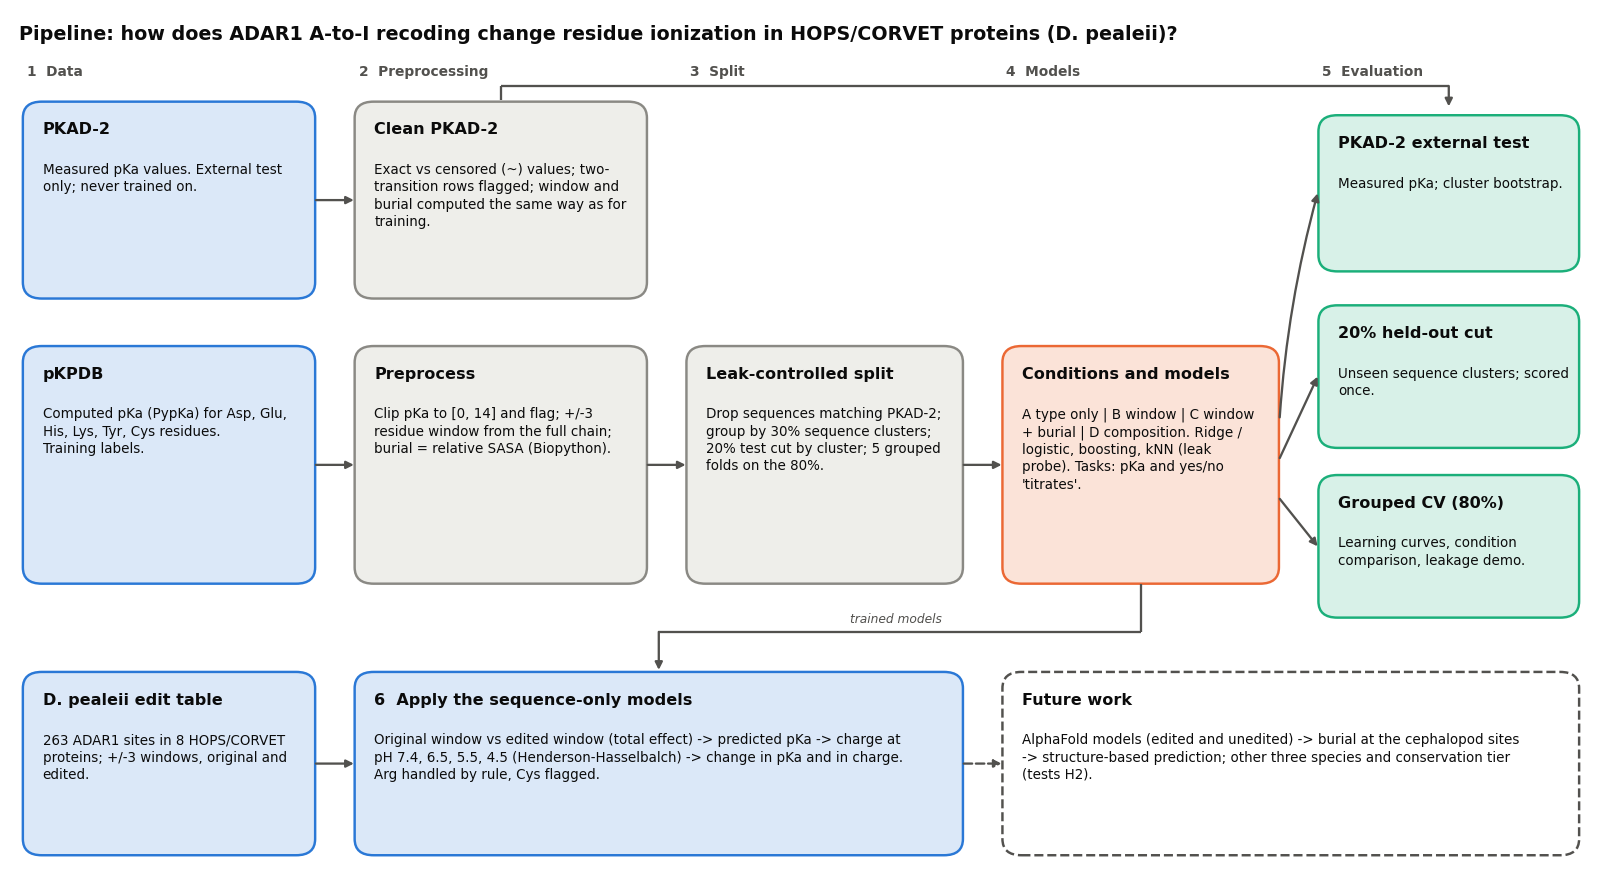

In [2]:
# Figure 0 - pipeline diagram (pure drawing)
INK, MUTED = "#0b0b0b", "#52514e"
FILL = {"data": "#dbe8f8", "prep": "#eeeeea", "model": "#fbe3d8", "eval": "#d8f1e8", "apply": "#dbe8f8"}
EDGE = {"data": "#2a78d6", "prep": "#8a8984", "model": "#eb6834", "eval": "#1baf7a", "apply": "#2a78d6"}

fig, ax = plt.subplots(figsize=(15, 8.2))
ax.set_xlim(0, 100); ax.set_ylim(0, 64); ax.axis("off"); ax.grid(False)

def box(x, y, w, h, title, body, kind, dashed=False):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.25,rounding_size=1.2", fc="white" if dashed else FILL[kind],
                                ec=MUTED if dashed else EDGE[kind], lw=1.6, ls="--" if dashed else "-"))
    ax.text(x + 1, y + h - 1.2, title, fontsize=10.5, fontweight="bold", color=INK, va="top", ha="left")
    ax.text(x + 1, y + h - 4.2, textwrap.fill(body, width=int(w * 2.05)), fontsize=8.8, color=INK, va="top", ha="left", linespacing=1.3)

def arrow(p0, p1, dashed=False, rad=0.0):
    ax.annotate("", xy=p1, xytext=p0, arrowprops=dict(arrowstyle="-|>", color=MUTED, lw=1.5, ls="--" if dashed else "-",
                                                      shrinkA=0, shrinkB=0, connectionstyle=f"arc3,rad={rad}"))
def line(xs, ys): ax.plot(xs, ys, color=MUTED, lw=1.5, solid_capstyle="butt")

ax.text(0.5, 63, "Pipeline: how does ADAR1 A-to-I recoding change residue ionization in HOPS/CORVET proteins (D. pealeii)?",
        fontsize=12.5, fontweight="bold", color=INK, va="top")
for x, t in ((1, "1  Data"), (22, "2  Preprocessing"), (43, "3  Split"), (63, "4  Models"), (83, "5  Evaluation")):
    ax.text(x, 59.2, t, fontsize=9, color=MUTED, fontweight="bold")

box(1, 43, 18, 14, "PKAD-2", "Measured pKa values. External test only; never trained on.", "data")
box(22, 43, 18, 14, "Clean PKAD-2", "Exact vs censored (~) values; two-transition rows flagged; window and burial computed the same way as for training.", "prep")
arrow((19.3, 50), (21.7, 50))
line([31, 31], [57.4, 58.4]); line([31, 91], [58.4, 58.4]); arrow((91, 58.4), (91, 56.9))

box(1, 22, 18, 17, "pKPDB", "Computed pKa (PypKa) for Asp, Glu, His, Lys, Tyr, Cys residues. Training labels.", "data")
box(22, 22, 18, 17, "Preprocess", "Clip pKa to [0, 14] and flag; +/-3 residue window from the full chain; burial = relative SASA (Biopython).", "prep")
box(43, 22, 17, 17, "Leak-controlled split", "Drop sequences matching PKAD-2; group by 30% sequence clusters; 20% test cut by cluster; 5 grouped folds on the 80%.", "prep")
box(63, 22, 17, 17, "Conditions and models", "A type only | B window | C window + burial | D composition. Ridge / logistic, boosting, kNN (leak probe). Tasks: pKa and yes/no 'titrates'.", "model")
arrow((19.3, 30.5), (21.7, 30.5)); arrow((40.3, 30.5), (42.7, 30.5)); arrow((60.3, 30.5), (62.7, 30.5))

box(83, 45, 16, 11, "PKAD-2 external test", "Measured pKa; cluster bootstrap.", "eval")
box(83, 32, 16, 10, "20% held-out cut", "Unseen sequence clusters; scored once.", "eval")
box(83, 19.5, 16, 10, "Grouped CV (80%)", "Learning curves, condition comparison, leakage demo.", "eval")
arrow((80.3, 34), (82.7, 50.5), rad=-0.05); arrow((80.3, 31), (82.7, 37)); arrow((80.3, 28), (82.7, 24.5))

box(1, 2, 18, 13, "D. pealeii edit table", "263 ADAR1 sites in 8 HOPS/CORVET proteins; +/-3 windows, original and edited.", "data")
box(22, 2, 38, 13, "6  Apply the sequence-only models",
    "Original window vs edited window (total effect) -> predicted pKa -> charge at pH 7.4, 6.5, 5.5, 4.5 (Henderson-Hasselbalch) -> change in pKa and in charge. Arg handled by rule, Cys flagged.", "apply")
box(63, 2, 36, 13, "Future work", "AlphaFold models (edited and unedited) -> burial at the cephalopod sites -> structure-based prediction; other three species and conservation tier (tests H2).", "apply", dashed=True)
arrow((19.3, 8.5), (21.7, 8.5)); arrow((60.3, 8.5), (62.7, 8.5), dashed=True)
line([71.5, 71.5], [21.7, 18.2]); line([71.5, 41], [18.2, 18.2]); arrow((41, 18.2), (41, 15.4))
ax.text(56, 18.7, "trained models", fontsize=8, color=MUTED, ha="center", va="bottom", style="italic")
fig.tight_layout(); fig.savefig(FIG_DIR / "fig0_pipeline_diagram.png", dpi=200, bbox_inches="tight"); plt.show()

## 1. Data: Ingestion and preprocessing

So what I had for “personal” data was the Rosenthal lab editing-site spreadsheet (82,975 edited positions across 7,477 D. pealeii transcripts) and the ORF file, which tells me where each protein-coding region sits. In the summer I vibe coded a Colab notebook to replace the manual SnapGene mapping, and here I re-run it as a sanity check. For each edit it works out which codon it lands in and whether the A-to-I change swaps the amino acid. For my 8 HOPS/CORVET proteins that gives 263 edited residues, 168 of which change the amino acid. The problem is that nobody has measured pKa for squid proteins, so I have nothing to train on. Instead I train on pKPDB, which has computed pKa values (from PypKa) for 121,294 PDB structures, and I test on PKAD-2, which has 1,219 pKa values measured in the lab. Those show what happens in reality rather than a prediction, so PKAD-2 is never used for training.

For each residue I then build the features I’d actually have for a squid edit. Residue type is the baseline, since an Asp is acidic and a Lys is basic no matter what surrounds them. The ±3 window is the sequence context, the only thing I can get for an edited site without a 3D structure, so it is what my hypothesis tests. Burial, which is how exposed a residue is to water, comes from the 3D structure and tests whether missing 3D information is what holds sequence back. The main cleaning step was redundancy. The PDB is full of near-identical proteins, so I grouped them by sequence similarity and split by group. Otherwise related proteins end up in both training and test, and the scores look better than they really are.

### 1.1 My data: Rebuilding the Original and Edited proteins 

This step takes the ORF file and the editing-site spreadsheet and works out, for each of my 8 proteins, which amino acid every edit lands in and what it becomes after editing. 

Inosine is read as G, so each edit is an A→G change in the coding sequence (it shows up as T→C on minus-strand transcripts, where the sequence is written as the reverse complement), and edits that fall in the same codon are applied together. 

The output is one row per edited residue with its ±3 amino acid window before and after editing, which is exactly the input the models need later.

In [3]:
# Step 1a - helpers to rebuild the original and edited proteins from the ORF file and the editing-site sheet
TARGETS = {                       # Trinity ID -> protein name (to run other proteins or species, only this changes)
    "comp140826_c0_seq1": "VPS8",
    "comp130514_c0_seq1": "VPS11",
    "comp139341_c2_seq1": "VPS16",
    "comp138338_c0_seq2": "VPS18",
    "comp132862_c0_seq4": "VPS33A",
    "comp129380_c0_seq1": "VPS41",
    "comp130278_c1_seq1": "VPS39",
    "comp140054_c0_seq1": "TGFBRAP1",
}
WINDOW = 3                        # residues on each side of the edited residue
TITRATABLE = set("DEHKRYC")

BASES = "TCAG"
AA_TABLE = "FFLLSSSSYY**CC*WLLLLPPPPHHQQRRRRIIIMTTTTNNKKSSRRVVVVAAAADDEEGGGG"
CODON = {a + b + c: AA_TABLE[i] for i, (a, b, c) in enumerate((x, y, z) for x in BASES for y in BASES for z in BASES)}
_COMP = str.maketrans("ACGTN", "TGCAN")

def read_orfs(path, keep):
    """ORF FASTA header: >id<tab>OrfStart<tab>N<tab>OrfEnd<tab>N<tab>Strand<tab>+/-<tab>description. Keeps only `keep`."""
    orfs, name = {}, None
    with open(path) as fh:
        for line in fh:
            line = line.rstrip("\n")
            if line.startswith(">"):
                f = line[1:].split("\t")
                name = f[0] if f[0] in keep else None
                if name:
                    orfs[name] = {"start": int(f[2]), "end": int(f[4]), "strand": f[6], "seq": []}
            elif name:
                orfs[name]["seq"].append(line.strip())
    for o in orfs.values():
        o["seq"] = "".join(o["seq"]).upper()
    return orfs

def revcomp(s):
    return s.translate(_COMP)[::-1]

def translate(cds):
    return "".join(CODON.get(cds[i:i + 3], "X") for i in range(0, len(cds) - 2, 3))

def base_pair(strand):
    """(unedited base, edited base) as written: A->G on the plus strand, T->C on the minus strand."""
    return ("A", "G") if strand == "+" else ("T", "C")

def locate(o, pos):
    """Position as written -> (0-based codon index, 0-based position inside the codon)."""
    if o["strand"] == "+":
        return (pos - o["start"]) // 3, (pos - o["start"]) % 3
    return (o["end"] - pos) // 3, (o["end"] - pos) % 3

def build_cds(o, positions, state):
    """Coding sequence with every edited position set to its 'original' or 'edited' base."""
    unedited, edited = base_pair(o["strand"])
    seq = list(o["seq"])
    for p in positions:
        seq[p - 1] = unedited if state == "original" else edited
    seq = "".join(seq)[o["start"] - 1:o["end"]]
    return seq if o["strand"] == "+" else revcomp(seq)

def window(prot, idx, k=WINDOW):
    """k residues each side of idx, padded with '-' at the protein ends. The focal residue sits in the middle."""
    return "".join(prot[j] if 0 <= j < len(prot) else "-" for j in range(idx - k, idx + k + 1))

In [4]:
# Step 1b - one row per edited residue with its +/-3 windows; sanity checks; save the table and a FASTA
RUN_STEP1 = ORF_FILE.is_file() and SITES_FILE.is_file()
if RUN_STEP1:
    orfs = read_orfs(ORF_FILE, TARGETS)
    missing = set(TARGETS) - set(orfs)
    if missing:
        print("WARNING - not found in the ORF file:", missing)

    raw = pd.read_excel(SITES_FILE)
    raw.columns = [c.strip() for c in raw.columns]                    # headers have stray spaces
    raw = raw.rename(columns={"Trinity name": "transcript", "Editing location inside sequence": "position",
                              "Codon changes": "excel_codon_change", "RNA reads: G": "rna_G", "RNA reads: A": "rna_A",
                              "DNA reads: G": "dna_G", "DNA reads: A": "dna_A"})
    raw["editing_pct"] = 100 * raw["rna_G"] / (raw["rna_G"] + raw["rna_A"])   # the sheet's column is a formula
    print(f"Excel rows in total: {len(raw):,} | transcripts: {raw['transcript'].nunique():,}")

    sites = raw[raw["transcript"].isin(TARGETS)].copy()
    sites["position"] = sites["position"].astype(int)
    sites["protein"] = sites["transcript"].map(TARGETS)
    sites["in_orf"] = [orfs[t]["start"] <= p <= orfs[t]["end"] for t, p in zip(sites["transcript"], sites["position"])]
    inside = sites[sites["in_orf"]].copy()
    loc = [locate(orfs[t], p) for t, p in zip(inside["transcript"], inside["position"])]
    inside["codon_idx"] = [l[0] for l in loc]
    inside["codon_pos"] = [l[1] + 1 for l in loc]
    inside["orf_base"] = [orfs[t]["seq"][p - 1] for t, p in zip(inside["transcript"], inside["position"])]

    proteins = {}
    for t, o in orfs.items():
        pos = inside.loc[inside["transcript"] == t, "position"].tolist()
        cds_o, cds_e = build_cds(o, pos, "original"), build_cds(o, pos, "edited")
        assert len(cds_o) % 3 == 0, f"{TARGETS[t]}: ORF length is not a multiple of 3"
        proteins[t] = {"cds_original": cds_o, "cds_edited": cds_e,
                       "prot_original": translate(cds_o), "prot_edited": translate(cds_e)}

    rows = []
    for (t, ci), g in inside.groupby(["transcript", "codon_idx"]):
        o, p = orfs[t], proteins[t]
        cod_o, cod_e = p["cds_original"][3 * ci:3 * ci + 3], p["cds_edited"][3 * ci:3 * ci + 3]
        aa_o, aa_e = CODON.get(cod_o, "X"), CODON.get(cod_e, "X")
        rows.append({"protein": TARGETS[t], "transcript": t, "strand": o["strand"], "residue_number": ci + 1,
                     "orig_aa": aa_o, "edited_aa": aa_e, "synonymous": aa_o == aa_e,
                     "orig_codon": cod_o, "edited_codon": cod_e, "n_edits_in_codon": len(g),
                     "codon_positions_edited": ",".join(map(str, sorted(g["codon_pos"]))),
                     "nt_positions": ",".join(map(str, sorted(g["position"]))),
                     "excel_codon_changes": ",".join(g["excel_codon_change"].astype(str)),
                     "editing_pct_max": round(g["editing_pct"].max(), 2),
                     "editing_pct_all": ",".join(f"{x:.1f}" for x in g["editing_pct"]),
                     "any_ge50": bool((g["editing_pct"] >= 50).any()),
                     "orig_titratable": aa_o in TITRATABLE, "edited_titratable": aa_e in TITRATABLE,
                     "before_first_Met": ci < p["prot_original"].find("M"),
                     "window_original": window(p["prot_original"], ci), "window_edited": window(p["prot_edited"], ci)})
    residues = pd.DataFrame(rows).sort_values(["protein", "residue_number"]).reset_index(drop=True)
    edited_idx = residues.groupby("transcript")["residue_number"].apply(set).to_dict()
    residues["n_other_edited_in_window"] = [
        sum(1 for j in range(r - WINDOW, r + WINDOW + 1) if j != r and j in edited_idx[t])
        for t, r in zip(residues["transcript"], residues["residue_number"])]

    # ---- sanity checks ----
    print("\n1. Row counts at each stage")
    att = pd.DataFrame({"excel_rows": sites.groupby("protein").size(),
                        "outside_ORF": sites[~sites["in_orf"]].groupby("protein").size(),
                        "edited_residues": residues.groupby("protein").size(),
                        "multi_edit_residues": residues[residues["n_edits_in_codon"] > 1].groupby("protein").size(),
                        "synonymous": residues[residues["synonymous"]].groupby("protein").size(),
                        "any_ge50": residues[residues["any_ge50"]].groupby("protein").size(),
                        "before_first_Met": residues[residues["before_first_Met"]].groupby("protein").size()}).fillna(0).astype(int)
    att.loc["TOTAL"] = att.sum()
    print(att.to_string())

    print("\n2. Base shown in the ORF file at each edited position")
    unedited, edited = zip(*[base_pair(orfs[t]["strand"]) for t in inside["transcript"]])
    state = ["unedited-looking" if b == u else "edited-looking" if b == e else "other"
             for b, u, e in zip(inside["orf_base"], unedited, edited)]
    print(pd.crosstab(pd.Series(state, name="base in ORF file", index=inside.index),
                      inside["editing_pct"].ge(50).rename("editing >= 50%")).to_string())

    print("\n3. Our residue change vs the sheet's codon-change column (single-edit codons)")
    single = residues[residues["n_edits_in_codon"] == 1]
    match = [("syn" if r.synonymous else r.orig_aa + r.edited_aa) == r.excel_codon_changes for r in single.itertuples()]
    print(f"{sum(match)} of {len(match)} agree")

    print("\n4. Rebuilt edited protein vs my summer file of edited proteins")
    if ENDO_FILE.is_file():
        endo, name = {}, None
        for line in open(ENDO_FILE):
            line = line.strip()
            if line.startswith(">"):
                name = line[1:].split()[0]; endo[name] = ""
            elif name and line.isalpha():                   # skips stray text lines in that file
                endo[name] += line
        multi_idx = {t: set(g.loc[g["n_edits_in_codon"] > 1, "residue_number"] - 1) for t, g in residues.groupby("transcript")}
        out = []
        for t, p in proteins.items():
            ref_, mine = endo.get(t, "").upper(), p["prot_edited"]
            diff = [i for i in range(min(len(ref_), len(mine))) if ref_[i] != mine[i]]
            out.append({"protein": TARGETS[t], "length_ours": len(mine), "length_file": len(ref_),
                        "positions_that_differ": len(diff),
                        "of_which_in_multi_edit_codons": sum(i in multi_idx.get(t, set()) for i in diff)})
        print(pd.DataFrame(out).to_string(index=False))
    else:
        print("(summer file not found - skipped)")

    residues.to_csv(EDITED_CSV, index=False)
    with open(FASTA, "w") as fh:
        for t, p in proteins.items():
            fh.write(f">{TARGETS[t]}|{t}\n{p['prot_original'].replace('*', '')}\n")
    print(f"\nSaved {EDITED_CSV} ({len(residues)} edited residues) and {FASTA}")
else:
    for src, dst in ((DATA / "edited_residues_DP (2).csv", EDITED_CSV), (DATA / "hops_corvet_proteins.fasta", FASTA)):
        if not dst.is_file() and src.is_file():
            dst.write_bytes(src.read_bytes())
    print("Raw Step-1 files not found; using the saved outputs of my Step-1 run instead:", EDITED_CSV, FASTA)
ed = pd.read_csv(EDITED_CSV)
print(f"Edited residues: {len(ed)} | nonsynonymous: {int((~ed['synonymous']).sum())} | synonymous: {int(ed['synonymous'].sum())}")

Excel rows in total: 82,975 | transcripts: 7,477

1. Row counts at each stage
          excel_rows  outside_ORF  edited_residues  multi_edit_residues  synonymous  any_ge50  before_first_Met
protein                                                                                                        
TGFBRAP1          32            0               29                    3           9         5                 0
VPS11             27            0               25                    2           8         0                 0
VPS16             15            0               15                    0           6         0                 0
VPS18             45            0               40                    3          16         1                 0
VPS33A            13            0               13                    0           5         0                 0
VPS39              7            0                7                    0           1         1                 0
VPS41             26      

The checks shows that the rebuild holds up and that the 287 edit rows collapse into 263 edited residues (20 codons carry more than one edit), of which 168 change the amino acid and 95 don’t, and for all 243 single-edit codons my result agrees with the sheet’s own codon-change column. 

The ORF file shows the unedited base at every site except a few highly edited ones (≥50%), where the assembly picked up the edited base, and the code handles both cases. 

My rebuilt proteins also match my summer file everywhere except inside multi-edit codons, which the summer code handled differently. 

### 1.2 Training labels: pKPDB

So here, pKPDB is a table of computed pKa values, calculated with PypKa, for the titratable residues in PDB structures. These are my training labels, since nobody has measured pKa for squid proteins and I need many residues with a pKa to learn from so I can predict that for my proteins. 

Before removing anything I wanted to see what is in it, so that any later exclusion from the data set to prevent leakage has a reason and I know which residue types the labels can actually cover. 

#context: A titratable residue is one whose side chain can gain or lose a proton, so its charge depends on pH. 

pKPDB has Asp, Glu, His, Lys, Tyr and Cys, whose typical pKa values run from about 3.7 for Asp to about 10.5 for **Lys** **Asp**, **Glu** and **His** are the ones that matter most for my question, since their pKa values sit in or near the endosomal range of 7.4 to 4.5, so their charge can actually change as the endosome matures. 

**Arg** is not in the table. Its pKa is around 12.5, far above any pH I care about, so it is essentially always charged. 

I need to come up with a simple rule for it later, because an edit can change a residue into or out of Arg. The N- and C-terminus rows (449,943 of them) are out of scope, because my edits sit inside the protein, so it don't matter here. 

Rows: 12,628,148 | PDB entries: 121,294
Residue names: {'GLU': 3136638, 'LYS': 2835787, 'ASP': 2777824, 'TYR': 1752643, 'HIS': 1180175, 'CYS': 495138, 'CTR': 231202, 'NTR': 218741}

Distribution per residue type (before any removal):
               n   min  p0.1%   p1%  median   p99%  p99.9%    max  share <0  share >14
residue                                                                               
ASP      2777824 -6.00  -3.89 -1.65    3.04   5.53    9.15  19.66      0.04       0.00
CYS       495138  2.05   6.22  7.97   11.34  16.62   18.88  19.99      0.00       0.08
GLU      3136638 -6.00  -3.19 -0.59    3.75   6.01    9.96  19.36      0.02       0.00
HIS      1180175 -6.00  -2.78  0.66    6.11   8.97   12.08  18.99      0.01       0.00
LYS      2835787 -2.74   8.08  9.33   10.86  14.14   17.07  20.00      0.00       0.01
TYR      1752643  3.39   8.11  9.01   11.40  18.01   19.63  20.00      0.00       0.16


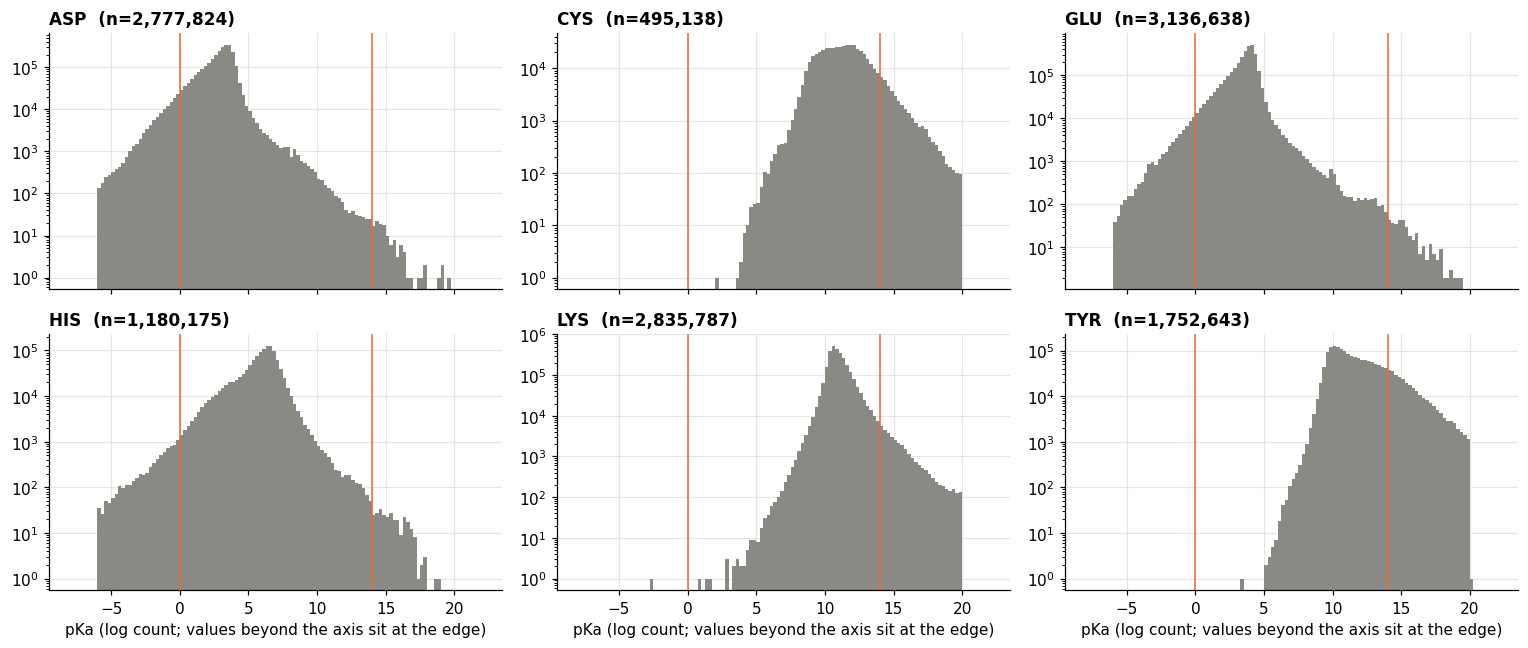

In [5]:
# pKPDB - load and look (nothing is removed yet)
with open(PKA_FILE, "r", errors="replace") as f:
    header = f.readline()
DELIM = max([",", ";", "\t", "|"], key=header.count)
pk = pd.read_csv(PKA_FILE, sep=DELIM)
pk.columns = [re.sub(r"[^a-z0-9]+", "_", str(c).strip().lower()).strip("_") for c in pk.columns]
ALIASES = {"idcode": ["idcode", "pdb", "pdb_id", "pdbid", "id"], "chain": ["chain", "chain_id"],
           "residue_name": ["residue_name", "resname", "res_name", "residue", "name"],
           "residue_number": ["residue_number", "resnum", "res_num", "res_id", "resid", "number"],
           "pk": ["pk", "pka", "pk_value", "pka_value"]}
rename = {}
for std, options in ALIASES.items():
    hit = [c for c in pk.columns if c in options]
    if not hit:
        raise KeyError(f"No column for {std!r}. Columns found: {list(pk.columns)}")
    rename[hit[0]] = std
pk = pk.rename(columns=rename)[list(ALIASES)]
pk["residue_name"] = pk["residue_name"].astype(str).str.strip().str.upper()
pk["idcode"] = pk["idcode"].astype("category")
pk["chain"] = pk["chain"].astype("category")
print(f"Rows: {len(pk):,} | PDB entries: {pk['idcode'].nunique():,}")
print("Residue names:", pk["residue_name"].value_counts().to_dict())

inscope = pk[pk["residue_name"].isin(SCOPE)]
rows = []
for name, g in inscope.groupby("residue_name", observed=True):
    q = g["pk"].quantile([0.001, 0.01, 0.5, 0.99, 0.999])
    rows.append({"residue": name, "n": len(g), "min": g["pk"].min(), "p0.1%": q[0.001], "p1%": q[0.01],
                 "median": q[0.5], "p99%": q[0.99], "p99.9%": q[0.999], "max": g["pk"].max(),
                 "share <0": (g["pk"] < 0).mean(), "share >14": (g["pk"] > 14).mean()})
print("\nDistribution per residue type (before any removal):")
print(pd.DataFrame(rows).set_index("residue").round(2).to_string())

types_present = sorted(inscope["residue_name"].unique())
fig, axes = plt.subplots(2, 3, figsize=(14, 6), sharex=True)
for ax, name in zip(axes.ravel(), types_present):
    g = inscope.loc[inscope["residue_name"] == name, "pk"]
    ax.hist(g.clip(-8, 22), bins=120, range=(-8, 22), color=GREY)
    ax.set_yscale("log"); ax.axvline(0, color=ORANGE, lw=1); ax.axvline(14, color=ORANGE, lw=1)
    ax.set_title(f"{name}  (n={len(g):,})", loc="left")
for ax in axes.ravel()[len(types_present):]:
    ax.axis("off")
for ax in axes[-1]:
    ax.set_xlabel("pKa (log count; values beyond the axis sit at the edge)")
fig.tight_layout(); plt.show()

The distributions look like what the chemistry should give us. Each residue peaks near its textbook pKa (Asp and Glu around 3 to 4, His around 6.5, Lys and Tyr around 10 to 11), which tells me that the computed labels behave sensibly. 

What stands out as weird here is the long smooth tails below 0 and above 14. For example, 16.2% of Tyr values are above 14. Only about 75 values pile up at the very edge of the scanned window, so these tails are not glitches from the calculation running out of range. 

They are real outputs, probably from residues and from brief google research they might be in very buried or crowded spots whose pKa gets pushed too far from normal. A pKa outside 0 to 14 is hard to interpret in water, so I have to decide what to do with those values. This motivated the clipping and cleaning step below. 

In [6]:
# pKPDB - the numbers behind the clipping decision, then the cleaning itself
edge = (inscope.assign(at_low_edge=inscope["pk"] <= -5.99, at_high_edge=inscope["pk"] >= 19.99)
        .groupby("residue_name", observed=True)[["at_low_edge", "at_high_edge"]].sum())
print("Values stuck at the edges of the scanned window:\n" + edge.to_string())
band = pd.cut(inscope["pk"], [-np.inf, 0, IN_LO, IN_HI, 14, np.inf],
              labels=["<0", f"0-{IN_LO}", f"{IN_LO}-{IN_HI} (titrates)", f"{IN_HI}-14", ">14"], right=False)
print("\n% of each residue type per pKa band:\n" +
      pd.crosstab(inscope["residue_name"], band, normalize="index").mul(100).round(1).to_string())

def hh_charge(pk_, pH, acid):
    """Henderson-Hasselbalch charge of one residue."""
    return -1 / (1 + 10.0 ** (pk_ - pH)) if acid else 1 / (1 + 10.0 ** (pH - pk_))
ACID3 = {"ASP", "GLU", "CYS", "TYR"}
worst = {name: max(np.abs(hh_charge(g["pk"].to_numpy(), pH, name in ACID3) -
                          hh_charge(np.clip(g["pk"].to_numpy(), 0, 14), pH, name in ACID3)).max() for pH in PH)
         for name, g in inscope.groupby("residue_name", observed=True)}
print("\nLargest change in charge that clipping to [0, 14] causes at pH 7.4-4.5:", {k: f"{v:.1e}" for k, v in worst.items()})

PK_MIN, PK_MAX = 0.0, 14.0
log("=== pKPDB cleaning ===")
log(f"Values outside [{PK_MIN}, {PK_MAX}] are clipped (kept and flagged), not dropped.")
in_scope = pk["residue_name"].isin(SCOPE)
log(f"Dropped by residue name (termini / out of scope): {pk.loc[~in_scope, 'residue_name'].value_counts().to_dict()}")
log(f"Dropped for missing pK: {int((in_scope & pk['pk'].isna()).sum()):,}")
clean = pk[in_scope & pk["pk"].notna()].copy()
clean["pk_raw"] = clean["pk"]
clean["pk_clipped"] = (clean["pk"] < PK_MIN) | (clean["pk"] > PK_MAX)
attr = pd.DataFrame(index=sorted(SCOPE))
attr["rows"] = clean.groupby("residue_name").size()
attr["below min"] = clean[clean["pk"] < PK_MIN].groupby("residue_name").size()
attr["above max"] = clean[clean["pk"] > PK_MAX].groupby("residue_name").size()
attr = attr.fillna(0).astype(int)
attr["% clipped"] = (100 * (attr["below min"] + attr["above max"]) / attr["rows"].replace(0, np.nan)).round(2)
clean["pk"] = clean["pk"].clip(PK_MIN, PK_MAX)
log("Rows per residue type:\n" + attr.to_string())
absent = [r for r in sorted(SCOPE) if r not in set(clean["residue_name"])]
if absent:
    log(f"Residue types with NO rows in pKPDB: {absent} -> need a separate rule when applying the models")
clean["aa"] = clean["residue_name"].map(SCOPE)
clean["pdb"] = clean["idcode"].astype(str).str.upper()
log(f"Duplicate (entry, chain, number, type) keys: {clean.duplicated(['pdb', 'chain', 'residue_number', 'residue_name']).sum():,}")
log(f"Clean pKPDB: {len(clean):,} residues from {clean['pdb'].nunique():,} PDB entries")

Values stuck at the edges of the scanned window:
              at_low_edge  at_high_edge
residue_name                           
ASP                     6             0
CYS                     0             2
GLU                     4             0
HIS                     1             0
LYS                     0             5
TYR                     0            57

% of each residue type per pKa band:
pk             <0  0-3.5  3.5-8.4 (titrates)  8.4-14   >14
residue_name                                              
ASP           4.3   67.2                28.4     0.2   0.0
CYS           0.0    0.0                 2.1    90.2   7.7
GLU           1.7   36.8                61.3     0.2   0.0
HIS           0.6    8.7                88.8     1.8   0.0
LYS           0.0    0.0                 0.2    98.7   1.1
TYR           0.0    0.0                 0.2    83.6  16.2

Largest change in charge that clipping to [0, 14] causes at pH 7.4-4.5: {'ASP': '3.2e-05', 'CYS': '2.5e-07', 'GLU': '3.2

I did not delete the pKa values that fall below 0 or above 14. Instead I changed them: anything above 14 is set to 14, and anything below 0 is set to 0 which is called clipping. 

This does not hurt the project, because a pKa that low or that high means the residue is fully charged or fully uncharged across the whole pH range I care about (4.5 to 7.4) either way. I tested this, and the change moves the charge by almost nothing (at most 0.00003). If I had deleted these rows, I would have lost the clearest examples of residues that don’t change charge in this range, and I need those for the yes/no part of the project. 

As a precuation, I also kept the original values in a separate column called pk_raw and marked every changed row in pk_clipped, so no information is lost if I need it later on. After this step I have 12,178,205 residues from 121,007 PDB entries, and no residue appears twice.

### 1.3 Test labels: PKAD-2 (measured pKa)

PKAD-2 here is my measured test set, and its values are messier than the computed ones. Of the 1,219 rows I read, most are an exact number, but some are only a limit (like <4 or >10), 12 are approximate (like ~6), and 2 entries gave two values because the residue has two transitions, so I split each into two rows. I didn’t guess what any of these meant. 

I kept every value as reported and added a flag for its type. I dropped 21 rows for N- or C-terminus residues, because my edits sit inside the protein. That left me with 1,200 rows covering 1,171 residues from 164 PDB entries. Of these, 1,140 are exact numbers, 46 are upper limits and 35 are lower limits. 19 residues were measured more than once and I kept all the repeats, giving each a weight of 1 divided by the number of measurements of that kind, so each residue counts once overall. The repeats mostly agree, with a median difference of 0.12 pKa units, although the largest is 1.99, and one residue has 10 separate measurements.

In [7]:
# PKAD-2 - cleaning (censored values kept and flagged; repeated measurements kept and weighted)
log("\n=== PKAD-2 cleaning ===")
pkad = pd.read_csv(PKAD_FILE, dtype=str, keep_default_na=False)
def norm(c):                                     # "Expt. pKa" -> "exptpka", "%SASA" -> "sasa"
    return re.sub(r"[^a-z0-9]", "", c.lower())
cols = {norm(c): c for c in pkad.columns}
def col(key):
    if key in cols:
        return cols[key]
    hits = [orig for simple, orig in cols.items() if simple.startswith(key)]
    if not hits:
        raise KeyError(f"Column {key!r} not found. Columns are: {list(pkad.columns)}")
    return hits[0]

d = pd.DataFrame({"record_id": pkad[col("recordid")], "pdb": pkad[col("pdbid")].str.strip().str.upper(),
                  "chain": pkad[col("chain")].str.strip(), "resno": pkad[col("resid")].str.strip(),
                  "res_name": pkad[col("resname")].str.strip().str.upper(), "pka_raw": pkad[col("exptpka")].str.strip(),
                  "unc_raw": pkad[col("exptuncertainty")].str.strip(),
                  "sasa_pkad": pd.to_numeric(pkad[col("sasa")].str.replace("%", "", regex=False), errors="coerce"),
                  "method": pkad[col("exptmethod")].str.strip(), "salt": pkad[col("exptsalt")].str.strip(),
                  "ph_range": pkad[col("exptph")].str.strip(), "temp": pkad[col("expttemp")].str.strip()})
log(f"Rows read: {len(d):,}")

# pKa text -> number + flag: "6.2" exact | "<2.0" upper bound | ">10" lower bound | "~4" approximate | "2.21,6.54" two transitions
NUM = r"-?\d+(?:\.\d+)?"
KIND = {"<": "upper_bound", ">": "lower_bound", None: "exact"}
def parse_pka(s):
    m = re.fullmatch(rf"([<>])?\s*({NUM})", s.strip())
    if m:
        return [(float(m.group(2)), KIND[m.group(1)], False, False)]
    m = re.fullmatch(rf"~\s*({NUM})", s.strip())
    if m:
        return [(float(m.group(1)), "exact", True, False)]
    m = re.fullmatch(rf"({NUM})\s*,\s*({NUM})", s.strip())
    if m:
        return [(float(m.group(1)), "exact", False, True), (float(m.group(2)), "exact", False, True)]
    return None
d["_parsed"] = d["pka_raw"].map(parse_pka)
unparsed = d["_parsed"].isna()
if unparsed.any():
    log(f"Unparseable pKa strings (dropped): {d.loc[unparsed, 'pka_raw'].value_counts().to_dict()}")
d = d[~unparsed].explode("_parsed").reset_index(drop=True)
for i, c_ in enumerate(["pka", "kind", "approximate", "multi_transition"]):
    d[c_] = d["_parsed"].map(lambda t: t[i])
d = d.drop(columns="_parsed")
log("pKa value types: " + str(d["kind"].value_counts().to_dict()))
log(f"Approximate ('~') values kept: {int(d['approximate'].sum())}; rows from two-transition entries: {int(d['multi_transition'].sum())}")

def parse_unc(s):                                # number -> itself, "a-b" -> midpoint, N/A -> missing (never 0)
    s = s.replace("±", "").strip()
    m = re.fullmatch(rf"({NUM})", s)
    if m:
        return float(m.group(1))
    m = re.fullmatch(rf"({NUM})\s*-\s*({NUM})", s)
    return (float(m.group(1)) + float(m.group(2))) / 2 if m else np.nan
d["unc"] = d["unc_raw"].map(parse_unc)
log(f"Uncertainty: {d['unc'].notna().sum():,} numeric, {d['unc'].isna().sum():,} missing (used only in a sensitivity check)")

is_term = d["res_name"].str.contains("TERM|^N$|^C$", regex=True)
log(f"Dropped termini rows: {is_term.sum():,}")
d = d[~is_term]
out_scope = ~d["res_name"].isin(SCOPE)
if out_scope.any():
    log(f"Dropped out-of-scope residue names: {d.loc[out_scope, 'res_name'].value_counts().to_dict()}")
d = d[~out_scope].copy()
d["aa"] = d["res_name"].map(SCOPE)

# several values for one residue: keep all rows, weight = 1 / (rows of the same kind for that residue)
d["residue_key"] = d["pdb"] + "|" + d["chain"] + "|" + d["resno"] + "|" + d["aa"]
d["n_same_kind"] = d.groupby(["residue_key", "kind"])["pka"].transform("size")
d["weight"] = 1.0 / d["n_same_kind"]
ex = d[(d["kind"] == "exact") & ~d["multi_transition"]]
per_res = ex.groupby("residue_key")["pka"].agg(["size", lambda s: s.max() - s.min()])
per_res.columns = ["n_values", "spread"]
log(f"Exact-value residues: {len(per_res):,} | values per residue: {per_res['n_values'].value_counts().sort_index().to_dict()}")
multi = per_res[per_res["n_values"] > 1]
if len(multi):
    log(f"Residues with >1 exact value: {len(multi)}; median spread {multi['spread'].median():.2f}; largest {multi['spread'].max():.2f}")
log("Censored rows (kept, scored separately): " + str(d[d["kind"] != "exact"].groupby(["aa", "kind"]).size().to_dict()))
log("Rows per residue type: " + str(d["aa"].value_counts().to_dict()))
log(f"Clean PKAD-2: {len(d):,} rows, {d['residue_key'].nunique():,} residues, {d['pdb'].nunique():,} PDB entries")
pkad_clean = d


=== PKAD-2 cleaning ===
Rows read: 1,219
pKa value types: {'exact': 1140, 'upper_bound': 46, 'lower_bound': 35}
Approximate ('~') values kept: 12; rows from two-transition entries: 4
Uncertainty: 909 numeric, 312 missing (used only in a sensitivity check)
Dropped termini rows: 21
Exact-value residues: 1,088 | values per residue: {1: 1069, 2: 18, 10: 1}
Residues with >1 exact value: 19; median spread 0.12; largest 1.99
Censored rows (kept, scored separately): {('C', 'lower_bound'): 2, ('C', 'upper_bound'): 1, ('D', 'upper_bound'): 25, ('H', 'lower_bound'): 1, ('H', 'upper_bound'): 20, ('K', 'lower_bound'): 12, ('Y', 'lower_bound'): 20}
Rows per residue type: {'E': 388, 'D': 353, 'H': 248, 'K': 142, 'Y': 47, 'C': 22}
Clean PKAD-2: 1,200 rows, 1,171 residues, 164 PDB entries


### 1.4 How good are the training labels?

So the way I was designing this pipeline was so that everything my models learn comes from PypKa, not from the experiment. Given the advice from Prof Watson about doing a "Apples to Apples comparsion", even before building any models I checked how well PypKa itself matches measured values. 

On the 996 residues where I have both (exact measurements only), PypKa is off by 0.75 pKa units on average (that’s the MAE, the average size of the miss). Guessing the average pKa for each residue type is off by 0.92, so PypKa is about 19% better. It isn’t better everywhere or for every residue. 

For Lys it is 11% worse than the type average, and for Cys it is very poor, with an average miss of 3.38 and a habit of reading about 2.9 too high. This matters because it roughly sets a ceiling. A model that copied PypKa perfectly would still miss the measured values by about 0.75, so I shouldn’t expect much better than that on PKAD-2.

### Metric: mean absolute error (MAE)

I use MAE to measure how far a model's pKa is from the true pKa. For each residue I take the difference between the predicted and the true value, drop the minus sign, and average over all residues:

$$\mathrm{MAE} = \frac{1}{n}\sum_{i=1}^{n}\left|\hat{y}_i - y_i\right|$$

where $y_i$ is the true pKa of residue $i$, $\hat{y}_i$ is the predicted pKa, and $n$ is the number of residues. The result is in pKa units, so an MAE of 0.75 means the prediction is off by 0.75 pKa units on average.

The minus sign is dropped so that overshoots and undershoots do not cancel out. For example, with true values 4.0, 6.5, 3.5 and predictions 4.5, 6.0, 4.7, the misses are +0.5, −0.5 and +1.2, so the MAE is (0.5 + 0.5 + 1.2) / 3 ≈ 0.73. Without the absolute value, the first two misses would cancel and the error would look much smaller.

### Baseline and gain over the type average

An MAE on its own is hard to judge, so I always compare it to a simple baseline: predicting the average pKa of the residue's type (for example, every Asp gets the same value). I call this the *type average*, and its MAE is $\mathrm{MAE}_A$. For a model $M$ with error $\mathrm{MAE}_M$, I report the gain over the type average:

$$G = 100\left(1 - \frac{\mathrm{MAE}_M}{\mathrm{MAE}_A}\right)$$

$G$ is the percentage by which the model's error is smaller than the baseline's. $G > 0$ means the model beats the baseline, $G = 0$ means it does no better, and $G < 0$ means it is worse than just guessing the average.

For example, PypKa has $\mathrm{MAE}_M = 0.75$ against measured values and the type average has $\mathrm{MAE}_A = 0.92$, so $G = 100(1 - 0.75/0.92) \approx 19\%$.

MAE treats every miss equally, so a few large misses and many small ones with the same total give the same MAE. For that reason I also report MAE separately for each residue type, which shows where the errors are concentrated.

In [8]:
# How close are the training labels (PypKa calculations) to experiment? PKAD-2 is only looked at here, never trained on.
both = set(pkad_clean["pdb"]) & set(clean["pdb"])
calc = clean.loc[clean["pdb"].isin(both), ["pdb", "chain", "residue_number", "aa", "pk_raw"]].copy()
calc["chain"] = calc["chain"].astype(str)
calc["resno"] = calc["residue_number"].astype(str)
calc = calc.rename(columns={"pk_raw": "pk_calc"}).drop(columns="residue_number")
shared = pkad_clean[pkad_clean["pdb"].isin(both)].copy()
shared["chain"] = shared["chain"].astype(str)
m = shared.merge(calc, on=["pdb", "chain", "resno", "aa"], how="left")
assert len(m) == len(shared), "pKPDB keys not unique"
log("\n=== pKPDB vs PKAD-2 (entries present in both) ===")
log(f"PKAD-2 rows in shared entries: {len(shared):,}; matched to a pKPDB residue: {int(m['pk_calc'].notna().sum()):,}")

good = m[m["pk_calc"].notna() & (m["kind"] == "exact") & ~m["approximate"] & ~m["multi_transition"]].copy()
type_mean = clean.groupby("aa")["pk"].mean()
good["pk_base"] = good["aa"].map(type_mean)
def summarize(g):
    w, e = g["weight"].to_numpy(), g["pka"].to_numpy()
    dlt = g["pk_calc"].to_numpy() - e
    return pd.Series({"rows": len(g), "MAE calc": np.average(np.abs(dlt), weights=w),
                      "bias (calc - exp)": np.average(dlt, weights=w),
                      "Pearson r": np.corrcoef(e, g["pk_calc"])[0, 1] if len(g) > 2 else np.nan,
                      "MAE type-average": np.average(np.abs(g["pk_base"] - e), weights=w)})
tab = good.groupby("aa").apply(summarize, include_groups=False)
tab.loc["ALL"] = summarize(good)
tab["improvement over type-average"] = 1 - tab["MAE calc"] / tab["MAE type-average"]
log("Calculated (pKPDB) vs experimental (PKAD-2), exact values:\n" + tab.round(2).to_string())

cens = m[m["pk_calc"].notna() & m["kind"].isin(["upper_bound", "lower_bound"])].copy()
if len(cens):
    cens["bound_satisfied"] = np.where(cens["kind"] == "upper_bound", cens["pk_calc"] < cens["pka"], cens["pk_calc"] > cens["pka"])
    log("Censored values - share where the calculation respects the bound:\n" +
        cens.groupby(["aa", "kind"])["bound_satisfied"].agg(["size", "mean"]).round(2).to_string())


=== pKPDB vs PKAD-2 (entries present in both) ===
PKAD-2 rows in shared entries: 1,119; matched to a pKPDB residue: 1,088
Calculated (pKPDB) vs experimental (PKAD-2), exact values:
      rows  MAE calc  bias (calc - exp)  Pearson r  MAE type-average  improvement over type-average
aa                                                                                                 
C     12.0      3.38               2.94       0.05              5.39                           0.37
D    278.0      0.73              -0.27       0.60              0.92                           0.21
E    352.0      0.72              -0.46       0.47              0.80                           0.10
H    209.0      0.74              -0.25       0.48              1.07                           0.31
K    123.0      0.62               0.13       0.26              0.56                          -0.11
Y     22.0      0.64              -0.46       0.44              1.13                           0.43
ALL  996.0      0.

### 1.5 Redundancy: near-identical structures

My first attempt was to group the structures using pKPDB’s 90% similarity file. I merged every pair that the file listed as similar. The problem was chaining: if A is similar to B and B is similar to C, all three merge, even when A and C are quite different. Over 121,000 entries these chains kept growing until one giant group held 42,005 entries, which is useless for splitting data into training and test sets, so I dropped this approach. 

I replaced it in two steps. First, in the cell below, I picked one representative for each set of near-identical structures, without letting the groups chain together. That left 32,073 representatives (26.5% of the entries), and I used them to decide which structures to download, since downloading and processing every one would have taken far too long. Second, in the next cell, I switched to the RCSB 30% sequence-identity clusters, which put proteins that share at least 30% sequence identity into the same group, even distant relatives. These are the groups I use for every train/test split, so that no test protein has a close or distant relative in training.

In [9]:
# Redundancy 1 - pick representative PDB entries from the 90% similarity file (greedy, no chaining)
# Walk through the file: an entry that is not yet covered becomes a representative and covers everything on its line.
entries = pd.DataFrame({"pdb_lc": sorted(set(clean["pdb"].str.lower()))})
entries["pdb"] = entries["pdb_lc"].str.upper()
valid_set = set(entries["pdb_lc"])
covered, reps = set(), []
with open(SIM_FILE, "r", errors="replace") as f:
    next(f)
    for line_ in f:
        head_, _, rest = line_.strip().partition(";")
        if head_ not in valid_set or head_ in covered:
            continue
        reps.append(head_)
        covered.add(head_)
        covered.update(t for t in rest.split(",") if t in valid_set)
leftover = [p for p in entries["pdb_lc"] if p not in covered]
reps += leftover                                            # entries on no line at all
entries["is_rep"] = entries["pdb_lc"].isin(set(reps))
log("\n=== Representatives (greedy, no chaining) ===")
log(f"Entries: {len(entries):,} -> representatives: {len(reps):,} ({len(reps) / len(entries):.1%}); entries on no line: {len(leftover):,}")
pkad_in = set(pkad_clean["pdb"]) & set(entries["pdb"])
log(f"PKAD-2 entries in pKPDB: {len(pkad_in)}; chosen as representatives: {int(entries[entries['pdb'].isin(pkad_in)]['is_rep'].sum())}")
rep_rows = clean[clean["pdb"].isin(set(entries.loc[entries["is_rep"], "pdb"]))]
log(f"Residues in representative entries: {len(rep_rows):,} of {len(clean):,}")


=== Representatives (greedy, no chaining) ===
Entries: 121,007 -> representatives: 32,073 (26.5%); entries on no line: 611
PKAD-2 entries in pKPDB: 152; chosen as representatives: 22
Residues in representative entries: 3,094,978 of 12,178,205


In [10]:
# Redundancy 2 - RCSB's precomputed 30% sequence-identity clusters (download once), entity -> cluster
URL30 = "https://cdn.rcsb.org/resources/sequence/clusters/clusters-by-entity-30.txt"
if not CL30.is_file():
    urllib.request.urlretrieve(URL30, CL30)
pat = re.compile(r"[0-9A-Za-z]{4}_\d+")               # real PDB entities; AlphaFold / ModelArchive members are skipped
ent2cl, n_lines, n_other = {}, 0, 0
with open(CL30, "r", errors="replace") as f:
    for i, line_ in enumerate(f):
        n_lines += 1
        for tok in line_.split():
            if pat.fullmatch(tok):
                ent2cl[tok.upper()] = i
            else:
                n_other += 1
cluster_entries = {e[:4] for e in ent2cl}
log("\n=== 30% sequence clusters ===")
log(f"Clusters in file: {n_lines:,}; PDB entities with a cluster: {len(ent2cl):,}; non-PDB members skipped: {n_other:,}")
log(f"pKPDB entries in the file: {len(set(entries['pdb']) & cluster_entries):,} of {len(entries):,} | "
    f"PKAD-2 entries: {len(set(pkad_clean['pdb']) & cluster_entries)} of {pkad_clean['pdb'].nunique()}")


=== 30% sequence clusters ===
Clusters in file: 272,402; PDB entities with a cluster: 554,549; non-PDB members skipped: 1,064,121
pKPDB entries in the file: 120,635 of 121,007 | PKAD-2 entries: 162 of 164


The RCSB 30% cluster file puts 554,549 PDB entities into 47,097 clusters that contain PDB structures. About two thirds of the file’s members (66%) are AlphaFold or ModelArchive models rather than experimental structures, and I skip those because I only use PDB entries. The file covers 120,635 of my 121,007 pKPDB entries and 162 of my 164 PKAD-2 entries, so almost everything has a cluster to be split by.

### 1.6 Structure features: ±3 window and burial

For every residue in a structure I compute two things, mirroring what I can get for a squid edit. The first is the ±3 window, the three amino acids on each side. The middle amino acid is refered to as the focal amino acid at places as this is what differs between edited and unedited proteins. I have decided to take it from the full deposited sequence (not only the residues whose atoms were resolved in the structure), so the neighbours are the true sequence neighbours. Where the chain ends, I denote it with a dash (-). 

The second is burial, measured as relative SASA (Solvent Accessible Aurface Area). SASA is the surface area of a residue that water can touch, found by rolling a water-sized ball (1.4 Å radius, 100 points per atom, the Shrake–Rupley method) over the atoms. I divide it by the largest value that residue type can have (Tien et al., 2013), so 0 means fully buried and about 1 means fully exposed, which should hopefully make the different residue types comparable. 

I compute this to all chains of the complex present, so a residue pressed against a neighbouring chain counts as buried. 

Resource used to bring in SASA: https://www.biodockify.com/blog/sasa-analysis-molecular-dynamics

In [11]:
# Structure features - window from the full chain sequence and burial (relative SASA) for each wanted residue
AA3 = {"ALA": "A", "ARG": "R", "ASN": "N", "ASP": "D", "CYS": "C", "GLN": "Q", "GLU": "E", "GLY": "G",
       "HIS": "H", "ILE": "I", "LEU": "L", "LYS": "K", "MET": "M", "PHE": "F", "PRO": "P", "SER": "S",
       "THR": "T", "TRP": "W", "TYR": "Y", "VAL": "V",
       "MSE": "M", "SEP": "S", "TPO": "T", "PTR": "Y", "CSO": "C", "HIP": "H", "HID": "H", "HIE": "H"}
MAX_ASA = {"ASP": 193.0, "GLU": 223.0, "HIS": 224.0, "LYS": 236.0, "ARG": 274.0, "TYR": 263.0, "CYS": 167.0}  # Tien et al. 2013
HALF = 3
_sr = ShrakeRupley(probe_radius=1.4, n_points=100)

def fetch_cif_text(pdb_id, tries=3):
    url = f"https://files.rcsb.org/download/{pdb_id.upper()}.cif.gz"
    for k in range(tries):
        try:
            with urllib.request.urlopen(url, timeout=60) as r:
                return gzip.decompress(r.read()).decode("utf-8", errors="replace")
        except Exception as e:
            err = e
            time.sleep(1 + k)
    raise RuntimeError(f"download failed for {pdb_id}: {type(err).__name__}: {err}")

def sequence_scheme(mmcif):
    """Full sequence of every polymer chain, linked to the PDB residue numbers (including unresolved residues)."""
    g = lambda k: mmcif.get("_pdbx_poly_seq_scheme." + k, [])
    rows_ = pd.DataFrame({"asym": g("asym_id"), "entity": g("entity_id"), "seq_id": g("seq_id"), "mon": g("mon_id"),
                          "pdb_num": g("pdb_seq_num"), "ins": g("pdb_ins_code"), "strand": g("pdb_strand_id")})
    if rows_.empty:
        return rows_
    rows_["seq_id"] = rows_["seq_id"].astype(int)
    rows_ = rows_.drop_duplicates(["asym", "seq_id"])
    rows_["aa1"] = rows_["mon"].map(AA3).fillna("X")
    return rows_.sort_values(["asym", "seq_id"]).reset_index(drop=True)

def process_cif(pdb_id, cif_text, wanted, max_atoms=80000):
    """wanted = rows of ONE entry with columns chain, residue_number, aa. Returns (feature rows, info)."""
    t0 = time.perf_counter()
    parser = MMCIFParser(QUIET=True)
    structure = parser.get_structure(pdb_id, io.StringIO(cif_text))
    mmcif = getattr(parser, "_mmcif_dict", None)
    if mmcif is None:
        mmcif = MMCIF2Dict(io.StringIO(cif_text))
    model = structure[0]
    for ch in model:                                        # remove waters, keep everything else
        for res in [r for r in ch if r.id[0] == "W"]:
            ch.detach_child(res.id)
    n_atoms = sum(1 for _ in model.get_atoms())
    info = {"pdb": pdb_id, "n_chains": len(model), "n_atoms": n_atoms, "t_parse": time.perf_counter() - t0, "t_sasa": 0.0, "skipped": ""}
    if n_atoms > max_atoms:
        info["skipped"] = f"{n_atoms:,} atoms > {max_atoms:,}"
        return pd.DataFrame(), info
    scheme = sequence_scheme(mmcif)
    seqs, lookup, ent = {}, {}, {}
    for asym, grp in scheme.groupby("asym", sort=False):
        seqs[asym] = "".join(grp["aa1"])
        ent[asym] = grp["entity"].iloc[0]
        for i, (strand, num) in enumerate(zip(grp["strand"], grp["pdb_num"])):
            lookup.setdefault((strand, str(num)), []).append((asym, i))
    t0 = time.perf_counter()
    _sr.compute(model, level="R")                           # burial inside the whole entry (complex)
    sasa_complex = {(ch.id, res.id): res.sasa for ch in model for res in ch if hasattr(res, "sasa")}
    info["t_sasa"] = time.perf_counter() - t0
    out_ = []
    for _, w in wanted.iterrows():
        chain, num, aa = str(w["chain"]), str(int(w["residue_number"])), w["aa"]
        hits = lookup.get((chain, num), [])
        if len(hits) != 1:
            out_.append({"chain": chain, "residue_number": int(num), "aa": aa,
                         "status": "not_in_sequence" if len(hits) == 0 else "ambiguous_numbering"})
            continue
        asym, i = hits[0]
        seq = seqs[asym]
        if seq[i] != aa:
            out_.append({"chain": chain, "residue_number": int(num), "aa": aa, "status": f"type_mismatch (structure says {seq[i]})"})
            continue
        win = ("-" * HALF + seq + "-" * HALF)[i: i + 2 * HALF + 1]
        rid = (" ", int(num), " ")
        res_name = model[chain][rid].get_resname() if chain in model and rid in model[chain] else None
        sasa = sasa_complex.get((chain, rid), np.nan)
        rel = sasa / MAX_ASA[res_name] if res_name in MAX_ASA and np.isfinite(sasa) else np.nan
        out_.append({"chain": chain, "residue_number": int(num), "aa": aa, "status": "ok", "window": win,
                     "entity": f"{pdb_id.upper()}_{ent[asym]}", "rel_sasa_complex": rel, "in_structure": res_name is not None})
    return pd.DataFrame(out_), info

In [12]:
# Structure features - the real run: parallel, resumable, saves as it goes (re-run the cell to continue)
# Already-processed entries are read back from pkpdb_* / pkad_* files, so a re-run does not download anything again.
N_ENTRIES   = 3000          # pKPDB representative entries to process
MAX_MINUTES = 40            # stop gracefully after this long; run the cell again to continue
N_WORKERS   = max(1, min(8, (os.cpu_count() or 2) - 1))
SEED        = 0

def _work(args):
    pid, wanted = args
    try:
        res, info = process_cif(pid, fetch_cif_text(pid), wanted)
        info["error"] = ""
    except Exception as e:
        res, info = pd.DataFrame(), {"pdb": pid, "error": f"{type(e).__name__}: {str(e)[:80]}", "skipped": ""}
    info["n_wanted"] = len(wanted)
    if len(res):
        res.insert(0, "pdb", pid)
    return res, info

def run_batch(entry_rows, prefix):
    """entry_rows: dict pdb -> DataFrame(chain, residue_number, aa). Appends to <prefix>_features.csv / _info.csv."""
    feat_path, info_path = f"{prefix}_features.csv", f"{prefix}_info.csv"
    done = set(pd.read_csv(info_path)["pdb"]) if os.path.exists(info_path) else set()
    todo = [p for p in entry_rows if p not in done]
    print(f"[{prefix}] {len(entry_rows):,} entries in the list, {len(done):,} already done, {len(todo):,} to do")
    if todo:
        try:
            ctx = mp.get_context("fork")
        except ValueError:
            ctx = None
        t_start, chunk = time.time(), N_WORKERS * 6
        with cf.ProcessPoolExecutor(max_workers=N_WORKERS, mp_context=ctx) as ex_:
            for i in range(0, len(todo), chunk):
                if (time.time() - t_start) / 60 > MAX_MINUTES:
                    print(f"[{prefix}] time limit reached; run this cell again to continue")
                    break
                batch = todo[i:i + chunk]
                outs = list(ex_.map(_work, [(p, entry_rows[p]) for p in batch]))
                feats_ = [o[0] for o in outs if len(o[0])]
                if feats_:
                    pd.concat(feats_).to_csv(feat_path, mode="a", header=not os.path.exists(feat_path), index=False)
                pd.DataFrame([o[1] for o in outs]).to_csv(info_path, mode="a", header=not os.path.exists(info_path), index=False)
                print(f"[{prefix}] {len(done) + i + len(batch):,}/{len(entry_rows):,} entries ({(time.time() - t_start) / 60:.1f} min)")
    return (pd.read_csv(feat_path) if os.path.exists(feat_path) else pd.DataFrame(),
            pd.read_csv(info_path) if os.path.exists(info_path) else pd.DataFrame())

pk2 = pkad_clean[["pdb", "chain", "resno", "aa"]].copy()
pk2["residue_number"] = pd.to_numeric(pk2["resno"], errors="coerce")
pk2 = pk2.dropna(subset=["residue_number"]).drop_duplicates(["pdb", "chain", "residue_number", "aa"])
feat_pkad, info_pkad = run_batch({p: g[["chain", "residue_number", "aa"]] for p, g in pk2.groupby("pdb")}, "pkad")

pool = entries.loc[entries["is_rep"], "pdb"].to_numpy()
order = np.random.default_rng(SEED).permutation(pool)[:N_ENTRIES]
sel = clean[clean["pdb"].isin(set(order))][["pdb", "chain", "residue_number", "aa"]].copy()
sel["chain"] = sel["chain"].astype(str)
groups = {p: g[["chain", "residue_number", "aa"]] for p, g in sel.groupby("pdb")}
feat_pk, info_pk = run_batch({p: groups[p] for p in order if p in groups}, "pkpdb")

for name, f_, inf in [("PKAD-2", feat_pkad, info_pkad), ("pKPDB sample", feat_pk, info_pk)]:
    if len(inf) == 0:
        continue
    print(f"\n=== {name}: {len(inf):,} entries processed ===")
    print(f"  errors: {int((inf['error'].fillna('') != '').sum())}, skipped (too large): {int((inf['skipped'].fillna('') != '').sum())}")
    if len(f_):
        print("  residue outcomes:", f_["status"].str.replace(r" \(.*", "", regex=True).value_counts().to_dict())
        okf = f_[f_["status"] == "ok"]
        print(f"  usable residues: {len(okf):,}; with burial value: {int(okf['rel_sasa_complex'].notna().sum()):,}")

[pkad] 163 entries in the list, 163 already done, 0 to do
[pkpdb] 3,000 entries in the list, 3,000 already done, 0 to do

=== PKAD-2: 163 entries processed ===
  errors: 0, skipped (too large): 0
  residue outcomes: {'ok': 1111, 'type_mismatch': 29, 'not_in_sequence': 19}
  usable residues: 1,111; with burial value: 1,104

=== pKPDB sample: 3,000 entries processed ===
  errors: 0, skipped (too large): 0
  residue outcomes: {'ok': 286523, 'ambiguous_numbering': 115, 'type_mismatch': 15, 'not_in_sequence': 1}
  usable residues: 286,523; with burial value: 286,522


I computed the structure features for 3,000 pKPDB entries and for the PKAD-2 entries, with no errors and nothing was skipped for being too large. 

From the pKPDB sample I keep 286,523 usable residues. I drop 131 residues (about 0.05%) because I couldn’t be sure which position in the sequence the label refers to. For 115 of them, the chain and residue number matched more than one position. For 15, the amino acid at that position differed from the label. For one, no matching position existed. Keeping them would attach a window and burial value to the wrong residue, so I simply kicked them out.

For PKAD-2 I keep 1,111 usable residues from 163 entries, losing 29 to a type mismatch and 19 because the residue was not in the sequence. Nearly every kept residue also has a burial value (1,104 of 1,111 for PKAD-2, and all but one for pKPDB). To check that the 3,000-entry sample is representative of the full database, I compared the mean pKa of each residue type in the sample with the whole of pKPDB. They differ by at most 0.07, so the sample is a fair stand-in for the full database.

In [13]:
# Attach labels to the structure features, build the training pool and the PKAD-2 test table, check burial
key = ["pdb", "chain", "residue_number", "aa"]
rd = dict(dtype={"pdb": str, "chain": str, "aa": str, "window": str, "entity": str, "status": str},
          keep_default_na=False, na_values=[""])
fk = pd.read_csv("pkpdb_features.csv", **rd)            # read as text so chains called 'NA' or '1' stay intact
fp = pd.read_csv("pkad_features.csv", **rd)

ok_ = fk[fk["status"] == "ok"].copy()
lab = clean[clean["pdb"].isin(set(ok_["pdb"]))][key + ["pk", "pk_raw", "pk_clipped"]].copy()
lab["chain"] = lab["chain"].astype(str)
train_pool = ok_.merge(lab, on=key, how="left")
assert train_pool["pk"].notna().all(), "some residues lost their label"
log("\n=== pKPDB training pool ===")
log(f"Residues: {len(train_pool):,} from {train_pool['pdb'].nunique():,} entries; {train_pool['entity'].nunique():,} entities")
cmp_ = pd.DataFrame({"sample mean pK": train_pool.groupby("aa")["pk"].mean(), "all-pKPDB mean pK": clean.groupby("aa")["pk"].mean()}).round(2)
log("Is the sample representative? (mean pK per residue type)\n" + cmp_.to_string())

t = pkad_clean.copy()
t["residue_number"] = pd.to_numeric(t["resno"], errors="coerce")
t = t.merge(fp[key + ["status", "window", "entity", "rel_sasa_complex"]], on=key, how="left")
t["status"] = t["status"].fillna("not_processed")
t.loc[t["residue_number"].isna(), "status"] = "non_numeric_residue_number"
t["status_short"] = t["status"].str.replace(r" \(.*", "", regex=True)
log("\n=== PKAD-2 test table ===")
log(f"Rows: {len(t):,} -> outcome per row: {t['status_short'].value_counts().to_dict()}")
test_table = t[t["status_short"] == "ok"].copy()
log(f"Usable PKAD-2 rows: {len(test_table):,} (exact: {int((test_table['kind'] == 'exact').sum())}, censored: {int((test_table['kind'] != 'exact').sum())})")

c_ = test_table.dropna(subset=["sasa_pkad", "rel_sasa_complex"]).drop_duplicates(key)
ours, theirs = 100 * c_["rel_sasa_complex"], c_["sasa_pkad"]
log("\n=== Burial check: our relative SASA (%) vs PKAD-2's own %SASA ===")
log(f"Residues compared: {len(c_):,} | Pearson r: {np.corrcoef(ours, theirs)[0, 1]:.2f} | mean difference (ours - theirs): {(ours - theirs).mean():.1f} points")


=== pKPDB training pool ===
Residues: 286,523 from 3,000 entries; 3,296 entities
Is the sample representative? (mean pK per residue type)
    sample mean pK  all-pKPDB mean pK
aa                                   
C            11.33              11.32
D             2.85               2.79
E             3.54               3.49
H             5.84               5.77
K            11.01              11.00
Y            11.61              11.66

=== PKAD-2 test table ===
Rows: 1,200 -> outcome per row: {'ok': 1136, 'type_mismatch': 32, 'not_in_sequence': 17, 'non_numeric_residue_number': 11, 'not_processed': 4}
Usable PKAD-2 rows: 1,136 (exact: 1059, censored: 77)

=== Burial check: our relative SASA (%) vs PKAD-2's own %SASA ===
Residues compared: 1,103 | Pearson r: 0.92 | mean difference (ours - theirs): -20.4 points


As a sanity check on my burial values, I compared my relative SASA with the %SASA that PKAD-2 reports itself, for the 1,103 residues where both exist. 

The two agree closely in ordering which is good for me (Pearson r = 0.92), so residues I call buried are also buried in PKAD-2’s numbers. Mine are about 20 points lower on average though (−20.4), so the two are on different scales rather than one being wrong. 

Since I use my own SASA for both training and testing, the scale is the same on both sides. Of the 1,200 PKAD-2 rows, 64 couldn’t be matched to a position in the sequence (32 where the amino acid didn’t match, 17 not in the sequence, 11 with a non-numeric residue number, and 4 not processed), leaving 1,136 usable rows (1,059 exact and 77 censored).

Losing these 64 rows (about 5%) shrinks the test set slightly. The thing that I should have checked here was whether the losses are concentrated in particular entries or residue types.

### 1.7 Leak-controlled split

Proteins with similar sequences tend to have similar pKa patterns. So I realized early on that if I split residues at random, a protein’s residues could land in both training and test, and the model could score well by recognising the protein instead of learning anything general. This is just recalling what it had already learned. 

To avoid this I split by sequence cluster, using the 30% clusters from the previous step, so every residue of a cluster goes to one side. First I decided to remove every training cluster that touches a PKAD-2 entry or a HOPS/CORVET-like protein, so neither my external test nor my squid proteins have relatives in training. Then I put 20% of the clusters aside as a held-out test cut that I only score once, at the very end, to see how it performs. The other 80% is split into 5 folds, again by cluster, which I use to compare feature sets and models. I also keep an ordinary random 5-fold split on purpose, as a comparison condition, to show how much the scores inflate when similar proteins are allowed on both sides.

In [14]:
# Which PDB entities resemble my HOPS/CORVET proteins? (RCSB sequence search, >= 30% identity; saved after the first run)
IDENTITY, EVALUE = 0.30, 1.0
API = "https://search.rcsb.org/rcsbsearch/v2/query"

def read_fasta(path):
    seqs, name = {}, None
    for line_ in open(path):
        line_ = line_.strip()
        if line_.startswith(">"):
            name = line_[1:].split("|")[0]; seqs[name] = ""
        elif name and line_:
            seqs[name] += line_
    return seqs

def search(seq, rows=10000):
    hits, start = [], 0
    while True:
        body = {"return_type": "polymer_entity",
                "query": {"type": "terminal", "service": "sequence",
                          "parameters": {"evalue_cutoff": EVALUE, "identity_cutoff": IDENTITY, "sequence_type": "protein", "value": seq}},
                "request_options": {"paginate": {"start": start, "rows": rows}}}
        req = urllib.request.Request(API, data=json.dumps(body).encode(), headers={"Content-Type": "application/json"})
        with urllib.request.urlopen(req, timeout=180) as r:
            status, raw_ = r.status, r.read()
        if status == 204 or not raw_:                       # 204 = search worked, nothing found
            break
        data = json.loads(raw_)
        batch = [x["identifier"] for x in data.get("result_set", [])]
        hits += batch
        start += rows
        if not batch or start >= data.get("total_count", len(hits)):
            break
    return hits

if Path("hopscorvet_hits.csv").is_file():
    hop_hits = pd.read_csv("hopscorvet_hits.csv")
    print("Loaded hopscorvet_hits.csv from the first run")
else:
    rows = []
    for name, seq in read_fasta(FASTA).items():
        h = search(seq)
        rows += [{"protein": name, "entity": x.upper()} for x in h]
        print(f"  {name:10s} {len(h):6,} similar PDB entities")
    hop_hits = pd.DataFrame(rows, columns=["protein", "entity"])
    hop_hits.to_csv("hopscorvet_hits.csv", index=False)
log("\n=== HOPS/CORVET-like PDB entities ===")
log(f"Distinct similar entities: {hop_hits['entity'].nunique():,}; per protein: {hop_hits.groupby('protein')['entity'].nunique().to_dict()}")
log(f"Training-pool residues sitting directly in a similar entity: {int(train_pool['entity'].isin(set(hop_hits['entity'])).sum()):,}")

Loaded hopscorvet_hits.csv from the first run

=== HOPS/CORVET-like PDB entities ===
Distinct similar entities: 19; per protein: {'VPS16': 6, 'VPS18': 1, 'VPS33A': 11, 'VPS39': 1}
Training-pool residues sitting directly in a similar entity: 0


In [15]:
# 30% clusters -> exclusions -> 20% test cut -> grouped CV folds (+ a deliberately leaky random split)
tp = train_pool.copy(); tp["cluster"] = tp["entity"].map(ent2cl)
tt = test_table.copy(); tt["cluster"] = tt["entity"].map(ent2cl)
log("\n=== Exclusions and splits ===")
log(f"Training-pool residues with no cluster: {int(tp['cluster'].isna().sum()):,} (excluded) | PKAD-2 rows with no cluster: {int(tt['cluster'].isna().sum()):,}")

pkad_entries = set(pkad_clean["pdb"])                       # every PKAD-2 entry, even ones I could not place
pkad_clusters = {cl for ent, cl in ent2cl.items() if ent[:4] in pkad_entries}
hops_clusters = {ent2cl[e] for e in hop_hits["entity"] if e in ent2cl}
log(f"Clusters touching PKAD-2: {len(pkad_clusters):,} | clusters touching HOPS/CORVET-like entities: {len(hops_clusters):,}")
tp["reason"] = ""
tp.loc[tp["cluster"].isna(), "reason"] = "no_cluster"
tp.loc[(tp["reason"] == "") & tp["cluster"].isin(pkad_clusters), "reason"] = "overlaps_PKAD2"
tp.loc[(tp["reason"] == "") & tp["cluster"].isin(hops_clusters), "reason"] = "overlaps_HOPS_CORVET"
log("Exclusion table:\n" + tp.groupby(tp["reason"].replace("", "kept")).agg(residues=("aa", "size"), entities=("entity", "nunique")).to_string())
cand = tp[tp["reason"] == ""].copy()
cand["cluster"] = cand["cluster"].astype(int)
cs = cand.groupby("cluster").size().sort_values(ascending=False)
log(f"Clusters left: {len(cs):,}; residues: {len(cand):,}; largest cluster: {cs.iloc[0] / len(cand):.1%}; top 5: {cs.head(5).sum() / len(cand):.1%}")

cut = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)       # 20% test cut by whole clusters
_, test_idx = next(cut.split(cand, cand["aa"], cand["cluster"]))
cand["split"] = "train80"
cand.iloc[test_idx, cand.columns.get_loc("split")] = "test20"
tr = cand[cand["split"] == "train80"].copy()
te = cand[cand["split"] == "test20"]
log(f"Test cut: {len(te):,} residues ({len(te) / len(cand):.1%}) in {te['cluster'].nunique():,} clusters")

tr["fold"] = -1
for k, (_, val) in enumerate(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=0).split(tr, tr["aa"], tr["cluster"])):
    tr.iloc[val, tr.columns.get_loc("fold")] = k
tr["fold_random"] = -1
for k, (_, val) in enumerate(KFold(5, shuffle=True, random_state=0).split(tr)):
    tr.iloc[val, tr.columns.get_loc("fold_random")] = k
log("Residues per grouped fold: " + str(tr["fold"].value_counts().sort_index().to_dict()))

assert set(te["cluster"]).isdisjoint(set(tr["cluster"])), "test and train share a cluster"
assert set(cand["cluster"]).isdisjoint(pkad_clusters | hops_clusters), "an excluded cluster slipped through"
def leak(fold_col):
    return np.mean([tr.loc[tr[fold_col] == k, "cluster"].isin(set(tr.loc[tr[fold_col] != k, "cluster"])).mean() for k in range(5)])
log(f"Validation residues whose cluster also appears in training: grouped folds {leak('fold'):.1%} | random folds {leak('fold_random'):.1%}")

model_pk = pd.concat([tr, te.assign(fold=-1, fold_random=-1),
                      tp[tp["reason"] != ""].assign(split="excluded:" + tp["reason"], fold=-1, fold_random=-1)], ignore_index=True)
model_pk.to_csv("model_table_pkpdb.csv", index=False)
tt.to_csv("model_table_pkad2.csv", index=False)
log(f"Saved model_table_pkpdb.csv ({len(model_pk):,} rows) and model_table_pkad2.csv ({len(tt):,} rows)")


=== Exclusions and splits ===
Training-pool residues with no cluster: 386 (excluded) | PKAD-2 rows with no cluster: 0
Clusters touching PKAD-2: 95 | clusters touching HOPS/CORVET-like entities: 4
Exclusion table:
                residues  entities
reason                            
kept              282503      3194
no_cluster           386        48
overlaps_PKAD2      3634        54
Clusters left: 2,800; residues: 282,503; largest cluster: 0.3%; top 5: 1.2%
Test cut: 57,256 residues (20.3%) in 570 clusters
Residues per grouped fold: {0: 46532, 1: 44481, 2: 47779, 3: 43416, 4: 43039}
Validation residues whose cluster also appears in training: grouped folds 0.0% | random folds 100.0%
Saved model_table_pkpdb.csv (286,523 rows) and model_table_pkad2.csv (1,136 rows)


Moving forward, I checked whether my training data contains close relatives of my squid proteins by searching for PDB entities similar to the HOPS/CORVET proteins. This was to prevent it from simply learning from relatives and just mimicing those results. 

I found 19 (VPS16: 6, VPS18: 1, VPS33A: 11, VPS39: 1), but none of the training residues sit in them, so nothing had to be removed for that reason. I did remove 3,634 residues whose clusters overlap PKAD-2 and 386 residues that have no cluster, which leaves 282,503 residues in 2,800 clusters. No cluster is large (the biggest holds 0.3% of the residues), so no single protein family dominates the split. I put 570 of these clusters (57,256 residues, 20.3%) aside as the held-out test cut. The remaining residues form 5 grouped folds of about 43,000 to 48,000 residues each. The split hoepfully works as intended. In the grouped folds, 0.0% of validation residues have their cluster in training, while in the random folds it is 100%, which is why I keep the random version as a comparison.

## 2. Models, conditions and the maths behind them

Now that I am somewhat satisfied that the data is comparable and my analysis has some basis, I am moving on to compare how much each kind of information helps predict pKa. I decided to use four feature sets. 

- **A** uses the residue type only (the type average) 
- **B** adds the amino acids in the ±3 window by position
- **C** adds burial to the window
- **D** replaces the window with a summary count of acidic, basic, polar, hydrophobic and glycine/proline residues. 

These serve as my comparison conditions. If the window or burial carry real information about pKa, then B, C and D should beat A, the residue type alone. If they don't, then looking at the neighbours tells me nothing more than looking at the residue. D is a control: it keeps the general character of the neighbourhood but drops the exact positions, so it shows whether any gain from B comes from where each amino acid sits or only from which ones are nearby.

Secondly, I use four models because a result that only shows up in one model could simply be a quirk of that model. If very different models agree, I can hopefully trust the conclusion more.

1) **Ridge regression** model (pKa). This is a straight-line model with a penalty that keeps its weights small. It is simple, handles my 132 correlated yes/no window features without overfitting, and gives a clear baseline for whether there is any simple signal in the window.

2) **Logistic regression** (yes/no task). This is the same idea for the yes/no question. It gives a probability, and I weight the two classes equally so the rarer class isn't ignored.

3) **Gradient boosting**. This builds many small decision trees one after another (150 here), each fixing the mistakes of the ones before. Unlike ridge it can learn interactions, such as burial mattering only when a charged neighbour is nearby, and thresholds, such as a residue being buried or not. If boosting finds nothing either, the problem is not that my model was too simple.

4) **kNN**. This predicts a residue by averaging its 10 most similar residues in the training data. It doesn't learn anything general, it just memorises, so I use it on purpose as a leakage probe. If related proteins sit on both sides of a split, kNN finds near-copies and scores well. If I split by cluster, that advantage should disappear.

There are two tasks here: one predicts the pKa itself. The other is a yes/no question: does the residue's pKa fall between 3.5 and 8.4, the range where its charge changes with pH in my experiment?

Additionally, I am making the decision to have one model per residue type. I am training a separate model for each residue type, because the type already sets the baseline (in pKPDB an Asp averages about pKa 3 and a Lys about 11). A single model would get credit just for knowing which residue it is looking at. The honest question is how much the window adds **within** a type, so I also test one pooled model across all types as a comparison.


Everything is evaluated with grouped and random folds, with the final test on the 20% held-out cut (computed pKa) and on PKAD-2 (measured pKa).

### 2.1 Methods beyond class

**Gradient boosting.** The idea (many small trees, each fixing what the current model still gets wrong) has already been defined above, in the introduction to section 2. Here are the equations:

$$F_0(x)=\bar y,\qquad F_m(x)=F_{m-1}(x)+\nu\,h_m(x),\qquad r_i^{(m)}=-\frac{\partial L(y_i,F)}{\partial F}\Big|_{F_{m-1}(x_i)}$$

With squared loss $L=\tfrac12(y-F)^2$ the derivative is $-(y-F)$, so the pseudo-residual is simply $r_i^{(m)}=y_i-F_{m-1}(x_i)$. Inside a leaf with residuals $r_1,\dots,r_n$, the L2-penalised leaf value minimises $\sum_i \tfrac12(r_i-w)^2+\tfrac12\lambda w^2$; setting the derivative to zero gives

$$-\sum_i (r_i-w)+\lambda w=0\;\Rightarrow\; w^{\star}=\frac{\sum_i r_i}{n+\lambda}.$$

Settings: $\nu=0.1$, $M=150$, ≤ 31 leaves, ≥ 50 residues per leaf, $\lambda=1$; each neighbour position is one categorical feature.

**Charge from pKa (Henderson–Hasselbalch).** For an acid HA ⇌ A⁻ + H⁺, $\text{pH}=pK_a+\log_{10}\frac{[A^-]}{[HA]}$, so the deprotonated fraction is $\frac{1}{1+10^{\,pK_a-\text{pH}}}$. Hence

$$q_{\text{acid}}=-\frac{1}{1+10^{\,pK_a-\text{pH}}},\qquad q_{\text{base}}=+\frac{1}{1+10^{\,\text{pH}-pK_a}},\qquad \Delta q(\text{pH})=q\big(\widehat{pK_a}^{\,\text{edit}}\big)-q\big(\widehat{pK_a}^{\,\text{orig}}\big)$$

(acids: Asp, Glu, Tyr, Cys; bases: His, Lys, Arg; non-titratable residues have $q=0$; Arg uses $pK_a=12.5$).

**Burial.** This has already been defined above (section 1.6).

**Why the pooled ridge needed scaled type columns (linear algebra).** Ridge minimises $\lVert y-X\beta\rVert^2+\alpha\lVert\beta\rVert^2$, with solution $\hat\beta=(X^\top X+\alpha I)^{-1}X^\top y$. If a column is multiplied by $s$, the same fit needs a coefficient $\beta/s$, whose penalty is $\alpha\beta^2/s^2$. Scaling the residue-type columns by $s=30$ therefore cuts their effective penalty by $s^2=900$, so ridge stops shrinking the large offsets between residue types.

### 2.2 Metrics I defined

**Gain over the type average.** The MAE, the type-average baseline and the gain $G$ have already been defined above (section 1.4). The only addition here is the weighting. Each residue carries a weight $w_i$ (1 for pKPDB, $1/n_i$ for a PKAD-2 residue measured $n_i$ times, as in section 1.3), so

$$\text{MAE}_M=\frac{\sum_i w_i\,|y_i-\hat y^{M}_i|}{\sum_i w_i}$$

and $G_M$ is computed from these weighted MAEs.

**Cluster bootstrap.** Residues from related sequences are not independent, so intervals resample whole 30% clusters: draw counts $(c_1,\dots,c_K)\sim\text{Multinomial}(K,\tfrac1K,\dots,\tfrac1K)$, recompute $G_M=100\big(1-\frac{\sum_k c_k E^{M}_k}{\sum_k c_k E^{A}_k}\big)$ from per-cluster error sums $E_k$, repeat 200 times, report the 2.5–97.5 percentiles.

**Censored check (PKAD-2).** Censored values ("$<b$" and "$>b$") were described above (section 1.3). The check is the share of them that the prediction satisfies: $S=\frac{\sum_i w_i\,\mathbf 1[\hat y_i<b_i \text{ (upper)} \text{ or } \hat y_i>b_i \text{ (lower)}]}{\sum_i w_i}$.

**Yes/no label.** This has already been defined above (section 2 introduction).

Gradient boosting wasn’t covered in class, so I wrote out the maths for it. It builds many small decision trees one after another, where each tree is fit to the mistakes the model still makes (the residuals), and the equations show exactly how each update and each leaf value is worked out. I chose it for two practical reasons. Each neighbour position in my window is a categorical feature (one of about 22 symbols), and boosting can take each position as a single column. Ridge needs it split into 22 separate yes/no columns per position, which gives the 132 features. Boosting also seems to pick up patterns that a straight-line model misses. With burial added, it beat ridge on the held-out cut (21.8% against 17.2% gain over the type average), so the relationship between burial and pKa is not a simple line. I also explain the Henderson–Hasselbalch equation, because it turns a predicted pKa into a charge at each pH, which is what my project is really about. The ridge scaling argument explains one design decision, why I multiplied the residue-type columns by 30 in the pooled model.

MAE alone doesn’t tell me whether a model is any good, because it doesn’t show whether the model beats the trivial answer of guessing the average pKa for the residue type. In this project that baseline is hard to beat, because the type already explains most of the variation (an Asp sits near pKa 3 and a Lys near 11). So I report the gain over the type average, which says by what percentage a model’s error is smaller than that baseline. A positive gain means the model learned something beyond the type, and a negative one means it did worse than guessing the average. Because related proteins are not independent, I put intervals around each gain by resampling whole sequence clusters instead of single residues. For the PKAD-2 values reported only as limits, I check what share of them the predictions satisfy, because there is no exact number to measure the error against.

## 3. Comparison conditions (cross-validation on the 80%)

### 3.0 Shared features

I build the features once here, and every model then simply reuses them. There are 225,246 usable training residues, which is the 80% left after the held-out cut, minus one residue that has no complete window, burial value or pKa. The window has 7 letters: the edited residue in the middle and 3 neighbours on each side. Each model is trained for one residue type, so the middle residue is already known and only the 6 neighbours (positions −3, −2, −1, +1, +2, +3) become features.

| Condition | Features | Number of columns |
|---|---|---|
| **A** type only | none, the model just uses the average for the residue type | 0 |
| **B** window | each of the 6 neighbours as one of 22 symbols (20 amino acids, "-" for the gap past a chain end, "X" for unknown), turned into 22 yes/no columns per position | 6 × 22 = 132 |
| **C** window + burial | the same 132 columns plus one burial value (relative SASA) | 132 + 1 = 133 |
| **D** composition | counts of how many of the 6 neighbours are acidic (D, E), basic (K, R), polar (S, T, N, Q, H, Y, C), hydrophobic (A, V, L, I, M, F, W), glycine or proline, or a gap/unknown. The order of the neighbours is ignored | 6 |

For example, if the neighbour at −1 is a Lys, the column "position −1 is K" is 1 and the other 21 columns for that position are 0. In condition D, neighbours K, D, A, L, "-", E give acidic 2, basic 1, polar 0, hydrophobic 2, glycine/proline 0, gap 1. Gradient boosting uses the window in a more compact form, as one column per position holding the symbol, instead of 22 yes/no columns each.

In [16]:
# Features for the four conditions, built once and shared by every model below
AAS = list("ACDEFGHIKLMNPQRSTVWY") + ["-", "X"]          # 20 amino acids + gap + unknown = 22 symbols
AA_IDX = {a: i for i, a in enumerate(AAS)}
NEIGH = [0, 1, 2, 4, 5, 6]                                # window positions -3,-2,-1,+1,+2,+3 (3 = focal residue)
GROUPS = {"acidic": "DE", "basic": "KR", "polar": "STNQHYC", "hydrophobic": "AVLIMFW", "special": "GP", "gap_unknown": "-X"}

mt = pd.read_csv("model_table_pkpdb.csv")
tr = mt[mt["split"] == "train80"].copy()
tr["window"] = tr["window"].astype(str)
ok_ = (tr["window"].str.len() == 7) & tr["rel_sasa_complex"].notna() & tr["pk"].notna()
log(f"\nTraining rows: {len(tr):,}; usable (7-letter window, burial and pKa present): {int(ok_.sum()):,}")
tr = tr[ok_].reset_index(drop=True)
tr["burial"] = tr["rel_sasa_complex"].clip(0, 1.5)       # 0 = fully buried, ~1 = fully exposed
tr["titrates"] = ((tr["pk"] >= IN_LO) & (tr["pk"] <= IN_HI)).astype(int)

def neighbour_codes(windows):
    """(n, 6) integer array: which of the 22 symbols sits at each neighbour position."""
    out_ = np.empty((len(windows), len(NEIGH)), dtype=np.int16)
    for i, w in enumerate(windows):
        for j, p in enumerate(NEIGH):
            out_[i, j] = AA_IDX.get(w[p], AA_IDX["X"])
    return out_

def onehot(codes):
    """(n, 6*22) 0/1 matrix: one column per (position, symbol) pair."""
    n = len(codes)
    X = np.zeros((n, len(NEIGH) * len(AAS)), dtype=np.float32)
    for j in range(len(NEIGH)):
        X[np.arange(n), j * len(AAS) + codes[:, j]] = 1
    return X

def group_counts(codes):
    """(n, 6) counts of acidic / basic / polar / hydrophobic / G-P / gap neighbours (order ignored)."""
    return np.column_stack([np.isin(codes, [AA_IDX[a] for a in letters]).sum(axis=1) for letters in GROUPS.values()]).astype(np.float32)

codes = neighbour_codes(tr["window"].values)
codes_f = codes.astype(np.float32)
F_pos, F_comp = onehot(codes), group_counts(codes)
F_bur = tr[["burial"]].values.astype(np.float32)
FEATURES = {"A  type only": None, "B  window": F_pos, "C  window+burial": np.hstack([F_pos, F_bur]), "D  composition": F_comp}
HGB_X = {"A  type only": (None, None), "B  window": (codes_f, [True] * 6),          # boosting: one categorical column per neighbour
         "C  window+burial": (np.hstack([codes_f, F_bur]), [True] * 6 + [False]), "D  composition": (F_comp, None)}
y_all, yc = tr["pk"].values, tr["titrates"].values
zeros = np.zeros((len(tr), 1), dtype=np.float32)
types = sorted(tr["aa"].unique())

ALPHA = 10.0
N_BOOT = 200
brng = np.random.default_rng(0)                           # one generator for every cluster bootstrap below

def hgb_reg(cat):
    return HistGradientBoostingRegressor(max_iter=150, learning_rate=0.1, max_leaf_nodes=31, min_samples_leaf=50,
                                         l2_regularization=1.0, early_stopping=False, categorical_features=cat, random_state=0)
def hgb_clf(cat):
    return HistGradientBoostingClassifier(max_iter=150, learning_rate=0.1, max_leaf_nodes=31, min_samples_leaf=50,
                                          l2_regularization=1.0, early_stopping=False, class_weight="balanced",
                                          categorical_features=cat, random_state=0)

def oof_generic(rows, X, make, fold_col, target, proba=False):
    """Out-of-fold predictions: train on 4 folds, predict the 5th, for every fold (rows = which residues take part)."""
    folds = tr[fold_col].values
    pred = np.full(len(tr), np.nan)
    for f in np.unique(folds[rows]):
        fit, val = rows & (folds != f), rows & (folds == f)
        m = make().fit(X[fit], target[fit])
        pred[val] = m.predict_proba(X[val])[:, 1] if proba else m.predict(X[val])
    return pred
print("Feature sizes:", {k: (None if v is None else v.shape[1]) for k, v in FEATURES.items()})


Training rows: 225,247; usable (7-letter window, burial and pKa present): 225,246
Feature sizes: {'A  type only': None, 'B  window': 132, 'C  window+burial': 133, 'D  composition': 6}


### 3.1 Ridge, conditions A–D, grouped vs random folds


In [17]:
# Comparison 1 - ridge regression per residue type, conditions A-D, grouped vs random folds
def make_model(cond):
    return DummyRegressor(strategy="mean") if cond.startswith("A") else Ridge(alpha=ALPHA)

def out_of_fold(rows, cond, fold_col):
    X = FEATURES[cond]
    return oof_generic(rows, zeros if X is None else X, lambda: make_model(cond), fold_col, y_all)

def score(y, p):
    return pd.Series({"MAE": np.mean(np.abs(y - p)), "RMSE": np.sqrt(np.mean((y - p) ** 2)),
                      "r": np.corrcoef(y, p)[0, 1] if np.std(p) > 0 else np.nan})

results = []
for aa in types:
    rows = (tr["aa"] == aa).values
    for fold_name, fold_col in [("grouped", "fold"), ("random", "fold_random")]:
        for cond in FEATURES:
            results.append({"aa": aa, "n": int(rows.sum()), "folds": fold_name, "condition": cond,
                            **score(y_all[rows], out_of_fold(rows, cond, fold_col)[rows])})
res = pd.DataFrame(results)
base = res[res["condition"].str.startswith("A")].set_index(["aa", "folds"])["MAE"]
res["MAE gain vs A (%)"] = [100 * (1 - r.MAE / base[(r.aa, r.folds)]) for r in res.itertuples()]
g = res[res["folds"] == "grouped"]
log("\n=== Ridge per residue type, GROUPED folds ===")
log("MAE (pKa units):\n" + g.pivot(index="aa", columns="condition", values="MAE").round(3).to_string())
log("\nMAE gain over the type average (%):\n" + g.pivot(index="aa", columns="condition", values="MAE gain vs A (%)").round(1).to_string())
log("\nWithin-type r:\n" + g.pivot(index="aa", columns="condition", values="r").round(3).to_string())
lk_ = res[res["condition"].str.startswith(("B", "C"))].pivot_table(index=["aa", "condition"], columns="folds", values="MAE")
lk_["random looks better by"] = (lk_["grouped"] - lk_["random"]).round(3)
log("\nLeakage check (MAE, random vs grouped folds):\n" + lk_.round(3).to_string())
res.to_csv("cv_ridge_results.csv", index=False)


=== Ridge per residue type, GROUPED folds ===
MAE (pKa units):
condition  A  type only  B  window  C  window+burial  D  composition
aa                                                                  
C                 1.313      1.296             1.050           1.294
D                 0.900      0.880             0.728           0.896
E                 0.800      0.788             0.683           0.795
H                 1.106      1.087             1.012           1.093
K                 0.592      0.581             0.516           0.587
Y                 1.364      1.356             1.029           1.360

MAE gain over the type average (%):
condition  A  type only  B  window  C  window+burial  D  composition
aa                                                                  
C                   0.0        1.3              20.0             1.4
D                   0.0        2.2              19.1             0.4
E                   0.0        1.5              14.6             0.6
H 

The output above shows that the window by itself adds very little.

Using the amino acids in the window (B) cuts the error by only 0.6 to 2.2% compared with just using the residue type, and the composition counts (D) do about as poorly, at 0.3 to 1.4%. The correlation between B's predictions and the true pKa within a residue type is also weak (r between 0.09 and 0.18). Squaring the correlations (0.09² ≈ 0.008 and 0.18² ≈ 0.03) shows that the window explains only about 1 to 3% of the variation in pKa.

What is not surprising, but bad for my capstone, is that burial is what changes the picture. Adding it (C) cuts the error by 8.5 to 24.5%, depending on the residue type, and the correlation rises to between 0.35 and 0.62. The gains are largest for Tyr (24.5%), Cys (20.0%) and Asp (19.1%), and smallest for His (8.5%). This is the first sign that sequence alone is not enough: to get most of the gain, I would need a 3D structure of each squid protein, which means building AlphaFold models. However, these labels are computed by PypKa from 3D structures, so it is not surprising that burial predicts them well. 

Ridge is also hardly affected by leakage. A random split looks better than a grouped one by at most 0.02 pKa units, which is expected, because a straight-line model with these features cannot memorise much about a particular protein.

### 3.2 The yes/no version (logistic regression)

For my capstone question, the exact pKa matters less than this: does the residue change its protonation (and so its charge) as the pH falls from 7.4 to 4.5? This is basically how the pH of the endosome changes as it matures from an early endosome to a late endosome, eventually fusing with a lysosome and destroying everything inside. 

So alongside the pKa prediction I ask a yes/no question. 

I label a residue “yes” if its pKa falls in the range defined above, where its charge can change, and use logistic regression, which gives a probability of “yes” for each residue. This only makes sense when both answers are common. Cys, Lys and Tyr are almost always “no” (2.1%, 0.2% and 0.2% are “yes”), so there is nothing to learn, and I handle them with a simple rule that predicts “no”. Asp (30.7% yes), Glu (63.3%) and His (89.7%) have plenty of both answers, so I model those three. The high percentage for His makes sense as many papers have described it as a natural pH sensor in protiens. 

In [18]:
# Comparison 2 - the yes/no version: does the residue titrate between pH 3.5 and 8.4? (logistic regression per type)
MIN_PER_CLASS = 200
prev = tr.groupby("aa")["titrates"].agg(n="size", yes="sum")
prev["no"] = prev["n"] - prev["yes"]
prev["share yes (%)"] = (100 * prev["yes"] / prev["n"]).round(1)
log(f"\n=== Yes/no label: pKa between {IN_LO} and {IN_HI} ===\n" + prev.to_string())
usable = prev[(prev["yes"] >= MIN_PER_CLASS) & (prev["no"] >= MIN_PER_CLASS)].index.tolist()
log(f"Modelled: {usable} | handled by rule (too few yes or no examples): {[a for a in prev.index if a not in usable]}")

def make_clf(cond):
    return DummyClassifier(strategy="prior") if cond.startswith("A") else LogisticRegression(C=1.0, class_weight="balanced", max_iter=2000)

def oof_proba(rows, cond, fold_col):
    X = FEATURES[cond]
    return oof_generic(rows, zeros if X is None else X, lambda: make_clf(cond), fold_col, yc, proba=True)

out = []
for aa in usable:
    rows = (tr["aa"] == aa).values
    y = yc[rows]
    for fold_name, fold_col in [("grouped", "fold"), ("random", "fold_random")]:
        for cond in FEATURES:
            p = oof_proba(rows, cond, fold_col)[rows]
            hard = (p >= 0.5).astype(int)
            out.append({"aa": aa, "folds": fold_name, "condition": cond, "prevalence": y.mean(), "AUROC": roc_auc_score(y, p),
                        "AP": average_precision_score(y, p), "bal_acc": balanced_accuracy_score(y, hard),
                        "F1": f1_score(y, hard, zero_division=0)})
cls = pd.DataFrame(out)
g = cls[cls["folds"] == "grouped"]
log("\n=== Logistic regression per type, GROUPED folds ===")
log("AUROC:\n" + g.pivot(index="aa", columns="condition", values="AUROC").round(3).to_string())
log("\nAverage precision (baseline = share of YES):\n" + g.pivot(index="aa", columns="condition", values="AP").round(3).to_string())
log("\nBalanced accuracy at 0.5:\n" + g.pivot(index="aa", columns="condition", values="bal_acc").round(3).to_string())
lk_ = cls[cls["condition"].str.startswith(("B", "C"))].pivot_table(index=["aa", "condition"], columns="folds", values="AUROC")
lk_["random minus grouped"] = (lk_["random"] - lk_["grouped"]).round(3)
log("\nLeakage check (AUROC):\n" + lk_.round(3).to_string())
cls.to_csv("cv_logistic_results.csv", index=False)


=== Yes/no label: pKa between 3.5 and 8.4 ===
        n    yes     no  share yes (%)
aa                                    
C    8913    184   8729            2.1
D   52286  16053  36233           30.7
E   60745  38450  22295           63.3
H   20605  18488   2117           89.7
K   51566    101  51465            0.2
Y   31131     54  31077            0.2
Modelled: ['D', 'E', 'H'] | handled by rule (too few yes or no examples): ['C', 'K', 'Y']

=== Logistic regression per type, GROUPED folds ===
AUROC:
condition  A  type only  B  window  C  window+burial  D  composition
aa                                                                  
D                 0.495      0.611             0.743           0.572
E                 0.494      0.584             0.791           0.552
H                 0.480      0.592             0.805           0.564

Average precision (baseline = share of YES):
condition  A  type only  B  window  C  window+burial  D  composition
aa                             

For this yes/no question, the window alone is barely better than chance. 

The AUROC (the chance that a random “yes” residue gets a higher score than a random “no” residue, where 0.5 is chance and 1.0 is perfect) is 0.58 to 0.61 with the window (B) and 0.55 to 0.57 with the composition counts (D). Adding burial (C) lifts it to 0.74 to 0.81, with His highest at 0.81 and Asp lowest at 0.74. Residue type only (A) sits at 0.48 to 0.50, which is chance, as expected, because it gives every residue of a type the same score. The average precision has to be read against the share of “yes” in each type, because a model that always says “yes” already scores that. For His, 0.97 with burial is only a modest step over a 0.89 baseline, whereas for Asp, 0.58 against a 0.30 baseline is a much larger relative gain. Leakage is small here too. Random folds beat grouped folds by 0.002 to 0.009 AUROC for most conditions, and the biggest gap is His with the window alone (0.029).

### 3.3 Gradient boosting with cluster-bootstrap intervals

Moving on, Ridge can only add up the separate effects of each feature. If the window mattered through combinations, for example a neighbouring Lys changing the pKa only when the residue is also buried, ridge would miss it and this pipeline and I would wrongly conclude that the window is useless. 

Gradient boosting can pick up combinations and thresholds, so it gives the window a fairer chance to show that it matters. If boosting finds nothing either, the conclusion is stronger, because the weak result can’t be blamed on a model that was too simple. Here I also put intervals on the gains. Residues from related proteins are not independent, so I use the cluster bootstrap defined in section 2.2, which resamples whole sequence clusters instead of single residues.

In [19]:
# Comparison 3 - gradient boosting (regression + yes/no), conditions A-D, with cluster-bootstrap 95% intervals
t0 = time.time()
reg_pred = {}
for aa in types:
    rows = (tr["aa"] == aa).values
    for cond, (X, cat) in HGB_X.items():
        make = (lambda: DummyRegressor(strategy="mean")) if X is None else (lambda cat=cat: hgb_reg(cat))
        for fold_name, fold_col in [("grouped", "fold"), ("random", "fold_random")]:
            if fold_name == "random" and not cond.startswith(("B", "C")):
                continue
            reg_pred[(aa, cond, fold_name)] = oof_generic(rows, zeros if X is None else X, make, fold_col, y_all)[rows]
print(f"  regression fitted ({(time.time() - t0) / 60:.1f} min)")

reg_out = []
for aa in types:
    rows = (tr["aa"] == aa).values
    y = y_all[rows]
    _, inv = np.unique(tr["cluster"].values[rows], return_inverse=True)
    k = inv.max() + 1
    w = brng.multinomial(k, np.full(k, 1 / k), size=N_BOOT)              # resample whole clusters
    n_c = np.bincount(inv)
    err = {c: np.abs(y - reg_pred[(aa, c, "grouped")]) for c in HGB_X}
    mae = {c: (w @ np.bincount(inv, weights=e)) / (w @ n_c) for c, e in err.items()}
    for c in HGB_X:
        lo, hi = np.percentile(100 * (1 - mae[c] / mae["A  type only"]), [2.5, 97.5])
        reg_out.append({"aa": aa, "condition": c, "MAE": err[c].mean(),
                        "gain_vs_A_%": 100 * (1 - err[c].mean() / err["A  type only"].mean()), "gain_lo": lo, "gain_hi": hi})
    for c1, c2 in [("C  window+burial", "B  window"), ("B  window", "D  composition")]:
        lo, hi = np.percentile(mae[c1] - mae[c2], [2.5, 97.5])
        reg_out.append({"aa": aa, "condition": f"MAE({c1[0]}) - MAE({c2[0]})", "MAE": err[c1].mean() - err[c2].mean(),
                        "gain_vs_A_%": np.nan, "gain_lo": lo, "gain_hi": hi})
reg_out = pd.DataFrame(reg_out)
ridge_gain = res[res["folds"] == "grouped"].set_index(["aa", "condition"])["MAE gain vs A (%)"]
rt = reg_out[reg_out["condition"].isin(HGB_X) & ~reg_out["condition"].str.startswith("A")].copy()
rt["boosting gain (95% CI)"] = rt.apply(lambda r: f"{r['gain_vs_A_%']:.1f}  [{r.gain_lo:.1f}, {r.gain_hi:.1f}]", axis=1)
rt["ridge gain"] = [round(ridge_gain[(a, c)], 1) for a, c in zip(rt["aa"], rt["condition"])]
log("\n=== Boosting, regression, GROUPED folds: MAE gain over type average (%) ===")
log(rt[["aa", "condition", "MAE", "boosting gain (95% CI)", "ridge gain"]].round(3).to_string(index=False))
dd = reg_out[reg_out["condition"].str.startswith("MAE(")]
log("\nPaired MAE differences (negative = first condition better):\n" +
    dd[["aa", "condition", "MAE", "gain_lo", "gain_hi"]].rename(columns={"MAE": "diff", "gain_lo": "lo", "gain_hi": "hi"}).round(3).to_string(index=False))
lk_r = pd.DataFrame([{"aa": aa, "condition": c,
                      "MAE grouped": np.abs(y_all[(tr["aa"] == aa).values] - reg_pred[(aa, c, "grouped")]).mean(),
                      "MAE random": np.abs(y_all[(tr["aa"] == aa).values] - reg_pred[(aa, c, "random")]).mean()}
                     for aa in types for c in ["B  window", "C  window+burial"]])
lk_r["random looks better by"] = lk_r["MAE grouped"] - lk_r["MAE random"]
log("\nLeakage check, boosting regression:\n" + lk_r.round(3).to_string(index=False))

t0 = time.time()
clf_pred = {}
for aa in usable:
    rows = (tr["aa"] == aa).values
    for cond, (X, cat) in HGB_X.items():
        make = (lambda: DummyClassifier(strategy="prior")) if X is None else (lambda cat=cat: hgb_clf(cat))
        for fold_name, fold_col in [("grouped", "fold"), ("random", "fold_random")]:
            if fold_name == "random" and not cond.startswith(("B", "C")):
                continue
            clf_pred[(aa, cond, fold_name)] = oof_generic(rows, zeros if X is None else X, make, fold_col, yc, proba=True)[rows]
print(f"  yes/no fitted ({(time.time() - t0) / 60:.1f} min)")

conds3 = ["B  window", "C  window+burial", "D  composition"]
clf_out = []
for aa in usable:
    rows = (tr["aa"] == aa).values
    y = yc[rows]
    _, inv = np.unique(tr["cluster"].values[rows], return_inverse=True)
    groups_ = np.split(np.argsort(inv, kind="stable"), np.cumsum(np.bincount(inv))[:-1])
    k = len(groups_)
    boot = {c: [] for c in conds3}
    for _ in range(N_BOOT):
        idx = np.concatenate([groups_[i] for i in brng.integers(0, k, k)])
        if y[idx].min() == y[idx].max():
            continue
        for c in conds3:
            boot[c].append(roc_auc_score(y[idx], clf_pred[(aa, c, "grouped")][idx]))
    boot = {c: np.array(v) for c, v in boot.items()}
    for c in conds3:
        lo, hi = np.percentile(boot[c], [2.5, 97.5])
        p = clf_pred[(aa, c, "grouped")]
        clf_out.append({"aa": aa, "condition": c, "AUROC": roc_auc_score(y, p), "lo": lo, "hi": hi,
                        "AP": average_precision_score(y, p), "share_yes": y.mean(),
                        "logistic AUROC": cls[(cls.aa == aa) & (cls.folds == "grouped") & (cls.condition == c)]["AUROC"].iloc[0]})
    for c1, c2 in [("C  window+burial", "B  window"), ("B  window", "D  composition")]:
        lo, hi = np.percentile(boot[c1] - boot[c2], [2.5, 97.5])
        clf_out.append({"aa": aa, "condition": f"AUROC({c1[0]}) - AUROC({c2[0]})",
                        "AUROC": roc_auc_score(y, clf_pred[(aa, c1, "grouped")]) - roc_auc_score(y, clf_pred[(aa, c2, "grouped")]), "lo": lo, "hi": hi})
clf_out = pd.DataFrame(clf_out)
log("\n=== Boosting, yes/no, GROUPED folds: AUROC with cluster-bootstrap 95% CI ===")
log(clf_out[clf_out["condition"].isin(HGB_X)][["aa", "condition", "AUROC", "lo", "hi", "AP", "share_yes", "logistic AUROC"]].round(3).to_string(index=False))
lk_c = pd.DataFrame([{"aa": aa, "condition": c,
                      "AUROC grouped": roc_auc_score(yc[(tr["aa"] == aa).values], clf_pred[(aa, c, "grouped")]),
                      "AUROC random": roc_auc_score(yc[(tr["aa"] == aa).values], clf_pred[(aa, c, "random")])}
                     for aa in usable for c in ["B  window", "C  window+burial"]])
lk_c["random minus grouped"] = lk_c["AUROC random"] - lk_c["AUROC grouped"]
log("\nLeakage check, boosting yes/no:\n" + lk_c.round(3).to_string(index=False))
reg_out.to_csv("cv_boosting_regression.csv", index=False)
clf_out.to_csv("cv_boosting_classification.csv", index=False)

  regression fitted (1.4 min)

=== Boosting, regression, GROUPED folds: MAE gain over type average (%) ===
aa        condition   MAE boosting gain (95% CI)  ridge gain
 C        B  window 1.341     -2.1  [-3.6, -1.0]         1.3
 C C  window+burial 0.999     23.9  [22.0, 25.5]        20.0
 C   D  composition 1.307       0.5  [-0.4, 1.2]         1.4
 D        B  window 0.888        1.3  [0.9, 1.7]         2.2
 D C  window+burial 0.711     21.0  [20.2, 21.6]        19.1
 D   D  composition 0.898       0.1  [-0.1, 0.3]         0.4
 E        B  window 0.796        0.5  [0.1, 0.8]         1.5
 E C  window+burial 0.660     17.5  [16.8, 18.2]        14.6
 E   D  composition 0.797        0.4  [0.2, 0.6]         0.6
 H        B  window 1.104       0.2  [-0.6, 1.1]         1.7
 H C  window+burial 0.988      10.7  [9.4, 11.8]         8.5
 H   D  composition 1.102       0.4  [-0.1, 0.9]         1.2
 K        B  window 0.588        0.7  [0.4, 1.1]         1.9
 K C  window+burial 0.505     14.8  [14

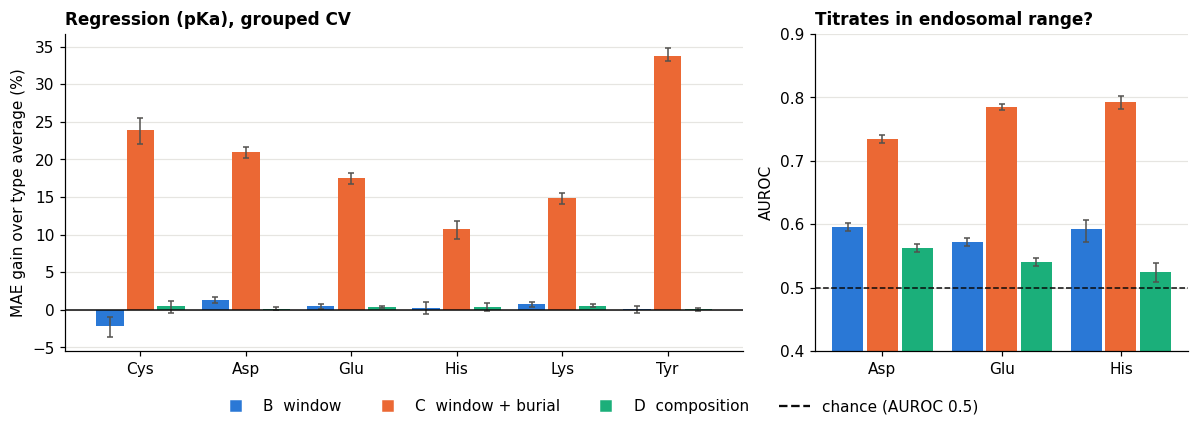

In [20]:
# Figure 1 - the four feature conditions compared (grouped cross-validation, boosting)
br = reg_out[~reg_out["condition"].str.startswith("MAE(")].copy(); br["c"] = br["condition"].str[0]
bc = clf_out[~clf_out["condition"].str.startswith("AUROC(")].copy(); bc["c"] = bc["condition"].str[0]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.9), gridspec_kw={"width_ratios": [2, 1.1]})
ax = axes[0]; w = 0.26
for k, c in enumerate("BCD"):
    d_ = br[br["c"] == c].set_index("aa").reindex(TYPES6)
    v = d_["gain_vs_A_%"].to_numpy(float)
    ax.bar(np.arange(6) + (k - 1) * (w + 0.03), v, w, color=COND_COL[c],
           yerr=[v - d_["gain_lo"].to_numpy(float), d_["gain_hi"].to_numpy(float) - v], error_kw=dict(lw=1, capsize=2, ecolor="#52514e"))
ax.axhline(0, color="#0b0b0b", lw=1); ax.set_xticks(range(6)); ax.set_xticklabels([TYPE_NAME[a] for a in TYPES6])
ax.set_ylabel("MAE gain over type average (%)"); ax.set_title("Regression (pKa), grouped CV", loc="left"); ax.grid(axis="x", visible=False)
ax = axes[1]; cls_types = [a for a in TYPES6 if a in set(bc["aa"])]
for k, c in enumerate("BCD"):
    d_ = bc[bc["c"] == c].set_index("aa").reindex(cls_types)
    v = d_["AUROC"].to_numpy(float)
    ax.bar(np.arange(len(cls_types)) + (k - 1) * (w + 0.03), v, w, color=COND_COL[c],
           yerr=[v - d_["lo"].to_numpy(float), d_["hi"].to_numpy(float) - v], error_kw=dict(lw=1, capsize=2, ecolor="#52514e"))
ax.axhline(0.5, color="#0b0b0b", lw=1, ls="--"); ax.set_ylim(0.4, 0.9)
ax.set_xticks(range(len(cls_types))); ax.set_xticklabels([TYPE_NAME[a] for a in cls_types])
ax.set_ylabel("AUROC"); ax.set_title("Titrates in endosomal range?", loc="left"); ax.grid(axis="x", visible=False)
fig.legend(handles=[Line2D([], [], marker="s", color=COND_COL[c], ls="", label=COND_NAME[c]) for c in "BCD"] +
           [Line2D([], [], color="#0b0b0b", ls="--", label="chance (AUROC 0.5)")], loc="lower center", ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.01))
fig.tight_layout(rect=(0, 0.07, 1, 1)); fig.savefig(FIG_DIR / "fig3_condition_comparison.png"); plt.show()

Figure 1 shows the gain over the type average for boosting on the grouped folds, with 95% intervals from the cluster bootstrap.

Using the window alone (B) gives between −2.1% (Cys) and 1.3% (Asp), so the window carries almost nothing beyond the residue type. For Cys it is actually worse than just guessing the type average, since the interval (−3.6 to −1.0) stays below zero. With burial added (C), the gain is between 10.7% (His) and 33.8% (Tyr), and the paired comparison shows that C beats B for every residue type, with intervals that exclude zero. The composition counts (D) add nothing (0.0 to 0.6%). 

The yes/no task shows the same pattern (right panel). The window alone gives an AUROC of 0.57 to 0.60, window + burial gives 0.74 to 0.79, and composition gives 0.52 to 0.56, against 0.5 for chance. So the non-linear model agrees with ridge, the window carries almost nothing, and burial carries the signal.

Leakage is far bigger for boosting than for ridge, because boosting is flexible enough to recognise related proteins. With a random split instead of a grouped one, the Cys window-only error drops from 1.341 to 0.990 pKa units, and the His window-only yes/no AUROC rises from 0.592 to 0.794. In other words, a random split would have made the window look much more useful than it is. This is why I split by sequence cluster for every comparison, and why the random split stays in as a comparison condition. Earlier, I claimed that boosting found interactions that ridge cannot. That was probably too generous. 

### 3.4 kNN (memoriser) and the band-edge sensitivity


In [21]:
# Comparison 4 - k-nearest neighbours (a model that can only memorise) and the Asp band-edge sensitivity
KNN_CAP, K = 20000, 10
Xknn = np.hstack([F_pos, 2.0 * F_bur])                    # burial scaled so it counts about as much as one mismatch
srng = np.random.default_rng(0)
knn_out = []
for aa in types:
    idx = np.where((tr["aa"] == aa).values)[0]
    if len(idx) > KNN_CAP:
        idx = np.sort(srng.choice(idx, KNN_CAP, replace=False))
    rows = np.zeros(len(tr), dtype=bool); rows[idx] = True
    y = y_all[rows]
    for fold_name, fold_col in [("grouped", "fold"), ("random", "fold_random")]:
        pk_ = oof_generic(rows, Xknn, lambda: KNeighborsRegressor(n_neighbors=K, algorithm="brute", n_jobs=-1), fold_col, y_all)[rows]
        pa_ = oof_generic(rows, zeros, lambda: DummyRegressor(strategy="mean"), fold_col, y_all)[rows]
        knn_out.append({"aa": aa, "rows used": len(idx), "folds": fold_name, "MAE kNN": np.abs(y - pk_).mean(), "MAE type average": np.abs(y - pa_).mean()})
kn = pd.DataFrame(knn_out)
kn["gain vs A (%)"] = 100 * (1 - kn["MAE kNN"] / kn["MAE type average"])
log(f"\n=== kNN (K={K}), window + burial, up to {KNN_CAP:,} rows per type ===")
log(kn.pivot(index="aa", columns="folds", values="gain vs A (%)").round(1).rename(columns=lambda c: f"gain, {c} folds (%)").to_string())

sens = []
dm = (tr["aa"] == "D").values
for lo_edge in (3.0, 3.5, 4.0):
    lab_ = ((tr["pk"] >= lo_edge) & (tr["pk"] <= IN_HI)).astype(int).values
    row = {"lower edge": lo_edge, "share yes": lab_[dm].mean()}
    for name, X, maker in [("logistic B", FEATURES["B  window"], lambda: LogisticRegression(C=1.0, class_weight="balanced", max_iter=2000)),
                           ("logistic C", FEATURES["C  window+burial"], lambda: LogisticRegression(C=1.0, class_weight="balanced", max_iter=2000)),
                           ("boosting C", HGB_X["C  window+burial"][0], lambda: hgb_clf(HGB_X["C  window+burial"][1]))]:
        p = oof_generic(dm, X, maker, "fold", lab_, proba=True)[dm]
        row[f"AUROC {name}"] = roc_auc_score(lab_[dm], p)
        row[f"AP {name}"] = average_precision_score(lab_[dm], p)
    sens.append(row)
log("\n=== Asp yes/no: does the answer depend on where the lower band edge sits? ===\n" + pd.DataFrame(sens).round(3).to_string(index=False))
kn.to_csv("cv_knn_results.csv", index=False)
pd.DataFrame(sens).to_csv("asp_edge_sensitivity.csv", index=False)


=== kNN (K=10), window + burial, up to 20,000 rows per type ===
folds  gain, grouped folds (%)  gain, random folds (%)
aa                                                    
C                          9.9                    17.5
D                         12.6                    14.6
E                          7.8                    10.5
H                          3.6                    10.8
K                          4.5                     7.7
Y                         21.3                    25.6

=== Asp yes/no: does the answer depend on where the lower band edge sits? ===
 lower edge  share yes  AUROC logistic B  AP logistic B  AUROC logistic C  AP logistic C  AUROC boosting C  AP boosting C
        3.0      0.541             0.593          0.618             0.796          0.823             0.790          0.820
        3.5      0.307             0.611          0.403             0.743          0.584             0.735          0.578
        4.0      0.087             0.644          

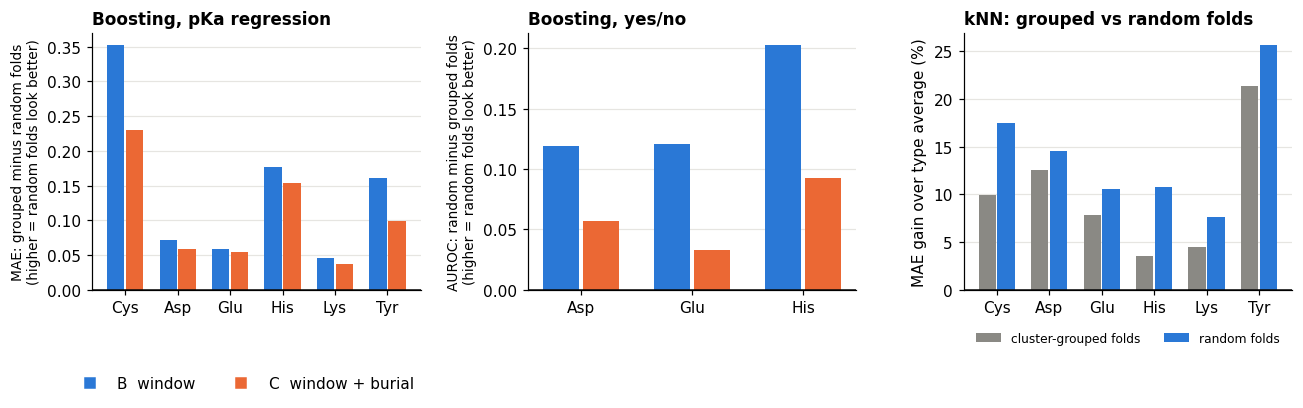

In [22]:
# Figure 2 - what random folds would have made me believe (leakage)
lr = lk_r.assign(c=lk_r["condition"].str[0], diff=lk_r["random looks better by"])
lc_ = lk_c.assign(c=lk_c["condition"].str[0], diff=lk_c["random minus grouped"])
knp = kn.pivot(index="aa", columns="folds", values="gain vs A (%)").reindex(TYPES6)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.7))
for ax, (d_, order_, ttl, yl) in zip(axes[:2], ((lr, TYPES6, "Boosting, pKa regression", "MAE: grouped minus random folds\n(higher = random folds look better)"),
                                               (lc_, list(usable), "Boosting, yes/no", "AUROC: random minus grouped folds\n(higher = random folds look better)"))):
    for k, c in enumerate("BC"):
        x_ = d_[d_["c"] == c].set_index("aa").reindex(order_)
        ax.bar(np.arange(len(order_)) + (k - 0.5) * 0.36, x_["diff"].to_numpy(float), 0.33, color=COND_COL[c])
    ax.axhline(0, color="#0b0b0b", lw=1); ax.set_xticks(range(len(order_))); ax.set_xticklabels([TYPE_NAME[a] for a in order_])
    ax.set_title(ttl, loc="left"); ax.set_ylabel(yl, fontsize=9); ax.grid(axis="x", visible=False)
ax = axes[2]
ax.bar(np.arange(6) - 0.18, knp["grouped"].to_numpy(float), 0.33, color=GREY, label="cluster-grouped folds")
ax.bar(np.arange(6) + 0.18, knp["random"].to_numpy(float), 0.33, color=BLUE, label="random folds")
ax.axhline(0, color="#0b0b0b", lw=1); ax.set_xticks(range(6)); ax.set_xticklabels([TYPE_NAME[a] for a in TYPES6])
ax.set_title("kNN: grouped vs random folds", loc="left"); ax.set_ylabel("MAE gain over type average (%)")
ax.legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2); ax.grid(axis="x", visible=False)
fig.legend(handles=[Line2D([], [], marker="s", color=COND_COL[c], ls="", label=COND_NAME[c]) for c in "BC"], loc="lower left", ncol=2, frameon=False, bbox_to_anchor=(0.05, -0.01))
fig.tight_layout(rect=(0, 0.07, 1, 1)); fig.savefig(FIG_DIR / "fig4_leakage.png"); plt.show()

Figure 2 shows how much the scores inflate when similar proteins are allowed on both sides of a split. 

The left two panels show the gap for boosting (error for pKa, AUROC for yes/no), and it is large for every residue type. The right panel shows the same for kNN with window and burial. With grouped folds kNN gains 3.6 to 21.3% over the type average, and with random folds it gains 7.7 to 25.6%. kNN just recalls the closest residues it has seen, so it does better whenever related proteins are on both sides, and the gap is the leakage. This makes a case for the grouped folds I have done. With a random split the window would have looked useful even when it isn’t.

I also tested how much the yes/no result depends on my choice of cut-off, using Asp, because its pKa sits close to the lower edge. With burial, the AUROC is 0.796 when the lower edge is 3.0, 0.743 at my choice of 3.5 and 0.645 at 4.0. So the yes/no results depend on where I draw the line, and the 3.5 is a choice that I report as one. At 4.0 the share of “yes” also falls from 54% to 9%, so it is a different and much harder task.

### 3.5 One model per residue type vs one pooled model


In [23]:
# Comparison 5 - one model per residue type vs one pooled model with the residue type as an input
tcode = tr["aa"].map({a: i for i, a in enumerate(types)}).values.astype(np.float32)
T_oh = np.eye(len(types), dtype=np.float32)[tcode.astype(int)]
T_lin = 30.0 * T_oh                       # scaled so ridge barely penalises the big offsets between types (see the maths section)
allrows = np.ones(len(tr), dtype=bool)
POOL = {"B  window":        (np.hstack([codes_f, tcode[:, None]]), [True] * 7, np.hstack([F_pos, T_lin])),
        "C  window+burial": (np.hstack([codes_f, F_bur, tcode[:, None]]), [True] * 6 + [False, True], np.hstack([F_pos, F_bur, T_lin]))}

def paired_boot_mae(aa, e1, e2):
    _, inv = np.unique(tr["cluster"].values[(tr["aa"] == aa).values], return_inverse=True)
    k = inv.max() + 1
    w = brng.multinomial(k, np.full(k, 1 / k), size=N_BOOT)
    return np.percentile((w @ np.bincount(inv, weights=e1) - w @ np.bincount(inv, weights=e2)) / (w @ np.bincount(inv)), [2.5, 97.5])

rows_out = []
for cond, (Xb, cat, Xl) in POOL.items():
    pooled = {"boosting": oof_generic(allrows, Xb, lambda: hgb_reg(cat), "fold", y_all),
              "ridge": oof_generic(allrows, Xl, lambda: Ridge(alpha=ALPHA), "fold", y_all)}
    for aa in types:
        rows = (tr["aa"] == aa).values
        y = y_all[rows]
        per = {"boosting": reg_pred[(aa, cond, "grouped")], "ridge": out_of_fold(rows, cond, "fold")[rows]}
        for model in ("boosting", "ridge"):
            e_pool, e_per = np.abs(y - pooled[model][rows]), np.abs(y - per[model])
            lo, hi = paired_boot_mae(aa, e_pool, e_per)
            rows_out.append({"aa": aa, "condition": cond, "model": model, "MAE per-type": e_per.mean(), "MAE pooled": e_pool.mean(),
                             "pooled - per-type": e_pool.mean() - e_per.mean(), "lo": lo, "hi": hi})
pv = pd.DataFrame(rows_out)
log("\n=== Regression: pooled vs per-type ('pooled - per-type' < 0 = pooled better; cluster-bootstrap 95% CI) ===\n" + pv.round(3).to_string(index=False))

crow = tr["aa"].isin(usable).values
cout = []
for cond, (Xb, cat, Xl) in POOL.items():
    pooled = {"boosting": oof_generic(crow, Xb, lambda: hgb_clf(cat), "fold", yc, proba=True),
              "logistic": oof_generic(crow, Xl, lambda: LogisticRegression(C=1.0, class_weight="balanced", max_iter=2000), "fold", yc, proba=True)}
    for aa in usable:
        rows = (tr["aa"] == aa).values
        y = yc[rows]
        per = {"boosting": clf_pred[(aa, cond, "grouped")], "logistic": oof_proba(rows, cond, "fold")[rows]}
        _, inv = np.unique(tr["cluster"].values[rows], return_inverse=True)
        groups_ = np.split(np.argsort(inv, kind="stable"), np.cumsum(np.bincount(inv))[:-1])
        k = len(groups_)
        draws = [np.concatenate([groups_[i] for i in brng.integers(0, k, k)]) for _ in range(N_BOOT)]
        for model in ("boosting", "logistic"):
            p_pool, p_per = pooled[model][rows], per[model]
            dlt = [roc_auc_score(y[i], p_pool[i]) - roc_auc_score(y[i], p_per[i]) for i in draws if y[i].min() != y[i].max()]
            lo, hi = np.percentile(dlt, [2.5, 97.5])
            cout.append({"aa": aa, "condition": cond, "model": model, "AUROC per-type": roc_auc_score(y, p_per), "AUROC pooled": roc_auc_score(y, p_pool),
                         "pooled - per-type": roc_auc_score(y, p_pool) - roc_auc_score(y, p_per), "lo": lo, "hi": hi})
pc = pd.DataFrame(cout)
log("\n=== Yes/no: pooled vs per-type ('pooled - per-type' > 0 = pooled better) ===\n" + pc.round(3).to_string(index=False))
pv.to_csv("pooled_vs_pertype_regression.csv", index=False)
pc.to_csv("pooled_vs_pertype_yesno.csv", index=False)


=== Regression: pooled vs per-type ('pooled - per-type' < 0 = pooled better; cluster-bootstrap 95% CI) ===
aa        condition    model  MAE per-type  MAE pooled  pooled - per-type     lo     hi
 C        B  window boosting         1.341       1.295             -0.047 -0.061 -0.033
 C        B  window    ridge         1.296       1.308              0.012  0.002  0.024
 D        B  window boosting         0.888       0.880             -0.008 -0.010 -0.006
 D        B  window    ridge         0.880       0.890              0.010  0.008  0.011
 E        B  window boosting         0.796       0.788             -0.008 -0.010 -0.006
 E        B  window    ridge         0.788       0.792              0.004  0.003  0.006
 H        B  window boosting         1.104       1.084             -0.020 -0.028 -0.014
 H        B  window    ridge         1.087       1.095              0.008  0.003  0.013
 K        B  window boosting         0.588       0.584             -0.004 -0.005 -0.002
 K        B 

Pooling all residue types into one model gives a small gain for boosting and a loss for ridge. 

Pooled boosting has a slightly lower error than the per-type version, by 0.047 pKa units for Cys and 0.020 for His with the window alone, and by 0.003 to 0.009 for the other types. In nearly all cases the intervals exclude zero, so the gain is real but small. 

With burial the picture is similar, and the one exception is Tyr (−0.003), where the interval crosses zero. Pooled ridge behaves differently. With the window alone it is slightly worse than per-type ridge, and with burial it is much worse (0.05 to 0.37 pKa units more error), even after I scale the residue-type columns. The reason is that ridge fits one straight-line slope for burial for every residue type, and the effect of burial is not the same across types. Boosting can split on the type and use a different relationship for each. 

In the yes/no task pooled boosting is also slightly better in AUROC (by 0.001 to 0.016), while pooled logistic regression is slightly worse. 

I made this decision here, before looking at the held-out cut or PKAD-2, using only the grouped folds of the training data. The headline model for the rest of the project is therefore pooled boosting with burial (boost C).

### 3.6 How the boosting model learns

In [24]:
# The final models' feature builder: works on any table with columns window, aa, rel_sasa_complex
TYPE_IDX = {a: i for i, a in enumerate(types)}
CONDS = ["B", "C", "D"]

def feats(df):
    cd = neighbour_codes(df["window"].astype(str).values)
    tc = df["aa"].map(TYPE_IDX).values.astype(np.float32)[:, None]
    bur = df["rel_sasa_complex"].clip(0, 1.5).values.astype(np.float32)[:, None]
    return {"codes": cd.astype(np.float32), "pos": onehot(cd), "comp": group_counts(cd), "bur": bur, "tc": tc}

def ridge_X(c, f):
    return {"B": f["pos"], "C": np.hstack([f["pos"], f["bur"]]), "D": f["comp"]}[c]

BOOST_CAT = {"B": [True] * 7, "C": [True] * 6 + [False, True], "D": [False] * 6 + [True]}
def boost_X(c, f):
    return {"B": np.hstack([f["codes"], f["tc"]]), "C": np.hstack([f["codes"], f["bur"], f["tc"]]), "D": np.hstack([f["comp"], f["tc"]])}[c]

trn = tr.reset_index(drop=True)
ftr = feats(trn)
ytr, ctr = trn["pk"].values, trn["titrates"].values

  (a) done (0.4 min)
  (b) done (1.7 min)


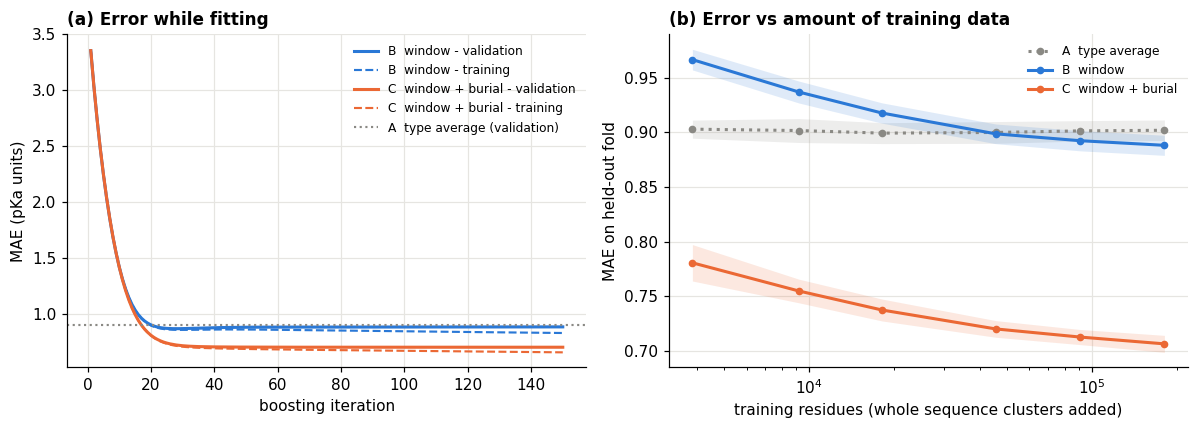

B  window              validation MAE at 150: 0.8882 | best iteration 28 -> 0.8720 | training MAE at 150: 0.8333
C  window + burial     validation MAE at 150: 0.7064 | best iteration 125 -> 0.7062 | training MAE at 150: 0.6606
type average: 0.9019
 fraction  n_train      A      B      C
     0.02     3863 0.9030 0.9666 0.7806
     0.05     9198 0.9017 0.9369 0.7548
     0.10    18086 0.8993 0.9177 0.7374
     0.25    45656 0.8999 0.8987 0.7200
     0.50    90740 0.9014 0.8924 0.7126
     1.00   180197 0.9019 0.8882 0.7064


In [25]:
# Figure 3 - how the boosting model learns: (a) error vs boosting iterations, (b) error vs amount of training data
# Training part only (grouped folds); the 20% cut and PKAD-2 are not touched.
CL = ["B", "C"]
rs = np.random.default_rng(0)
Xc = {c: boost_X(c, ftr) for c in CL}
folds_ = trn["fold"].values; fold_ids = sorted(np.unique(folds_))
t0 = time.time()

curve = {c: {"val": [], "train": []} for c in CL}
base_val = []
for f in fold_ids:
    fit, val = folds_ != f, folds_ == f
    base_ = trn[fit].groupby("aa")["pk"].mean()
    base_val.append(np.abs(ytr[val] - trn.loc[val, "aa"].map(base_).values).mean())
    sub = rs.choice(np.flatnonzero(fit), min(30000, int(fit.sum())), replace=False)      # training error on a sample
    for c in CL:
        m = hgb_reg(BOOST_CAT[c]).fit(Xc[c][fit], ytr[fit])
        curve[c]["val"].append([np.abs(ytr[val] - p).mean() for p in m.staged_predict(Xc[c][val])])
        curve[c]["train"].append([np.abs(ytr[sub] - p).mean() for p in m.staged_predict(Xc[c][sub])])
for c in CL:
    for k in ("val", "train"):
        curve[c][k] = np.array(curve[c][k])
print(f"  (a) done ({(time.time() - t0) / 60:.1f} min)")

FRACS = [0.02, 0.05, 0.1, 0.25, 0.5, 1.0]
rows = []
cluster_ = trn["cluster"].values
for f in fold_ids:
    fit_idx = np.flatnonzero(folds_ != f); val = folds_ == f
    order_ = rs.permutation(np.unique(cluster_[fit_idx]))
    for fr in FRACS:
        keep = np.isin(cluster_, order_[:max(1, int(round(fr * len(order_))))]) & (folds_ != f)
        base_ = trn[keep].groupby("aa")["pk"].mean()
        row = {"fold": f, "fraction": fr, "n_train": int(keep.sum()),
               "A": np.abs(ytr[val] - trn.loc[val, "aa"].map(base_).fillna(trn["pk"].mean()).values).mean()}
        for c in CL:
            row[c] = np.abs(ytr[val] - hgb_reg(BOOST_CAT[c]).fit(Xc[c][keep], ytr[keep]).predict(Xc[c][val])).mean()
        rows.append(row)
lcv = pd.DataFrame(rows)
lcv.to_csv("learning_curve_results.csv", index=False)
print(f"  (b) done ({(time.time() - t0) / 60:.1f} min)")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.0))
ax = axes[0]; it = np.arange(1, curve["B"]["val"].shape[1] + 1)
for c in CL:
    v, t_ = curve[c]["val"], curve[c]["train"]
    ax.plot(it, v.mean(0), color=COND_COL[c], lw=2, label=f"{COND_NAME[c]} - validation")
    ax.fill_between(it, v.mean(0) - v.std(0), v.mean(0) + v.std(0), color=COND_COL[c], alpha=0.15, lw=0)
    ax.plot(it, t_.mean(0), color=COND_COL[c], lw=1.4, ls="--", label=f"{COND_NAME[c]} - training")
ax.axhline(np.mean(base_val), color=GREY, lw=1.4, ls=":", label="A  type average (validation)")
ax.set_xlabel("boosting iteration"); ax.set_ylabel("MAE (pKa units)"); ax.set_title("(a) Error while fitting", loc="left")
ax.legend(frameon=False, fontsize=8)
ax = axes[1]
g = lcv.groupby("fraction").agg(n_train=("n_train", "mean"), **{k: (k, "mean") for k in ["A", "B", "C"]},
                                **{k + "_sd": (k, "std") for k in ["A", "B", "C"]}).reset_index()
xs = g["n_train"].to_numpy(float)
for k, col_, ls, lab_ in (("A", GREY, ":", "A  type average"), ("B", BLUE, "-", COND_NAME["B"]), ("C", ORANGE, "-", COND_NAME["C"])):
    mu, sd = g[k].to_numpy(float), g[k + "_sd"].to_numpy(float)
    ax.plot(xs, mu, color=col_, lw=2, ls=ls, marker="o", ms=4, label=lab_)
    ax.fill_between(xs, mu - sd, mu + sd, color=col_, alpha=0.15, lw=0)
ax.set_xscale("log"); ax.set_xlabel("training residues (whole sequence clusters added)"); ax.set_ylabel("MAE on held-out fold")
ax.set_title("(b) Error vs amount of training data", loc="left"); ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(FIG_DIR / "fig1_learning.png"); plt.show()

for c in CL:
    mv = curve[c]["val"].mean(0)
    print(f"{COND_NAME[c]:22s} validation MAE at 150: {mv[-1]:.4f} | best iteration {int(mv.argmin()) + 1} -> {mv.min():.4f} | training MAE at 150: {curve[c]['train'].mean(0)[-1]:.4f}")
print(f"type average: {np.mean(base_val):.4f}")
print(g.assign(n_train=g["n_train"].round(0).astype(int))[["fraction", "n_train", "A", "B", "C"]].round(4).to_string(index=False))

Figure 3 shows how the boosting model learns, on the training folds only. 

In panel (a), the validation error flattens after about 25 to 30 iterations. With window and burial (C) it ends at 0.706 (training error 0.661), and with the window alone (B) it ends at 0.888, against 0.902 for the type average. The window-only model overfits a little after iteration 28, where its validation error was lowest (0.872). Stopping there would raise its gain over the type average from 1.5% to 3.3%, which is still small, and I kept the 150 iterations I had chosen beforehand. 

Panel (b) shows what happens with more training data. The window-only model is worse than the type average when it has fewer than about 45,000 residues, and only ends 1.5% better with all 180,000. Window plus burial beats the type average at every size, from 0.78 with 3,863 residues down to 0.71 with all 180,197. The curves are still falling slowly, by about 0.004 to 0.006 per doubling of the data, so the window’s weakness is not simply a lack of data, since it only edges past the baseline once there is a lot of it.

## 4. Final performance (one-shot evaluation)

“One-shot” means that I score the held-out 20% cut and PKAD-2 once, with the model and settings I had already fixed using only the grouped folds of the training data. Nothing was tuned after seeing these results. A lock file records when the cell first ran. If I run it again, the models are refitted deterministically and give the same numbers, so a re-run is a reproduction and not a second test.

In [26]:
# THE ONE-SHOT EVALUATION: fit on the full 80%, score once on the 20% cut and once on PKAD-2
# The headline model (pooled boosting, condition C) was chosen before this cell was first run.
LOCK = Path("final_evaluation_done.txt")
if LOCK.is_file():
    log("Reproduction run - the one-shot evaluation was first run: " + LOCK.read_text().strip())
    log("No modelling choice above was changed after that first run, so refitting reproduces the same numbers.")

fitted = {"mean": trn.groupby("aa")["pk"].mean().to_dict(), "share_yes": trn.groupby("aa")["titrates"].mean().to_dict(),
          "ridge": {}, "boost_reg": {}, "logit": {}, "boost_clf": {}}
cm_tr = trn["aa"].isin(usable).values
for c in CONDS:
    for aa in types:
        m = (trn["aa"] == aa).values
        fitted["ridge"][(c, aa)] = Ridge(alpha=ALPHA).fit(ridge_X(c, ftr)[m], ytr[m])
    fitted["boost_reg"][c] = hgb_reg(BOOST_CAT[c]).fit(boost_X(c, ftr), ytr)
    for aa in usable:
        m = (trn["aa"] == aa).values
        fitted["logit"][(c, aa)] = LogisticRegression(C=1.0, class_weight="balanced", max_iter=2000).fit(ridge_X(c, ftr)[m], ctr[m])
    fitted["boost_clf"][c] = hgb_clf(BOOST_CAT[c]).fit(boost_X(c, ftr)[cm_tr], ctr[cm_tr])
joblib.dump({**fitted, "types": types, "usable": usable, "ALPHA": ALPHA}, "final_models.joblib")

def predict_all(df):
    """One prediction column per model. 'A' = type average; ridge/logit = one model per type; boost = pooled."""
    f = feats(df)
    out_ = pd.DataFrame(index=df.index)
    out_["A"] = df["aa"].map(fitted["mean"]).values
    cm = df["aa"].isin(usable).values
    for c in CONDS:
        r = np.full(len(df), np.nan)
        for aa in types:
            m = (df["aa"] == aa).values
            if m.any():
                r[m] = fitted["ridge"][(c, aa)].predict(ridge_X(c, f)[m])
        out_[f"ridge {c}"] = r
        out_[f"boost {c}"] = fitted["boost_reg"][c].predict(boost_X(c, f))
        pl, pb = np.full(len(df), np.nan), np.full(len(df), np.nan)
        for aa in usable:
            m = (df["aa"] == aa).values
            if m.any():
                pl[m] = fitted["logit"][(c, aa)].predict_proba(ridge_X(c, f)[m])[:, 1]
        if cm.any():
            pb[cm] = fitted["boost_clf"][c].predict_proba(boost_X(c, f)[cm])[:, 1]
        out_[f"p logit {c}"], out_[f"p boost {c}"] = pl, pb
    out_["p A"] = df["aa"].map(fitted["share_yes"]).where(df["aa"].isin(usable)).values
    return out_

REG_MODELS = ["A"] + [f"{m} {c}" for m in ("ridge", "boost") for c in CONDS]
CLF_MODELS = ["p A"] + [f"p {m} {c}" for m in ("logit", "boost") for c in CONDS]

def boot_metrics(y, P, w, cl, base="A"):
    """MAE, RMSE, r and gain over `base`, each with a 95% interval from resampling whole clusters (weighted rows)."""
    _, inv = np.unique(cl, return_inverse=True)
    k = inv.max() + 1
    cnt = brng.multinomial(k, np.full(k, 1 / k), size=N_BOOT).astype(float)
    cs = lambda v: np.bincount(inv, weights=v, minlength=k)
    Sw, Sy, Syy, SA = cs(w), cs(w * y), cs(w * y * y), cs(w * np.abs(y - P[base]))
    res_ = {}
    for name, p in P.items():
        e = y - p
        S = {"abs": cs(w * np.abs(e)), "sq": cs(w * e * e), "p": cs(w * p), "pp": cs(w * p * p), "py": cs(w * p * y)}
        def stats(c):
            with np.errstate(all="ignore"):
                W = c @ Sw
                mae, rmse = (c @ S["abs"]) / W, np.sqrt((c @ S["sq"]) / W)
                my, mp_ = (c @ Sy) / W, (c @ S["p"]) / W
                vy, vp = (c @ Syy) / W - my ** 2, (c @ S["pp"]) / W - mp_ ** 2
                r = np.where(vp > 1e-10, ((c @ S["py"]) / W - my * mp_) / np.sqrt(vy * vp), np.nan)
                return mae, rmse, r, 100 * (1 - mae / ((c @ SA) / W))
        pt, bt = stats(np.ones(k)), stats(cnt)
        row = {"n_rows": len(y), "n_clusters": k}
        for nm, a, b in zip(["MAE", "RMSE", "r", "gain"], pt, bt):
            lo, hi = np.nanpercentile(b, [2.5, 97.5]) if np.isfinite(b).any() else (np.nan, np.nan)
            row[nm], row[nm + "_lo"], row[nm + "_hi"] = float(a), lo, hi
        res_[name] = row
    return res_

def eval_table(df, preds, label, y_col, w_col=None):
    rows_ = []
    for aa in types + ["ALL"]:
        m = np.ones(len(df), bool) if aa == "ALL" else (df["aa"] == aa).values
        if m.sum() < 5:
            continue
        w = np.ones(m.sum()) if w_col is None else df.loc[m, w_col].values.astype(float)
        for n, r in boot_metrics(df.loc[m, y_col].values, {n: preds.loc[m, n].values for n in REG_MODELS}, w, df.loc[m, "cluster"].values).items():
            rows_.append({"dataset": label, "aa": aa, "model": n, **r})
    return pd.DataFrame(rows_)

def show(tab_, title):
    log(f"\n=== {title} ===")
    order_ = [a for a in types + ["ALL"] if a in set(tab_["aa"])]
    log("Rows and independent 30% clusters:\n" + tab_[tab_.model == "A"].set_index("aa")[["n_rows", "n_clusters"]].to_string())
    log("\nMAE (pKa units):\n" + tab_.pivot(index="aa", columns="model", values="MAE").reindex(order_)[REG_MODELS].round(3).to_string())
    g_ = tab_.assign(txt=lambda d_: d_.apply(lambda r: "" if r.model == "A" else f"{r.gain:.1f} [{r.gain_lo:.1f}, {r.gain_hi:.1f}]", axis=1))
    log("\nMAE gain over the type average, % [95% CI]:\n" + g_.pivot(index="aa", columns="model", values="txt").reindex(order_)[REG_MODELS[1:]].to_string())
    log("\nWithin-type r:\n" + tab_.pivot(index="aa", columns="model", values="r").reindex(order_)[REG_MODELS[1:]].drop(index="ALL", errors="ignore").round(2).to_string())

def auc_table(df, preds, label, y_col, w_col=None):
    rows_ = []
    for aa in usable:
        m = ((df["aa"] == aa) & df[y_col].notna()).values
        y = df.loc[m, y_col].astype(int).values
        w = np.ones(m.sum()) if w_col is None else df.loc[m, w_col].values.astype(float)
        npos, nneg = int(y.sum()), int((1 - y).sum())
        if npos < 10 or nneg < 10:
            rows_.append({"dataset": label, "aa": aa, "model": "(too few)", "n_yes": npos, "n_no": nneg})
            continue
        _, inv = np.unique(df.loc[m, "cluster"].values, return_inverse=True)
        groups_ = np.split(np.argsort(inv, kind="stable"), np.cumsum(np.bincount(inv))[:-1])
        draws = [np.concatenate([groups_[i] for i in brng.integers(0, len(groups_), len(groups_))]) for _ in range(N_BOOT)]
        for n in CLF_MODELS[1:]:
            p = preds.loc[m, n].values
            bs = [roc_auc_score(y[i], p[i], sample_weight=w[i]) for i in draws if y[i].min() != y[i].max()]
            lo, hi = np.percentile(bs, [2.5, 97.5])
            rows_.append({"dataset": label, "aa": aa, "model": n, "n_yes": npos, "n_no": nneg, "AUROC": roc_auc_score(y, p, sample_weight=w),
                          "lo": lo, "hi": hi, "AP": average_precision_score(y, p, sample_weight=w), "share_yes": np.average(y, weights=w)})
    return pd.DataFrame(rows_)

def show_auc(tab_, title):
    log(f"\n=== {title} ===")
    if "AUROC" not in tab_:
        log("Too few yes or no examples to score:\n" + tab_.to_string(index=False)); return
    ok2 = tab_[tab_["model"] != "(too few)"].copy()
    ok2["AUROC [95% CI]"] = ok2.apply(lambda r: f"{r.AUROC:.3f} [{r.lo:.3f}, {r.hi:.3f}]", axis=1)
    log("Yes / no counts: " + str(ok2.drop_duplicates("aa").set_index("aa")[["n_yes", "n_no"]].to_dict("index")))
    log("AUROC:\n" + ok2.pivot(index="aa", columns="model", values="AUROC [95% CI]").to_string())
    log("Average precision:\n" + ok2.pivot(index="aa", columns="model", values="AP").round(3).to_string())

# ---------- the 20% test cut ----------
te = mt[mt["split"] == "test20"].copy()
te["window"] = te["window"].astype(str)
te = te[(te["window"].str.len() == 7) & te["rel_sasa_complex"].notna() & te["pk"].notna()].reset_index(drop=True)
te["titrates"] = ((te["pk"] >= IN_LO) & (te["pk"] <= IN_HI)).astype(int)
pte = predict_all(te)
te_tab = eval_table(te, pte, "test20", "pk")
show(te_tab, f"20% TEST CUT (computed labels): {len(te):,} residues")
te_auc = auc_table(te.assign(yes=te["titrates"]), pte, "test20", "yes")
show_auc(te_auc, "20% TEST CUT, yes/no")

# ---------- PKAD-2 (experimental) ----------
p2 = pd.read_csv("model_table_pkad2.csv", dtype={"window": str, "aa": str, "pdb": str, "kind": str}, keep_default_na=False, na_values=[""])
for b in ("approximate", "multi_transition"):
    p2[b] = p2[b].astype(str).str.lower().eq("true")
p2 = p2[(p2["window"].str.len() == 7) & p2["rel_sasa_complex"].notna() & p2["aa"].isin(types) & p2["cluster"].notna() & p2["pka"].notna()].reset_index(drop=True)
pp2 = predict_all(p2)
p2 = pd.concat([p2, pp2.add_prefix("pred_")], axis=1)
pm = lambda df: df.rename(columns={f"pred_{m}": m for m in REG_MODELS})[REG_MODELS].reset_index(drop=True)
head = p2[(p2["kind"] == "exact") & ~p2["multi_transition"]].reset_index(drop=True)
log(f"\nPKAD-2 usable rows: {len(p2):,} | headline set (exact, single-transition): {len(head):,} rows, "
    f"{head['residue_key'].nunique():,} residues, {head['cluster'].nunique():,} independent clusters")
p2_tab = eval_table(head, pm(head), "pkad2", "pka", "weight")
show(p2_tab, "PKAD-2 EXPERIMENTAL pKa, headline set (weighted per residue)")

y2 = np.full(len(p2), np.nan)                     # yes/no label from experiment; a bound counts only if it settles the question
ex2 = (p2["kind"] == "exact") & ~p2["multi_transition"]
y2[ex2.values] = ((p2.loc[ex2, "pka"] >= IN_LO) & (p2.loc[ex2, "pka"] <= IN_HI)).astype(int)
y2[((p2["kind"] == "upper_bound") & (p2["pka"] <= IN_LO)).values] = 0
y2[((p2["kind"] == "lower_bound") & (p2["pka"] >= IN_HI)).values] = 0
p2["yes"] = y2
p2_auc = auc_table(p2, pp2, "pkad2", "yes", "weight")
show_auc(p2_auc, "PKAD-2, yes/no")

cz = p2[p2["kind"] != "exact"].reset_index(drop=True)
rows = []
for aa in types + ["ALL"]:
    sub = cz if aa == "ALL" else cz[cz["aa"] == aa]
    if len(sub):
        r = {"aa": aa, "rows": len(sub)}
        for n in REG_MODELS:
            p = sub[f"pred_{n}"].values
            r[n] = np.average(np.where(sub["kind"] == "upper_bound", p < sub["pka"].values, p > sub["pka"].values), weights=sub["weight"].values)
        rows.append(r)
log("\n=== PKAD-2 censored values: share of predictions that satisfy the bound (weighted) ===\n" + pd.DataFrame(rows).set_index("aa").round(2).to_string())

def gain_str(df, model="boost C", w="weight"):
    out_ = {}
    for aa in types + ["ALL"]:
        s = df if aa == "ALL" else df[df["aa"] == aa]
        if len(s) < 5:
            out_[aa] = ""; continue
        mae = lambda col_: np.average(np.abs(s["pka"].values - s[f"pred_{col_}"].values), weights=s[w].values)
        out_[aa] = f"{100 * (1 - mae(model) / mae('A')):.1f} (n={len(s)})"
    return out_
med = head.groupby("residue_key").agg(pka=("pka", "median"), aa=("aa", "first"), cluster=("cluster", "first"),
                                      **{f"pred_{n}": (f"pred_{n}", "first") for n in REG_MODELS}).reset_index()
med["weight"] = 1.0
variants = {"headline": head, "drop '~' values": head[~head["approximate"]], "also keep two-transition rows": p2[p2["kind"] == "exact"],
            "only rows with a numeric uncertainty": head[head["unc"].notna()], "one median value per residue": med}
log("\n=== PKAD-2 sensitivity: gain of 'boost C' over the type average (%) ===\n" + pd.DataFrame({k: gain_str(v) for k, v in variants.items()}).T.to_string())

te_tab.to_csv("final_test20_metrics.csv", index=False); te_auc.to_csv("final_test20_yesno.csv", index=False)
p2_tab.to_csv("final_pkad2_metrics.csv", index=False); p2_auc.to_csv("final_pkad2_yesno.csv", index=False)
pd.concat([te, pte], axis=1).to_csv("final_test20_predictions.csv", index=False)
p2.to_csv("final_pkad2_predictions.csv", index=False)
if not LOCK.is_file():
    LOCK.write_text(f"One-shot evaluation run {datetime.datetime.now().isoformat()}\n")

Reproduction run - the one-shot evaluation was first run: One-shot evaluation run 2026-10-18T20:40:45.177308
No modelling choice above was changed after that first run, so refitting reproduces the same numbers.

=== 20% TEST CUT (computed labels): 57,256 residues ===
Rows and independent 30% clusters:
     n_rows  n_clusters
aa                     
C      2141         359
D     13330         546
E     15232         552
H      5093         500
K     13555         557
Y      7905         523
ALL   57256         570

MAE (pKa units):
model      A  ridge B  ridge C  ridge D  boost B  boost C  boost D
aa                                                                
C      1.346    1.324    1.051    1.341    1.331    0.985    1.341
D      0.930    0.907    0.759    0.926    0.908    0.733    0.928
E      0.783    0.770    0.669    0.779    0.770    0.644    0.780
H      1.144    1.107    1.034    1.119    1.104    0.984    1.123
K      0.590    0.578    0.511    0.584    0.579    0.496    

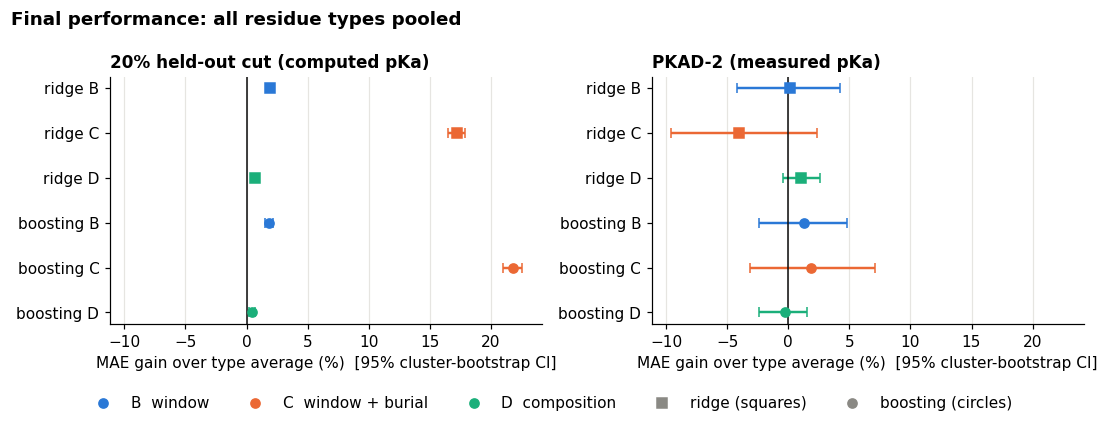

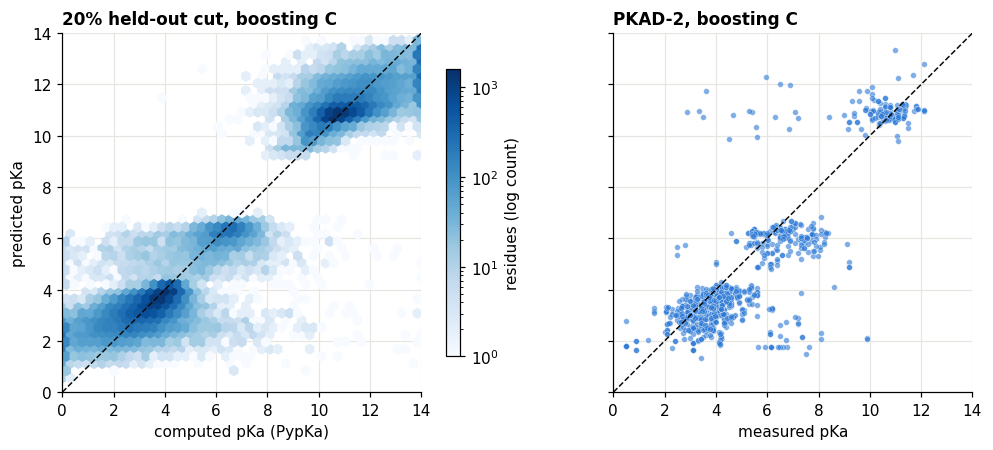

In [27]:
# Figure 4 - final performance: gain over the type average on both test sets, and predicted vs measured pKa
MODELS6 = [f"{m} {c}" for m in ("ridge", "boost") for c in "BCD"]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharex=True)
for ax, (tab_, title) in zip(axes, ((te_tab, "20% held-out cut (computed pKa)"), (p2_tab, "PKAD-2 (measured pKa)"))):
    a = tab_[tab_["aa"] == "ALL"].set_index("model")
    for i, m in enumerate(MODELS6):
        r = a.loc[m]
        ax.errorbar(r["gain"], i, xerr=[[r["gain"] - r["gain_lo"]], [r["gain_hi"] - r["gain"]]], fmt="o" if m.startswith("boost") else "s",
                    color=COND_COL[m[-1]], ms=6, capsize=3, lw=1.6)
    ax.axvline(0, color="#0b0b0b", lw=1)
    ax.set_yticks(range(len(MODELS6))); ax.set_yticklabels([m.replace("boost", "boosting") for m in MODELS6])
    ax.invert_yaxis(); ax.set_xlabel("MAE gain over type average (%)  [95% cluster-bootstrap CI]"); ax.set_title(title, loc="left")
    ax.grid(axis="y", visible=False)
fig.legend(handles=[Line2D([], [], marker="o", color=COND_COL[c], ls="", label=COND_NAME[c]) for c in "BCD"] +
           [Line2D([], [], marker="s", color=GREY, ls="", label="ridge (squares)"), Line2D([], [], marker="o", color=GREY, ls="", label="boosting (circles)")],
           loc="lower center", ncol=5, frameon=False, bbox_to_anchor=(0.5, -0.01))
fig.suptitle("Final performance: all residue types pooled", x=0.01, ha="left", fontweight="bold"); fig.tight_layout(rect=(0, 0.08, 1, 1))
fig.savefig(FIG_DIR / "fig2_final_performance_gain.png"); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), sharex=True, sharey=True)
hb = axes[0].hexbin(te["pk"], pte["boost C"], gridsize=45, cmap="Blues", mincnt=1, bins="log", extent=(0, 14, 0, 14))
axes[0].set_title("20% held-out cut, boosting C", loc="left"); axes[0].set_xlabel("computed pKa (PypKa)"); axes[0].set_ylabel("predicted pKa")
axes[1].scatter(head["pka"], head["pred_boost C"], s=14, color=BLUE, alpha=0.6, edgecolor="white", linewidth=0.3)
axes[1].set_title("PKAD-2, boosting C", loc="left"); axes[1].set_xlabel("measured pKa")
for ax in axes:
    ax.plot([0, 14], [0, 14], color="#0b0b0b", lw=1, ls="--"); ax.set_xlim(0, 14); ax.set_ylim(0, 14); ax.set_aspect("equal")
fig.colorbar(hb, ax=axes[0], label="residues (log count)", shrink=0.8)
fig.tight_layout(); fig.savefig(FIG_DIR / "fig2b_pred_vs_measured.png"); plt.show()

In [28]:
# Table 1-3 - comparison tables (also saved as .csv and .md)
LABEL = {"A": "A  type average", "ridge B": "B  window, ridge", "ridge C": "C  window + burial, ridge", "ridge D": "D  composition, ridge",
         "boost B": "B  window, boosting", "boost C": "C  window + burial, boosting", "boost D": "D  composition, boosting"}
def gain_txt(r): return "-" if r["model"] == "A" else f"{r['gain']:.1f} [{r['gain_lo']:.1f}, {r['gain_hi']:.1f}]"
def to_md(df):
    lines_ = ["| " + " | ".join(df.columns) + " |", "|" + "|".join(["---"] * len(df.columns)) + "|"]
    return "\n".join(lines_ + ["| " + " | ".join(str(v) for v in row) + " |" for row in df.itertuples(index=False)])
def save_table(df, name):
    df.to_csv(OUT_DIR / f"{name}.csv", index=False); (OUT_DIR / f"{name}.md").write_text(to_md(df) + "\n")

a_, b_ = te_tab[te_tab["aa"] == "ALL"].set_index("model"), p2_tab[p2_tab["aa"] == "ALL"].set_index("model")
t1 = pd.DataFrame([{"Model": LABEL[m], "Held-out cut MAE": f"{a_.loc[m, 'MAE']:.3f}", "Held-out cut gain % [95% CI]": gain_txt({**a_.loc[m], "model": m}),
                    "PKAD-2 MAE": f"{b_.loc[m, 'MAE']:.3f}", "PKAD-2 gain % [95% CI]": gain_txt({**b_.loc[m], "model": m})} for m in LABEL])
print("Table 1 - all residue types pooled\n" + t1.to_string(index=False)); save_table(t1, "table1_main")

tt_ = te_tab[te_tab["model"] != "A"].copy(); tt_["txt"] = tt_.apply(gain_txt, axis=1)
t2 = tt_.pivot(index="aa", columns="model", values="txt").reindex(TYPES6 + ["ALL"])[list(LABEL)[1:]]
t2.columns = [LABEL[c] for c in t2.columns]; t2.index = [TYPE_NAME[i] for i in t2.index]
t2 = t2.reset_index().rename(columns={"index": "Residue type"})
print("\nTable 2 - gain by residue type, held-out cut\n" + t2.to_string(index=False)); save_table(t2, "table2_by_type")

yn = te_auc[te_auc["model"] != "(too few)"].copy()
yn["txt"] = yn.apply(lambda r: f"{r['AUROC']:.3f} [{r['lo']:.3f}, {r['hi']:.3f}]", axis=1)
t3 = yn.pivot(index="model", columns="aa", values="txt").reset_index()
t3["model"] = t3["model"].str.replace("p ", "", n=1); t3 = t3.rename(columns={"model": "Model (yes/no AUROC, held-out cut)"})
print("\nTable 3 - yes/no AUROC\n" + t3.to_string(index=False)); save_table(t3, "table3_yesno")

Table 1 - all residue types pooled
                       Model Held-out cut MAE Held-out cut gain % [95% CI] PKAD-2 MAE PKAD-2 gain % [95% CI]
             A  type average            0.905                            -      0.919                      -
            B  window, ridge            0.888               1.9 [1.6, 2.2]      0.918        0.1 [-4.2, 4.2]
   C  window + burial, ridge            0.750            17.2 [16.5, 17.9]      0.956       -4.0 [-9.6, 2.3]
       D  composition, ridge            0.899               0.7 [0.5, 0.8]      0.909        1.0 [-0.4, 2.6]
         B  window, boosting            0.889               1.9 [1.5, 2.2]      0.907        1.3 [-2.4, 4.8]
C  window + burial, boosting            0.708            21.8 [21.0, 22.6]      0.902        1.9 [-3.1, 7.1]
    D  composition, boosting            0.902               0.4 [0.2, 0.7]      0.921       -0.2 [-2.4, 1.5]

Table 2 - gain by residue type, held-out cut
Residue type B  window, ridge C  window + buria

### What the final results show

**On the computed labels (the 20% held-out cut)**, the results are clear. The best model, boosting with window + burial (C), has an error 21.8% lower than the type average (95% interval 21.0 to 22.6%). Ridge with the same features gets 17.2%. The window alone gains only 1.9%, and the composition counts (D) gain 0.4 to 0.7%. The gain with burial differs by residue type, from 13.9% for His to 34.2% for Tyr. For the yes/no question, burial lifts the AUROC to 0.74 (Asp), 0.79 (Glu) and 0.82 (His), where 0.5 is chance. So on PypKa's numbers, burial carries almost all of the signal, and the window carries almost none.

**On the measured values (PKAD-2)**, this does not carry over. Boosting C gains only 1.9%, with an interval of −3.1 to 7.1%. Ridge C is at −4.0% (−9.6 to 2.3%). Every interval includes zero, so no model clearly beats the type average, and within a residue type the predictions barely correlate with the measurements. The yes/no AUROCs on PKAD-2 are 0.56 (Asp), 0.66 (Glu) and 0.80 (His), with wide intervals. For the values reported only as limits (like "<4"), boosting C respects the bound 47% of the time, against 32% for the type average (77 rows, so these are counts, not estimates). The PKAD-2 gain stays between 1.8% and 3.7% however I treat the awkward rows. Figure 2b shows the same thing: predictions fall into bands by residue type, and on the computed labels there is a diagonal inside each band. On PKAD-2 there is no diagonal inside the bands.

**What this tells me.** The gap between the two tests is the main finding. Burial predicts PypKa well, but PypKa itself is a structure-based calculation, so a model that learns burial is partly learning how PypKa works. When I test against real measurements, that advantage mostly disappears. Two things limit what I can conclude. PKAD-2 has only 76 sequence clusters, so its intervals are wide, and a small real gain could hide inside them. And PypKa itself misses the measurements by 0.75 pKa units on average. For my squid proteins, for now, the only information I have is the sequence window, and the window adds about 2% on computed pKa and about nothing on measured pKa. So a sequence-only model cannot reliably say how a recoding shifts a residue's pKa. The charge change I do see in the squid edits comes mainly from the amino acid swap itself, not from anything the model learned. To go further I would need 3D structures of the squid proteins, which means AlphaFold models, and a structure-based tool.

### 4.1 Why does PKAD-2 fail? A diagnostic

My model does well against PypKa’s numbers but not against the measured ones in PKAD-2, and I wanted to know why. There are two possible explanations, and they lead to different conclusions. The first is a bug in how I built the PKAD-2 inputs (the windows or the burial values), so the model was fed the wrong information. The second is that PypKa’s calculations and real experiments genuinely disagree. Then the model could have learned PypKa properly, and PypKa is what is off. To tell them apart, I wanted to check that the PKAD-2 inputs look like the training inputs (the middle letter of each window matches the residue, and the burial values are similar). Then, for the same PKAD-2 residues, I wanted to compare three things side by side: the experiment, PypKa and my model. If my model tracks PypKa but PypKa misses the experiment, the cause is the second explanation. If my model doesn’t even track PypKa on these residues, the cause is probably the first.

In [29]:
# Diagnostic: is the weak PKAD-2 result a pipeline bug, or a real gap between calculation and experiment?
for nm, d_ in [("20% test cut", te), ("PKAD-2", p2)]:
    log(f"{nm}: window centre letter equals the residue type in {100 * (d_['window'].str[3] == d_['aa']).mean():.2f}% of rows")
log("\nMean relative SASA by type:\n" + pd.DataFrame({"training": trn.groupby("aa")["rel_sasa_complex"].mean(),
                                                     "20% test cut": te.groupby("aa")["rel_sasa_complex"].mean(),
                                                     "PKAD-2": head.groupby("aa")["rel_sasa_complex"].mean()}).round(2).to_string())

lab_ = clean[key + ["pk"]].copy()
lab_["chain"] = lab_["chain"].astype(str)
lab_["residue_number"] = pd.to_numeric(lab_["residue_number"], errors="coerce").astype(float)
lab_ = lab_.rename(columns={"pk": "pypka"}).drop_duplicates(key)
h = head.copy()
h["chain"] = h["chain"].astype(str)
h["residue_number"] = pd.to_numeric(h["residue_number"], errors="coerce").astype(float)
hh = h.merge(lab_, on=key, how="left").dropna(subset=["pypka"])
log(f"\nPKAD-2 headline rows that also have a PypKa value: {len(hh)} of {len(h)}")

def wmean(x, w): return float(np.average(x, weights=w))
def wcorr(x, y, w):
    mx, my = wmean(x, w), wmean(y, w)
    sx, sy = np.sqrt(wmean((x - mx) ** 2, w)), np.sqrt(wmean((y - my) ** 2, w))
    return wmean((x - mx) * (y - my), w) / (sx * sy) if sx > 1e-9 and sy > 1e-9 else np.nan
rows = []
for aa in types + ["ALL"]:
    s = hh if aa == "ALL" else hh[hh["aa"] == aa]
    if len(s) < 8:
        continue
    w, e, py, mo, av = s["weight"].values, s["pka"].values, s["pypka"].values, s["pred_boost C"].values, s["pred_A"].values
    rows.append({"aa": aa, "n": len(s), "mean experiment": wmean(e, w), "mean PypKa": wmean(py, w), "mean model": wmean(mo, w),
                 "MAE type avg vs exp": wmean(np.abs(av - e), w), "MAE PypKa vs exp": wmean(np.abs(py - e), w),
                 "MAE model vs exp": wmean(np.abs(mo - e), w), "MAE model vs PypKa": wmean(np.abs(mo - py), w),
                 "r PypKa-exp": wcorr(py, e, w) if aa != "ALL" else np.nan, "r model-PypKa": wcorr(mo, py, w) if aa != "ALL" else np.nan,
                 "r model-exp": wcorr(mo, e, w) if aa != "ALL" else np.nan})
log("\n=== Same PKAD-2 residues: experiment, PypKa, and my model ('boost C') ===\n" + pd.DataFrame(rows).set_index("aa").round(2).to_string())
log("\nSpread of the PypKa labels (SD), test cut vs PKAD-2 residues:\n" +
    pd.DataFrame({"20% test cut": te.groupby("aa")["pk"].std(), "PKAD-2 residues": hh.groupby("aa")["pypka"].std()}).round(2).to_string())

20% test cut: window centre letter equals the residue type in 100.00% of rows
PKAD-2: window centre letter equals the residue type in 100.00% of rows

Mean relative SASA by type:
    training  20% test cut  PKAD-2
aa                                
C       0.09          0.10    0.08
D       0.33          0.33    0.29
E       0.36          0.37    0.34
H       0.25          0.26    0.28
K       0.40          0.40    0.43
Y       0.16          0.17    0.25

PKAD-2 headline rows that also have a PypKa value: 1002 of 1048

=== Same PKAD-2 residues: experiment, PypKa, and my model ('boost C') ===
        n  mean experiment  mean PypKa  mean model  MAE type avg vs exp  MAE PypKa vs exp  MAE model vs exp  MAE model vs PypKa  r PypKa-exp  r model-PypKa  r model-exp
aa                                                                                                                                                                      
C      12             5.93        8.87       10.87             

The above diagnostic says that the weak PKAD-2 result is not a bug (hmmm). 

In both the 20% test cut and PKAD-2, the middle letter of the window matches the residue type in 100% of rows, and the burial values are similar across training, test cut and PKAD-2 (Tyr differs most, 0.25 on PKAD-2 against 0.16 in training). On the same PKAD-2 residues, my model is 0.70 from PypKa, the same as on the test cut (0.71), so the inputs are being handled correctly. The disagreement is with experiment. PypKa is 0.74 from the measurements, against 0.89 for the type average, so PypKa really is closer to experiment. My model is not (0.88). Several things explain this. For Asp, Glu and His, the type averages sit about 0.6 to 0.7 below the measured means (Asp 3.44 measured against about 2.85 in training), and my model sits about the same distance below, so most of the error is a shared offset that the model cannot fix. The PKAD-2 residues also have less spread in their PypKa values than the test cut (for example Tyr 0.60 against 1.57), which leaves less variation to predict. Cys is far off, but it has only 12 residues, and its measured mean is 5.9 against about 11 in training. Most importantly, within a residue type PypKa follows the experiment moderately well (r between 0.26 and 0.61), while my model barely does (about 0), and it follows PypKa only weakly (r 0.11 to 0.33, Tyr 0.67). So the model only captures a small part of what PypKa knows, and that part does not line up with experiment. PypKa uses the full 3D structure, and burial is only a rough summary of it.

## 5. Applying the models to my squid edits

To move on, despite realizing that my capstone is doomed using this pipeline and I need to seek alternatives, for each of my 263 edited residues, I used it to predict the pKa of the original residue and of the edited residue. 

I convert both to a charge at pH 7.4, 6.5, 5.5 and 4.5, and the difference between the two charges is the effect of the edit. 

For this I use a total-effect design. The original window contains all the original neighbours, and the edited window contains all the edited neighbours, so if a neighbouring residue is also edited, that counts too. 

I have no 3D structures for these proteins that are fed into this pipeline, so I can’t use burial, which means only the sequence-only models (A, B and D) can be applied. I tried importing Alpha Fold models into the pipeline but I ran out of time. 

Therefore, I declared my main model, boosting with the window alone (boost B), before looking at any output, and I treat the others as checks on it. Arg is not in the training data, so I give it a fixed pKa of 12.5 and flag it. Cys predictions are flagged as unreliable, because PypKa itself is far from experiment for Cys. There are no measured pKa values for squid proteins, so I cannot score these predictions. I can only look at what the models say.

In [30]:
# Application: the sequence-only models (A, B, D) on the 263 D. pealeii edited sites. No training, no labels.
ARG_PKA = 12.5                    # rule: Arg is absent from the training data
ACID, BASE = set("DEYC"), set("HKR")
MAIN = "boost B"                  # declared before looking at any output: pooled boosting, window only
SENS = ["A", "ridge B", "ridge D", "boost D"]
MODELS = [MAIN] + SENS

for col_, aa_col in (("window_original", "orig_aa"), ("window_edited", "edited_aa")):
    bad = ed[(ed[col_].str.len() != 7) | (ed[col_].str[3] != ed[aa_col])]
    print(f"{col_}: {len(bad)} rows where the window centre does not match {aa_col}")

def pk_state(windows, aas):
    """One pKa column per model for one state (original or edited). NaN = not titratable in the models' scope."""
    d_ = pd.DataFrame({"window": windows.astype(str).values, "aa": aas.values, "rel_sasa_complex": 0.5})   # burial unused by A/B/D
    out_ = pd.DataFrame(np.nan, index=d_.index, columns=MODELS)
    m = d_["aa"].isin(types).values
    if m.any():
        pr = predict_all(d_[m].reset_index(drop=True))
        for c in MODELS:
            out_.loc[m, c] = pr[c].values
    out_.loc[(d_["aa"] == "R").values, :] = ARG_PKA
    return out_

def charge(aa, pk_, pH):
    """Henderson-Hasselbalch; non-titratable residues (NaN pKa) count as neutral."""
    q = np.zeros(len(aa))
    pk_ = np.asarray(pk_, dtype=float); a = np.asarray(aa)
    ok3 = ~np.isnan(pk_)
    ac, ba = ok3 & np.isin(a, list(ACID)), ok3 & np.isin(a, list(BASE))
    q[ac] = -1.0 / (1.0 + 10.0 ** (pk_[ac] - pH))
    q[ba] = +1.0 / (1.0 + 10.0 ** (pH - pk_[ba]))
    return q

po, pe = pk_state(ed["window_original"], ed["orig_aa"]), pk_state(ed["window_edited"], ed["edited_aa"])
ceph = ed[["protein", "residue_number", "orig_aa", "edited_aa", "synonymous", "editing_pct_max", "any_ge50",
           "before_first_Met", "n_other_edited_in_window"]].copy()
ceph["cys_flag"] = ed["orig_aa"].eq("C") | ed["edited_aa"].eq("C")
ceph["arg_rule"] = ed["orig_aa"].eq("R") | ed["edited_aa"].eq("R")
for mdl in MODELS:
    tag = mdl.replace(" ", "_")
    ceph[f"pk_orig_{tag}"], ceph[f"pk_edit_{tag}"] = po[mdl].values, pe[mdl].values
    ceph[f"dpk_{tag}"] = pe[mdl].values - po[mdl].values
    for pH in PH:
        ceph[f"dq_{tag}_{pH}"] = charge(ed["edited_aa"], pe[mdl].values, pH) - charge(ed["orig_aa"], po[mdl].values, pH)
ceph.to_csv("cephalopod_dp_sequence_only.csv", index=False)

mt_ = MAIN.replace(" ", "_")
dqcols = [f"dq_{mt_}_{pH}" for pH in PH]
nonsyn = ~ceph["synonymous"]
print(f"\nSites: {len(ceph)} | nonsynonymous: {int(nonsyn.sum())} | synonymous (control): {int((~nonsyn).sum())}")
print("Mean |change in charge| per pH:\n" + ceph.groupby(nonsyn.rename("changes residue"))[dqcols].agg(lambda s: s.abs().mean()).round(3)
      .rename(columns=dict(zip(dqcols, PH))).to_string())
ns = ceph[nonsyn].assign(subst=lambda d_: d_["orig_aa"] + ">" + d_["edited_aa"])
by_sub = ns.groupby("subst").agg(n=("subst", "size"), **{f"mean dq {pH}": (f"dq_{mt_}_{pH}", "mean") for pH in PH}).round(2)
print("\nBy substitution (nonsynonymous):\n" + by_sub.sort_values("n", ascending=False).to_string())
both_ = ns[ns[f"pk_orig_{mt_}"].notna() & ns[f"pk_edit_{mt_}"].notna()]
print(f"\nDoes the window matter? mean |dpk| between models over {len(both_)} titratable->titratable sites:",
      {s: round((both_[f"dpk_{mt_}"] - both_[f"dpk_{s.replace(' ', '_')}"]).abs().mean(), 3) for s in SENS})
print("Synonymous control, mean |dpk| from neighbour edits alone:", round(ceph.loc[~nonsyn, f"dpk_{mt_}"].abs().mean(), 3),
      f"(n = {int(ceph.loc[~nonsyn, f'dpk_{mt_}'].notna().sum())})")
print("Flags:", {"Cys": int(ceph["cys_flag"].sum()), "Arg rule": int(ceph["arg_rule"].sum()),
                 "before first Met": int(ceph["before_first_Met"].sum()), "editing >=50%": int(ceph["any_ge50"].sum())})

window_original: 0 rows where the window centre does not match orig_aa
window_edited: 0 rows where the window centre does not match edited_aa

Sites: 263 | nonsynonymous: 168 | synonymous (control): 95
Mean |change in charge| per pH:
                   7.4    6.5    5.5    4.5
changes residue                            
False            0.000  0.000  0.000  0.001
True             0.357  0.355  0.349  0.336

By substitution (nonsynonymous):
        n  mean dq 7.4  mean dq 6.5  mean dq 5.5  mean dq 4.5
subst                                                        
K>R    36         0.00          0.0         0.00         0.00
S>G    15         0.00          0.0         0.00         0.00
I>V    13         0.00          0.0         0.00         0.00
N>S    13         0.00          0.0         0.00         0.00
M>V    12         0.00          0.0         0.00         0.00
T>A    12         0.00          0.0         0.00         0.00
Y>C    12        -0.00         -0.0        -0.00        -0.0

Of my 168 recoding edits, 116 leave the charge unchanged at every pH. That is 80 swaps between neutral residues (like S>G or I>V) plus 36 K>R swaps, where both residues stay positive. The other 52 (31%) change the net charge: K>G 10, N>D 9, K>E 8, Q>R 8, R>G 8, E>G 5, D>G 2 and H>R 2. The control behaves as it should, because the 95 synonymous edits don’t change the charge (mean change 0.000 to 0.001), so the pipeline doesn’t invent changes. I could have gotten this information from a table online....

These charge changes hardly depend on pH. They come in whole units (±1, or −2 for K>E), because the swap takes away or adds a fixed charge. The acidic swaps drift a little at pH 4.5 (by 0.03 to 0.12), since Asp and Glu begin to pick up a proton there. Only H>R clearly moves with pH: its charge change is 0.97 at pH 7.4, 0.80 at 6.5, 0.38 at 5.5 and 0.07 at 4.5. That is because His is the one residue whose pKa (about 6) sits inside the endosomal range, whereas Lys and Arg stay positive and Asp and Glu stay negative across all four pH values.

The window barely matters in this application. Switching between my models changes the predicted pKa change by only 0.11 to 0.14 units on the 58 sites where a titratable residue is swapped for another, and neighbour edits alone shift the predicted pKa of synonymous sites by just 0.011. One caveat is that burial, the feature that mattered on the computed labels, is not available for these proteins. In a real protein, a buried Asp or Glu can have a pKa pushed into the endosomal range, which a sequence-only model cannot see. So the weak pH dependence is partly a limit of the models, as well as of the chemistry.

### 5.1 Do the squid windows look like the training windows?


In [31]:
# Dataset-shift check: do the cephalopod windows look like the windows the models were trained on?
rng_s = np.random.default_rng(0)
N_NULL = 500
cc = {k: neighbour_codes(ed[c_].astype(str).values) for k, c_ in (("original", "window_original"), ("edited", "window_edited"))}
n_c = len(ed)
for k, c_ in (("original", "orig_aa"), ("edited", "edited_aa")):
    inm = ed[c_].isin(types)
    print(f"{k}: {int(inm.sum())}/{n_c} focal residues the models know; Arg {int(ed[c_].eq('R').sum())} (rule); other non-titratable {int((~inm & ed[c_].ne('R')).sum())}")

def freq(codes_):
    c_ = np.bincount(codes_.ravel(), minlength=len(AAS)).astype(float)
    return c_ / c_.sum()
def tv(p, q): return 0.5 * np.abs(p - q).sum()
f_tr = freq(codes)
null_tv = np.array([tv(freq(codes[rng_s.choice(len(codes), n_c, replace=False)]), f_tr) for _ in range(N_NULL)])
print(f"\nNeighbour composition, total-variation distance: null median {np.median(null_tv):.3f}, 95th percentile {np.percentile(null_tv, 95):.3f}; "
      + ", ".join(f"cephalopod {k} {tv(freq(v), f_tr):.3f}" for k, v in cc.items()))
dd_ = pd.DataFrame({"aa": AAS, "training %": 100 * f_tr, "cephalopod %": 100 * freq(cc["original"])})
dd_["diff (pp)"] = dd_["cephalopod %"] - dd_["training %"]
print(dd_.reindex(dd_["diff (pp)"].abs().sort_values(ascending=False).index).head(6).round(2).to_string(index=False))

null_means = np.array([F_comp[rng_s.choice(len(F_comp), n_c, replace=False)].mean(axis=0) for _ in range(N_NULL)])
rows = [(k, nm, F_comp.mean(axis=0)[j], group_counts(v).mean(axis=0)[j],
         (group_counts(v).mean(axis=0)[j] - F_comp.mean(axis=0)[j]) / null_means.std(axis=0)[j])
        for k, v in cc.items() for j, nm in enumerate(GROUPS)]
print("\nCondition-D features, z against the random-subset null:\n" +
      pd.DataFrame(rows, columns=["windows", "group", "training mean", "cephalopod mean", "z"]).round(2).to_string(index=False))

support = F_pos.sum(axis=0)
def rare_counts(codes_, rare=50):
    return sum((support[j * len(AAS) + codes_[:, j]] < rare).astype(int) for j in range(codes_.shape[1]))
print("\nWindows with a neighbour (position, symbol) seen < 50 times in training:",
      {k: f"{100 * (rare_counts(v) > 0).mean():.1f}%" for k, v in cc.items()}, f"| training itself: {100 * (rare_counts(codes) > 0).mean():.1f}%")

original: 105/263 focal residues the models know; Arg 8 (rule); other non-titratable 150
edited: 59/263 focal residues the models know; Arg 46 (rule); other non-titratable 158

Neighbour composition, total-variation distance: null median 0.044, 95th percentile 0.056; cephalopod original 0.102, cephalopod edited 0.103
aa  training %  cephalopod %  diff (pp)
 S        5.69          9.51       3.81
 A        7.95          6.08      -1.87
 L        9.94         11.79       1.85
 R        5.01          3.49      -1.53
 G        6.77          5.32      -1.45
 N        4.14          5.26       1.12

Condition-D features, z against the random-subset null:
 windows       group  training mean  cephalopod mean     z
original      acidic           0.74             0.74 -0.13
original       basic           0.66             0.54 -2.59
original       polar           1.55             1.86  4.55
original hydrophobic           2.35             2.30 -0.77
original     special           0.67             0

Before trusting the squid predictions, I checked whether my squid windows look like the windows the models were trained on. 

I measured the difference in amino acid mix between the squid neighbours and the training neighbours (the total-variation distance, which is 0 for an identical mix and 1 for a completely different one). It is 0.10 for both the original and the edited windows. For comparison, random subsets of training windows of the same size differ from the full training set by 0.044 typically and 0.056 at the 95th percentile. 

So the squid neighbourhoods are different from the training ones, but only modestly. The differences are mostly more Ser (9.5% against 5.7%) and polar neighbours, and fewer basic ones. No window contains a neighbour (a symbol at a given position) that the models saw fewer than 50 times, so the models are never asked about something they haven’t seen. Only 105 of the original residues and 59 of the edited residues are types the models know, since most of the others are non-titratable residues. The edited side has 46 Arg sites, which get a fixed pKa of 12.5 instead of a prediction. The comparison with random subsets treats training windows as independent, which overstates how unusual the squid windows are, so “modest” is the safe word. Because the window adds almost nothing to the predictions anyway, this small shift is unlikely to change my conclusions.

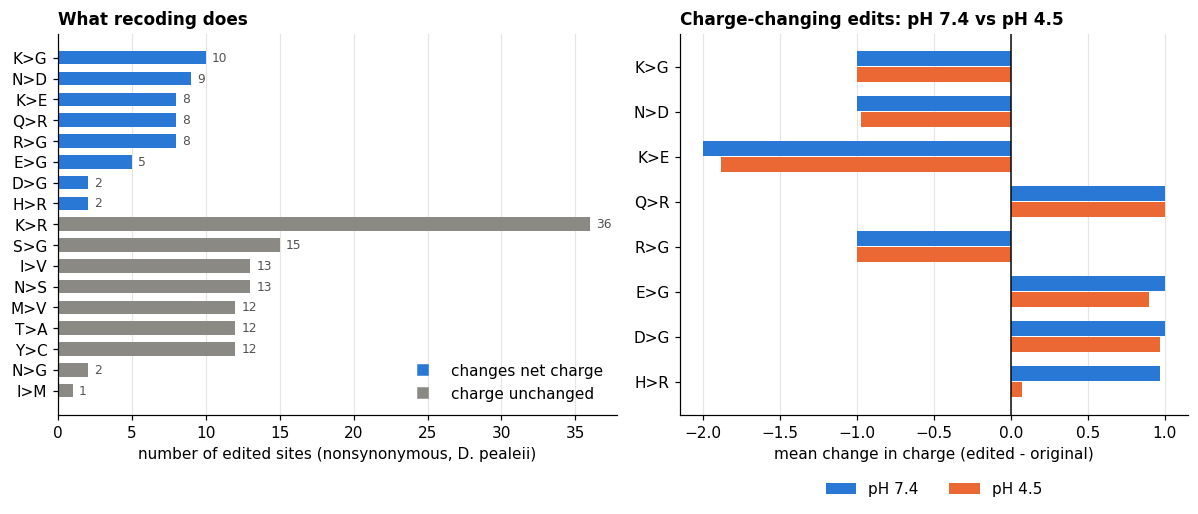

In [32]:
# Figure 5 - what recoding does to charge across the endosomal pH range (main model)
q74, q45 = f"dq_{mt_}_7.4", f"dq_{mt_}_4.5"
g = ns.groupby("subst").agg(n=("subst", "size"), q74=(q74, "mean"), q45=(q45, "mean"))
g["changes"] = g["q74"].abs() >= 0.1
g = g.sort_values(["changes", "n"], ascending=[False, False])
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), gridspec_kw={"width_ratios": [1.1, 1]})
ax = axes[0]; gg = g.iloc[::-1]
ax.barh(gg.index, gg["n"].to_numpy(float), color=[BLUE if c else GREY for c in gg["changes"]], height=0.65)
for y, n in enumerate(gg["n"]):
    ax.text(n + 0.4, y, str(int(n)), va="center", fontsize=8, color="#52514e")
ax.set_xlabel("number of edited sites (nonsynonymous, D. pealeii)"); ax.set_title("What recoding does", loc="left"); ax.grid(axis="y", visible=False)
ax.legend(handles=[Line2D([], [], marker="s", color=BLUE, ls="", label="changes net charge"),
                   Line2D([], [], marker="s", color=GREY, ls="", label="charge unchanged")], frameon=False, loc="lower right")
ax = axes[1]; gc = g[g["changes"]].iloc[::-1]; y = np.arange(len(gc))
ax.barh(y + 0.18, gc["q74"].to_numpy(float), 0.34, color=BLUE, label="pH 7.4")
ax.barh(y - 0.18, gc["q45"].to_numpy(float), 0.34, color=ORANGE, label="pH 4.5")
ax.set_yticks(y); ax.set_yticklabels(gc.index); ax.axvline(0, color="#0b0b0b", lw=1)
ax.set_xlabel("mean change in charge (edited - original)"); ax.set_title("Charge-changing edits: pH 7.4 vs pH 4.5", loc="left")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2); ax.grid(axis="y", visible=False)
fig.tight_layout(); fig.savefig(FIG_DIR / "fig5_cephalopod_charge.png"); plt.show()

Figure 5 shows what recoding does to charge. The left panel counts my 168 recoding edits by substitution. The 52 that change the net charge are in blue, led by K>G (10), N>D (9), K>E (8), Q>R (8) and R>G (8), and the 116 that leave it unchanged are in grey, mostly K>R (36) and swaps between neutral residues. In the right panel, the charge changes are almost the same at pH 7.4 and pH 4.5, in whole units set by the amino acid swap, and only H>R clearly depends on pH (+0.97 at pH 7.4, +0.07 at pH 4.5).

## 6. Future work
### 6.1 First look at my AlphaFold models

Surprise, surprise burial was the feature that mattered, and AlphaFold models of the squid proteins could provide it for my edited sites. So AlphaFold is the obvious next step, but I treat it as future work and not as a result, because using it properly needs three more things. 

First, my training burial was computed with all the chains of each complex present, while an AlphaFold model is a single chain, so I would need to recompute the training burial from single chains to put both on the same scale. Second, using the new burial feature means a second evaluation on the held-out cut and PKAD-2, which I have already used once, so it would have to be reported as a second, disclosed evaluation and not as my main result. Third, I would need models of the unedited proteins as well, to compare the original and edited residues. In this section I only take a first look at the models I have, to see whether they are usable.

I probably will not do this and put myself through all of this again. Because if I am going to rely on these AlphaFold models, I can just use softwares that have already been developed by other labs (PROKPka, ENCoM, DFI). I don't need to go through all of this. For my next pipeline, I will use the hanguel language project. 

In [33]:
# Future work, first look: what do my AlphaFold models of the edited proteins contain?
if not AF_DIR.is_dir():
    print("AlphaFold folder not found - skipped:", AF_DIR)
else:
    ref = {}
    name = None
    for line_ in open(FASTA):
        line_ = line_.strip()
        if line_.startswith(">"):
            name = line_[1:]; ref[name] = ""
        elif name:
            ref[name] += line_
    fwd = CodonTable.unambiguous_rna_by_id[1].forward_table          # every amino-acid change ADAR can make in one codon
    AI = set()
    for cod, aa in fwd.items():
        apos = [i for i, nt in enumerate(cod) if nt == "A"]
        for k in range(1, len(apos) + 1):
            for sub in itertools.combinations(apos, k):
                new = "".join("G" if i in sub else nt for i, nt in enumerate(cod))
                if new in fwd and fwd[new] != aa:
                    AI.add((aa, fwd[new]))
    al = PairwiseAligner(mode="global", match_score=2, mismatch_score=-1, open_gap_score=-5, extend_gap_score=-0.5)

    def read_model(path):
        parser = MMCIFParser(QUIET=True) if str(path).lower().endswith(".cif") else PDBParser(QUIET=True)
        ch = next(iter(parser.get_structure("m", str(path))[0]))
        res_ = [r for r in ch if r.id[0] == " " and "CA" in r]
        return "".join(seq1(r.get_resname(), undef_code="X") for r in res_), [r["CA"].get_bfactor() for r in res_]

    af_files = [p for p in sorted(list(AF_DIR.rglob("*.cif")) + list(AF_DIR.rglob("*.pdb"))) if "template_hit" not in p.name]
    by_target, others = {}, []
    for p in af_files:
        seq, pl = read_model(p)
        best = max(ref, key=lambda k_: al.score(ref[k_], seq))
        aln = al.align(ref[best], seq)[0]
        ident = 100 * sum(ref[best][a + i] == seq[b + i] for (a, ae), (b, be) in zip(*aln.aligned) for i in range(ae - a)) / len(ref[best])
        (by_target.setdefault(best, []) if ident >= 90 else others).append((p, seq, pl, aln))
    print(f"Prediction files: {len(af_files)} | target proteins: {len(by_target)} | other proteins (partners, < 90% identity): {len(others)} files")
    af_rows, summ = [], []
    for target, models in by_target.items():
        _, seq0, _, aln0 = models[0]
        pls = np.array([m_[2] for m_ in models])
        sites_ = [(a + i, b + i) for (a, ae), (b, be) in zip(*aln0.aligned) for i in range(ae - a) if ref[target][a + i] != seq0[b + i]]
        for ri, mi in sites_:
            af_rows.append({"protein": target.split("|")[0], "ref_pos": ri + 1, "ref_aa": ref[target][ri], "model_aa": seq0[mi],
                            "A_to_I_possible": (ref[target][ri], seq0[mi]) in AI, "pLDDT_mean": pls[:, mi].mean()})
        sub = [r for r in af_rows if r["protein"] == target.split("|")[0]]
        summ.append({"protein": target.split("|")[0], "models": len(models), "mean pLDDT": pls.mean(), "differences": len(sites_),
                     "A-to-I possible": sum(r["A_to_I_possible"] for r in sub),
                     "nonsynonymous edits in Step 1": int(((ed["protein"] == target.split("|")[0]) & ~ed["synonymous"]).sum()),
                     "sites with pLDDT < 70 (%)": 100 * np.mean([r["pLDDT_mean"] < 70 for r in sub]) if sub else np.nan})
    print(pd.DataFrame(summ).round(1).to_string(index=False))
    if af_rows:
        af = pd.DataFrame(af_rows)
        print(f"\nDifferences from the original sequences: {len(af)} ({int(af['A_to_I_possible'].sum())} possible A-to-I changes) "
              f"vs {int((~ed['synonymous']).sum())} nonsynonymous edits in Step 1")
        af.to_csv("af_edit_sites_from_models.csv", index=False)

Prediction files: 65 | target proteins: 8 | other proteins (partners, < 90% identity): 25 files
 protein  models  mean pLDDT  differences  A-to-I possible  nonsynonymous edits in Step 1  sites with pLDDT < 70 (%)
   VPS41       5        85.5           17               17                             17                       11.8
   VPS39       5        88.0            6                6                              6                        0.0
   VPS11       5        87.4           15               15                             17                        0.0
  VPS33A       5        88.7            8                8                              8                        0.0
   VPS18       5        86.2           21               21                             24                        9.5
   VPS16       5        93.2            9                9                              9                       11.1
TGFBRAP1       5        88.7           19               19                           

..

## 7. Discussion

**What worked.** The pipeline did what I wanted from an honest comparison point of view. Splitting by sequence cluster kept related proteins apart, the comparisons are hopefully clear and can be reproduced (fingers crossed), and my main answer about the window (H3) did not change whichever model I tried: ridge, boosting, kNN, pooled or per-type. The window adds about 2% over the residue type on computed labels and about nothing on measured ones. The leakage checks also taught me something. A random split would have made some results look about twice as good as they are (for example kNN, and the yes/no result for His), and a strong baseline, the type average, made the real size of each effect easy to see.

**Why it didn't work as hoped.** I knew the window would likely fail because a residue's pKa depends on its 3D surroundings (how buried it is, salt bridges, helix dipoles), and neighbours in 3D can sit many residues away in the sequence. I was just hoping maybe the simple window would give me something to work with. However, I did not test this directly, but burial, which is a 3D feature, was the only thing that gave a clear gain. That gain was 22% on the computed labels and only about 2% on the measured ones, and I think there are three reasons. PypKa itself is 0.75 pKa units from experiment on average, so there is a ceiling on what a model trained on it can reach. The type averages and my model both sit about 0.6 below the measured values for Asp, Glu and His. And the PKAD-2 residues vary less than the training residues, so there is less to predict. The model also follows PypKa only weakly within a residue type, so it learns just a small part of what PypKa calculates. For my squid edits, about a third (52 of 168) change the net charge, in whole units that come from the amino acid swap itself. Only H>R clearly depends on the pH between 7.4 and 4.5, so whether a recoding shifts pKa as the endosome matures needs the 3D structure.

**Why I won't continue with this approach.** The result is a clear "no" for what I set out to do. Sequence alone cannot tell me how a recoding changes pKa, and the information that does help, burial, needs a 3D structure. Once I have a structure for the squid proteins, it is more direct to run a structure-based pKa calculator (PROPKA or PypKa) on AlphaFold models, accepting its own error, than to train a model to imitate that calculation from sequence. A model like mine could probbaly never be better than the calculation it learns from, and there are too few measured pKa values (76 sequence clusters in PKAD-2) to show a reliable improvement over it. The only thing I can claim here is that the simple route does not work, and that was the point of the assignment to determine.

..

## 8. References
There are things I probably didn't cite. I will go through them after submission and make sure my GitHub contains things probably cited. 

- Reis, P. B. P. A. et al. (2020) PypKa; and the pKPDB database (Reis et al. 2022).
- PKAD-2 database of experimental protein pKa values (Ancona et al. 2023).
- RCSB PDB sequence clusters (MMseqs2, 30% identity) and the RCSB Search API.
- Tien, M. Z. et al. (2013) Maximum allowed solvent accessibilities of residues in proteins. PLoS ONE.
- Shrake, A. & Rupley, J. A. (1973) Environment and exposure to solvent of protein atoms. J. Mol. Biol.
- Biopython (Cock et al. 2009); scikit-learn (Pedregosa et al. 2011); AlphaFold 3 / AlphaFold Server (Abramson et al. 2024).
- Rosenthal Lab, MBL — D. pealeii editing sites and transcriptome.
- Cordis, C. (2018, May 30). Trending Science: Do octopuses come from outer space? CORDIS | European Commission. https://cordis.europa.eu/article/id/123479-trending-science-do-octopuses-come-from-outer-space
- Weldy, C. S., Li, J. B., & Quertermous, T. (2026). Adenosine-to-Inosine (A-to-I) RNA editing by ADAR1 to control RNA sensing in cardiovascular disease. Arteriosclerosis Thrombosis and Vascular Biology, 46(4), e323847. https://doi.org/10.1161/atvbaha.125.323847

In [34]:
# Save the cleaning log
(OUT_DIR / "cleaning_log.txt").write_text("\n".join(LOG))
print(f"Saved {OUT_DIR / 'cleaning_log.txt'} ({len(LOG)} lines) | figures in {FIG_DIR}/ | tables in {OUT_DIR}/")

Saved output/cleaning_log.txt (104 lines) | figures in figures/ | tables in output/
